# **Loan Default Prediction**

### Capstone Project - Practical Data Science (Classification) | Milestone Submission

**Learner:** Shubham Garg
**Program:** MIT Professional Education - Applied AI and Data Science Program
**Dataset:** Home Equity (HMEQ) - 5,960 recent home equity loans

## **Problem Definition**

### **The Context:**

A large share of a retail bank's profit comes from the interest it earns on home loans and home equity lines of credit. The single biggest threat to that profit is the applicant who does not repay the loan. Every loan that becomes a non-performing asset (NPA) cancels the interest that the bank earned on many good loans. The bank therefore has to be judicious about whom it approves.

Today an underwriter studies each application by hand and decides whether to approve it. That process is slow, expensive, inconsistent from one underwriter to another, and vulnerable to human error and bias. Earlier attempts to automate the process used hand-written heuristics. The bank now has data on past loans and their outcomes. With that data, the bank can **learn** the approval decision from evidence instead of opinion. At the same time, the bank can make sure that the new model does not simply replicate the biases of the old manual process.

**Some facts that size the problem.** In the bank's own recent book of 5,960 home equity loans, **1,189 (19.9%) ended in default or serious delinquency**. The current process approved all of them. Those defaulted loans averaged about \$16,900 each, so roughly \$20 million of principal was at risk. We assume that the bank recovers about half through the collateral. On that assumption, the bank lost roughly \$10 million on this book alone. Every ten defaulters that the bank declines saves about \$90,000 at the \$9,000 per defaulter that we use throughout. Every good applicant that the bank wrongly declines costs only the interest margin on one loan, about \$2,000.

**Advantages of solving it.** A reliable, explainable scoring model has four advantages:

1. It cuts credit losses because it stops likely defaulters at the door.
2. It protects revenue because it does not decline good applicants unnecessarily.
3. It makes decisions faster and standardises them, so underwriters spend their time on the genuinely uncertain cases.
4. It gives the bank documented, consistent reasons for every decision. This is both a regulatory requirement and a fairness safeguard.

### **The objective:**

Build a classification model. At the time of application, the model predicts whether an applicant is likely to default on a home equity loan. Use that model to give the bank clear recommendations on which applicant attributes matter most when approving a loan.

The project has several goals, in priority order:

1. **Catch defaulters early** - maximise the share of future defaulters that the model flags at application time (recall on the defaulter class). We maximise recall because a missed defaulter is the costliest error.
2. **Protect good business** - keep the share of wrongly declined good applicants acceptable (precision). Then lower risk does not come at the price of lost revenue.
3. **Stay interpretable** - the Equal Credit Opportunity Act (ECOA) requires this. The bank must be able to give an applicant a specific, defensible reason for an adverse decision. A black box that cannot explain a rejection is not usable in production.
4. **Guide policy** - identify the applicant attributes that matter most. The bank can then tighten its approval rules and data collection even before it deploys a model.

### **The key questions:**

1. What share of past applicants defaulted, and how imbalanced is the problem?
2. Which applicant attributes (credit history, debt burden, loan size, job, loan purpose, property value) separate defaulters from repayers?
3. How should we treat missing information? Is the *absence* of information itself a risk signal?
4. Which modelling technique (linear vs. tree-based vs. ensemble) gives the best trade-off between catching defaulters and wrongly declining good applicants?
5. What is the right measure of success for this business problem, and how do the models compare on it?
6. Which model should the bank adopt, with what settings, and what rules can the bank communicate to applicants and regulators?

### **The problem formulation**:

This is a **supervised binary classification** problem. Each row is a past home equity loan. It has 12 attributes known at application time and a target `BAD` (1 = defaulted or seriously delinquent, 0 = repaid). We will:

- explore and clean the data (missing values, outliers, encoding).
- train a linear model (Logistic Regression) and non-linear models (Decision Tree, Bagging, Random Forest).
- tune the Logistic Regression, the Decision Tree and the Random Forest with cross-validated grid search.
- compare all models on a metric that we choose from the business cost of each type of error. The primary metric is **Recall on the defaulter class**. Precision and F1 are guard-rails so that the bank does not decline too many good applicants.
- choose the final configuration and its decision threshold on the expected cost of the two errors, with repeated out-of-fold predictions on the training rows. The model scores each application before the bank approves it, and the threshold converts that score into a flag.
- propose a final solution design with approve / refer / decline bands around the threshold and an explanation layer that gives a reason for each adverse decision.

## **Data Description:**
The Home Equity dataset (HMEQ) contains baseline and loan performance information for 5,960 recent home equity loans. The target (BAD) is a binary variable that shows whether an applicant ultimately defaulted or was severely delinquent. This adverse outcome occurred in 1,189 cases (20 percent). The dataset records 12 input variables for each applicant.


* **BAD:** 1 = Applicant defaulted on loan, 0 = loan repaid

* **LOAN:** Amount of loan approved.

* **MORTDUE:** Amount due on the existing mortgage.

* **VALUE:** Current value of the property.

* **REASON:** Reason for the loan request. (HomeImp = home improvement, DebtCon= debt consolidation, which means a new loan that repays other liabilities and consumer debts)

* **JOB:** The type of job that loan applicant has such as manager, self, etc.

* **YOJ:** Years at present job.

* **DEROG:** Number of major derogatory reports (which indicates a serious delinquency or late payments).

* **DELINQ:** Number of delinquent credit lines. (A line of credit becomes delinquent when the applicant does not make the minimum required payments 30 to 60 days after the due date.)

* **CLAGE:** Age of the oldest credit line in months.

* **NINQ:** Number of recent credit inquiries.

* **CLNO:** Number of existing credit lines.

* **DEBTINC:** Debt-to-income ratio (all monthly debt payments divided by gross monthly income). Lenders use this number as one way to measure how well the applicant can manage the monthly payments on the money they plan to borrow.

## **Import the necessary libraries and Data**

In [1]:
# Core libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Pre-processing and model selection
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.inspection import permutation_importance
from scipy import stats
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.base import clone

# Metrics
from sklearn.metrics import (classification_report, confusion_matrix, recall_score,
                             precision_score, f1_score, accuracy_score, roc_auc_score,
                             roc_curve, precision_recall_curve, brier_score_loss, cohen_kappa_score)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 1

In [2]:
# Load the dataset
hm = pd.read_csv("../data/hmeq.csv")

# Work on a copy so the raw data stays untouched
data = hm.copy()

## **Data Overview**

- Reading the dataset
- Understanding the shape of the dataset
- Checking the data types
- Checking for missing values
- Checking for duplicated values

In [3]:
# First five rows
data.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,"25,860.000","39,025.000",HomeImp,Other,10.500,0.000,0.000,94.367,1.000,9.000,NaN
1,1,1300,"70,053.000","68,400.000",HomeImp,Other,7.000,0.000,2.000,121.833,0.000,14.000,NaN
2,1,1500,"13,500.000","16,700.000",HomeImp,Other,4.000,0.000,0.000,149.467,1.000,10.000,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,"97,800.000","112,000.000",HomeImp,Office,3.000,0.000,0.000,93.333,0.000,14.000,NaN


In [4]:
# Last five rows
data.tail()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
5955,0,88900,"57,264.000","90,185.000",DebtCon,Other,16.000,0.000,0.000,221.809,0.000,16.000,36.112
5956,0,89000,"54,576.000","92,937.000",DebtCon,Other,16.000,0.000,0.000,208.692,0.000,15.000,35.860
5957,0,89200,"54,045.000","92,924.000",DebtCon,Other,15.000,0.000,0.000,212.280,0.000,15.000,35.557
5958,0,89800,"50,370.000","91,861.000",DebtCon,Other,14.000,0.000,0.000,213.893,0.000,16.000,34.341
5959,0,89900,"48,811.000","88,934.000",DebtCon,Other,15.000,0.000,0.000,219.601,0.000,16.000,34.572


In [5]:
# Print the number of rows and columns
print(f"The dataset has {data.shape[0]:,} rows and {data.shape[1]} columns.")

The dataset has 5,960 rows and 13 columns.


In [6]:
# Data types and non-null counts
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BAD      5960 non-null   int64  
 1   LOAN     5960 non-null   int64  
 2   MORTDUE  5442 non-null   float64
 3   VALUE    5848 non-null   float64
 4   REASON   5708 non-null   str    
 5   JOB      5681 non-null   str    
 6   YOJ      5445 non-null   float64
 7   DEROG    5252 non-null   float64
 8   DELINQ   5380 non-null   float64
 9   CLAGE    5652 non-null   float64
 10  NINQ     5450 non-null   float64
 11  CLNO     5738 non-null   float64
 12  DEBTINC  4693 non-null   float64
dtypes: float64(9), int64(2), str(2)
memory usage: 605.4 KB


**Observations:**

- There are **5,960 loans and 13 columns**: the target `BAD` plus 12 input attributes.
- `BAD` and `LOAN` are integers with no gaps. `REASON` and `JOB` are text (categorical). All other inputs are numeric floats.
- `DEROG`, `DELINQ`, `NINQ` and `CLNO` have the float type but are really **counts** (whole numbers). We can analyse them both as numbers and as ordered categories.
- Every input column except `LOAN` has fewer than 5,960 non-null values, so **missing values are widespread**. We must handle them before modelling.

In [7]:
# Count and percentage of missing values in each column
missing = pd.DataFrame({
    "missing_count": data.isnull().sum(),
    "missing_pct": (data.isnull().mean() * 100).round(2)
}).sort_values("missing_pct", ascending=False)
missing

,missing_count,missing_pct
DEBTINC,1267,21.260
DEROG,708,11.880
DELINQ,580,9.730
MORTDUE,518,8.690
YOJ,515,8.640
NINQ,510,8.560
CLAGE,308,5.170
JOB,279,4.680
REASON,252,4.230
CLNO,222,3.720


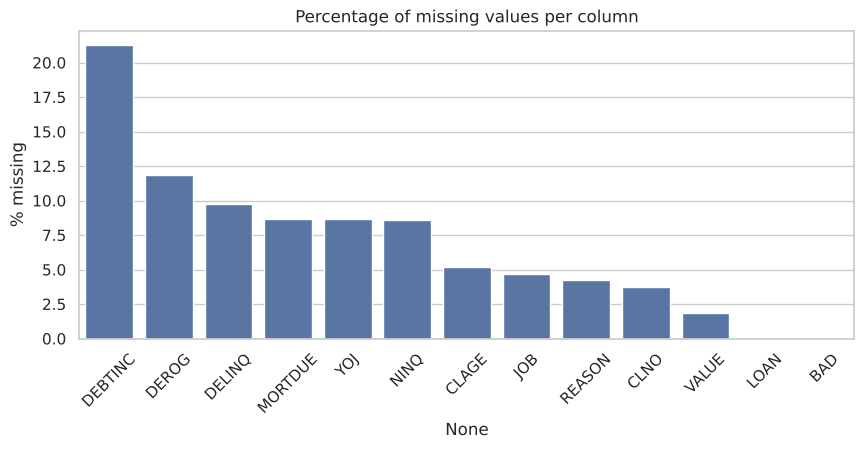

In [8]:
# Plot the percentage of missing values in each column
plt.figure(figsize=(10, 4))
sns.barplot(x=missing.index, y=missing["missing_pct"], color="#4C72B0")
plt.title("Percentage of missing values per column")
plt.ylabel("% missing")
plt.xticks(rotation=45)
plt.show()

**Observations:**

- `DEBTINC` (debt-to-income ratio) is missing in **21.3%** of the applications, by far the highest. This is the most important affordability measure a lender has, so its absence is suspicious in itself. We will test later whether missingness is linked to default.
- `DEROG` (11.9%), `DELINQ` (9.7%), `MORTDUE` (8.7%), `YOJ` (8.6%) and `NINQ` (8.6%) have moderate gaps.
- `JOB`, `REASON`, `CLAGE`, `CLNO` and `VALUE` are missing in fewer than 5.2% of rows.
- No column has enough missing values to justify removing it. Removing rows is also not an option. If we removed any row with at least one gap, we would discard more than 40% of the data. We will **impute** values and **keep a flag** for every imputed cell.

In [9]:
# Rows with a missing value in at least one column, and rows where every input except LOAN is blank
rows_with_na = data.isnull().any(axis=1).sum()
all_blank = data.drop(columns=["BAD", "LOAN"]).isnull().all(axis=1).sum()
print(f"Rows with at least one missing value : {rows_with_na:,} ({rows_with_na/len(data):.1%})")
print(f"Rows where every input except LOAN is blank : {all_blank}")

Rows with at least one missing value : 2,596 (43.6%)
Rows where every input except LOAN is blank : 2


In [10]:
# Duplicate rows
print("Number of duplicated rows:", data.duplicated().sum())

Number of duplicated rows: 0


**Observations:**

- **44% of applications have at least one blank field**, which shows that removing rows is not a viable option.
- Two applications have no information at all beyond the loan amount. We keep them: the missing-value flags that we create later will carry the information that the applicant supplied nothing.
- There are **no duplicate rows**, so we do not need to remove duplicates.

In [11]:
# Convert object columns and the target to the 'category' data type (saves memory, makes intent explicit)
for col in ["REASON", "JOB"]:
    data[col] = data[col].astype("category")
data["BAD"] = data["BAD"].astype("category")
data.dtypes

BAD        category
LOAN          int64
MORTDUE     float64
VALUE       float64
REASON     category
JOB        category
YOJ         float64
DEROG       float64
DELINQ      float64
CLAGE       float64
NINQ        float64
CLNO        float64
DEBTINC     float64
dtype: object

## Summary Statistics

In [12]:
# Summary statistics for the numerical columns
data.describe().T

,count,mean,std,min,25%,50%,75%,max
LOAN,"5,960.000","18,607.970","11,207.480","1,100.000","11,100.000","16,300.000","23,300.000","89,900.000"
MORTDUE,"5,442.000","73,760.817","44,457.609","2,063.000","46,276.000","65,019.000","91,488.000","399,550.000"
VALUE,"5,848.000","101,776.049","57,385.775","8,000.000","66,075.500","89,235.500","119,824.250","855,909.000"
YOJ,"5,445.000",8.922,7.574,0.000,3.000,7.000,13.000,41.000
DEROG,"5,252.000",0.255,0.846,0.000,0.000,0.000,0.000,10.000
DELINQ,"5,380.000",0.449,1.127,0.000,0.000,0.000,0.000,15.000
CLAGE,"5,652.000",179.766,85.810,0.000,115.117,173.467,231.562,"1,168.234"
NINQ,"5,450.000",1.186,1.729,0.000,0.000,1.000,2.000,17.000
CLNO,"5,738.000",21.296,10.139,0.000,15.000,20.000,26.000,71.000
DEBTINC,"4,693.000",33.780,8.602,0.524,29.140,34.818,39.003,203.312


In [13]:
# Summary statistics for the categorical columns (including the target)
data.describe(include="category").T

,count,unique,top,freq
BAD,5960,2,0,4771
REASON,5708,2,DebtCon,3928
JOB,5681,6,Other,2388


In [14]:
# Unique values and their share for each categorical column
for col in ["BAD", "REASON", "JOB"]:
    print(f"Value share in {col}:")
    print((data[col].value_counts(normalize=True) * 100).round(2).to_string())
    print("-" * 40)

Value share in BAD:
BAD
0   80.050
1   19.950
----------------------------------------
Value share in REASON:
REASON
DebtCon   68.820
HomeImp   31.180
----------------------------------------
Value share in JOB:
JOB
Other     42.030
ProfExe   22.460
Office    16.690
Mgr       13.500
Self       3.400
Sales      1.920
----------------------------------------


- **Observations from Summary Statistics**

**Target**
- 19.95% of the loans ended in default (1,189 of 5,960). The classes are **imbalanced roughly 4:1**, so accuracy alone would be misleading (a model that approves everyone is 80% "accurate" and useless).

**Loan and property amounts**
- `LOAN` ranges from \$1,100 to \$89,900 with a median of \$16,300 and mean of \$18,608. The mean is above the median, so the distribution is right-skewed with a tail of large loans.
- `MORTDUE` (median \$65,019) and `VALUE` (median \$89,236) are also right-skewed. `VALUE` has a maximum of \$855,909, which is an extreme outlier relative to the 75th percentile (\$119,824).

**Employment and credit history**
- `YOJ` (years at present job): median 7 years, maximum 41 years. A quarter of applicants have 3 years or less at their present job.
- `DEROG` and `DELINQ` are zero for at least 75% of applicants (the 75th percentile is 0). A small group with many derogatory reports or delinquent lines drives their means (0.25 and 0.45). These are the applicants a lender worries about.
- `CLAGE` (age of oldest credit line): median 173 months (about 14.5 years). A maximum of 1,168 months (97 years) is not plausible and is an outlier.
- `NINQ` (recent credit inquiries): median 1, maximum 17.
- `CLNO` (number of credit lines): median 20, maximum 71.

**Debt burden**
- `DEBTINC`: median 34.8%, 75th percentile 39.0%. The maximum of 203% is physically implausible (debt payments twice the income). The 25th-75th range (29% to 39%) is tight, so the few applicants far above 40% are easy to notice.

**Categorical**
- `REASON`: 2 categories. Debt consolidation is 68.8% of stated reasons.
- `JOB`: 6 categories. "Other" is the largest (42%), then ProfExe (22.5%) and Office (16.7%). Sales (1.9%) and Self-employed (3.4%) are small groups.

## **Exploratory Data Analysis (EDA) and Visualization**

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Leading Questions**:
1. What is the range of values for the loan amount variable "LOAN"?
2. How does the distribution of years at present job "YOJ" vary across the dataset?
3. How many unique categories are there in the REASON variable?
4. What is the most common category in the JOB variable?
5. Is there a relationship between the REASON variable and the proportion of applicants who defaulted on their loan?
6. Do applicants who default have a significantly different loan amount compared to those who repay their loan?
7. Is there a correlation between the value of the property and the loan default rate?
8. Do applicants who default have a significantly different mortgage amount compared to those who repay their loan?

The univariate analysis answers questions 1 to 4. The bivariate analysis answers questions 5 to 8. A summary of the answers is in the last cell of this notebook (Summary of answers to the leading questions).

### **Univariate Analysis**

In [15]:
# Helper: a box plot above a histogram for one numerical column
def histogram_boxplot(feature, figsize=(12, 6), bins=None, title=None):
    '''Boxplot on top of a histogram for one numerical feature, with mean (green dashed) and median (black) lines.'''
    f, (ax_box, ax_hist) = plt.subplots(nrows=2, sharex=True,
                                        gridspec_kw={"height_ratios": (0.25, 0.75)},
                                        figsize=figsize)
    sns.boxplot(x=feature, ax=ax_box, showmeans=True, color="violet")
    sns.histplot(x=feature, ax=ax_hist, bins=bins if bins else "auto", color="#4C72B0")
    ax_hist.axvline(np.nanmean(feature), color="green", linestyle="--", label="mean")
    ax_hist.axvline(np.nanmedian(feature), color="black", linestyle="-", label="median")
    ax_hist.legend()
    ax_box.set(xlabel="")
    f.suptitle(title or feature.name, fontsize=13)
    plt.show()

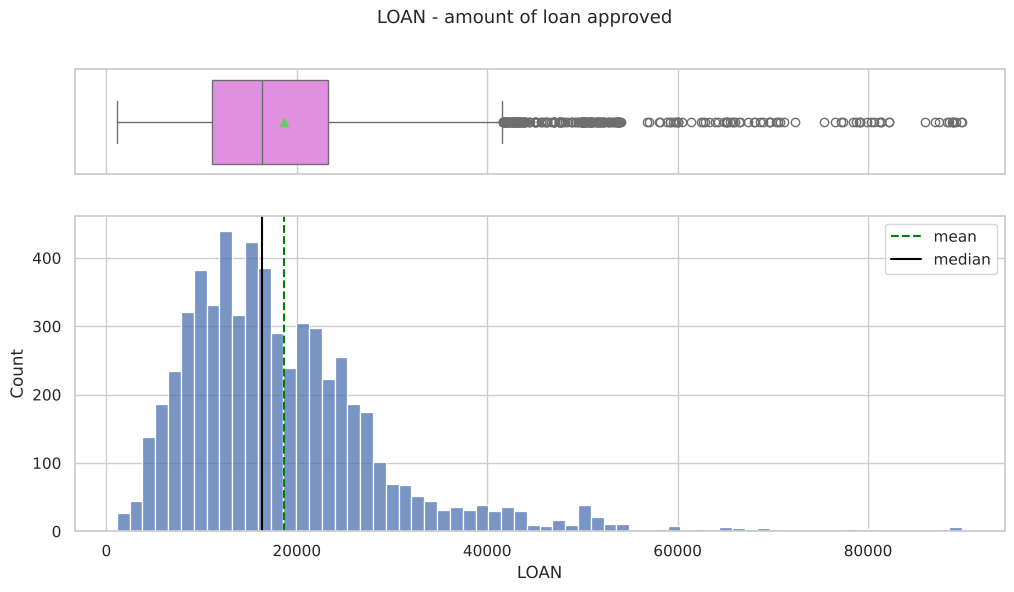

LOAN ranges from $1,100 to $89,900; median $16,300, mean $18,608


In [16]:
# Distribution and outliers of LOAN, with its range, median and mean
histogram_boxplot(data["LOAN"], title="LOAN - amount of loan approved")
print(f"LOAN ranges from ${data['LOAN'].min():,.0f} to ${data['LOAN'].max():,.0f}; "
      f"median ${data['LOAN'].median():,.0f}, mean ${data['LOAN'].mean():,.0f}")

**Insights - LOAN (Q1):**
- Loan amounts range from **\$1,100 to \$89,900**. Half of all loans are below \$16,300 and 75% are below \$23,300.
- The distribution is right-skewed with a long tail. Loans above about \$41,000 appear as outliers on the boxplot. Those are genuine large loans, not data errors, so we will keep them for tree models and only cap them for the linear model.

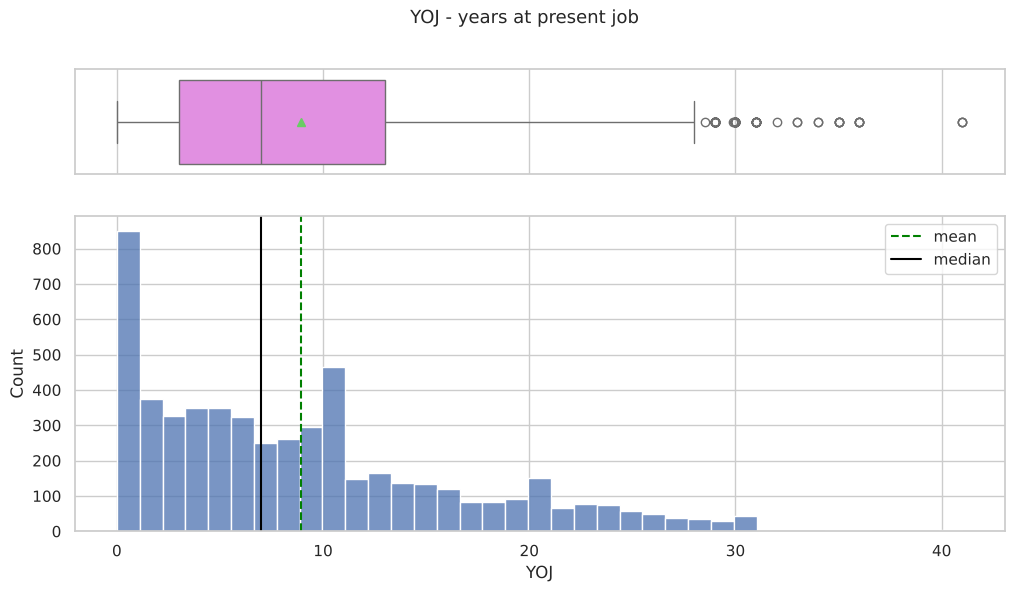

In [17]:
# Distribution and outliers of YOJ
histogram_boxplot(data["YOJ"], title="YOJ - years at present job")

**Insights - YOJ (Q2):**
- Years at the present job is **right-skewed**. The most common values are 0 to 5 years, the median is 7 years and the mean is about 9 years.
- There is a long tail of long-tenured applicants (above about 28 years, up to 41) that the boxplot marks as outliers. These are plausible and we keep them.
- Job tenure is a mild stability signal. We will check in the bivariate section whether short tenure is linked to default.

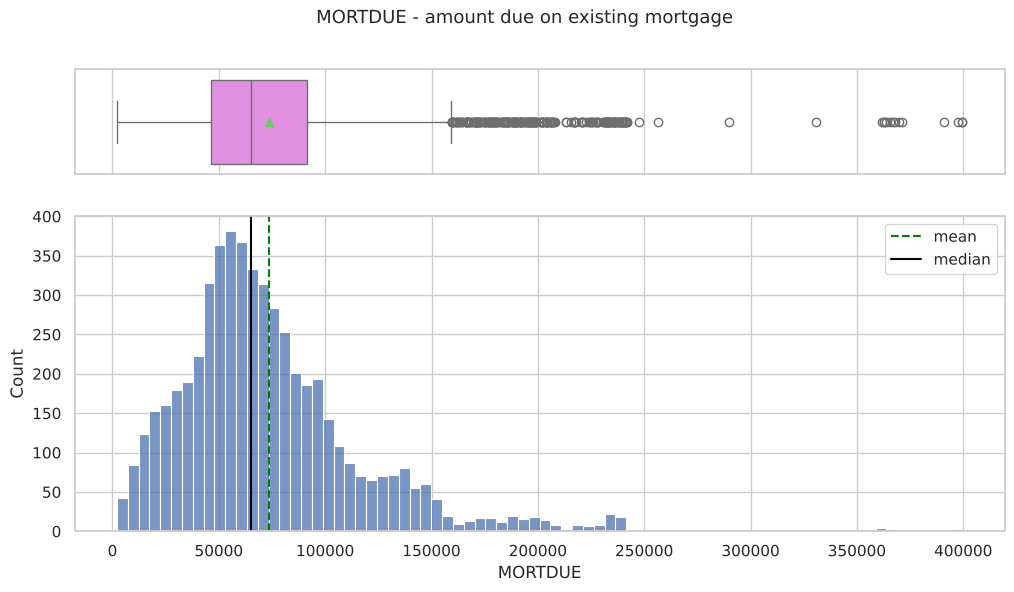

In [18]:
# Distribution and outliers of MORTDUE
histogram_boxplot(data["MORTDUE"], title="MORTDUE - amount due on existing mortgage")

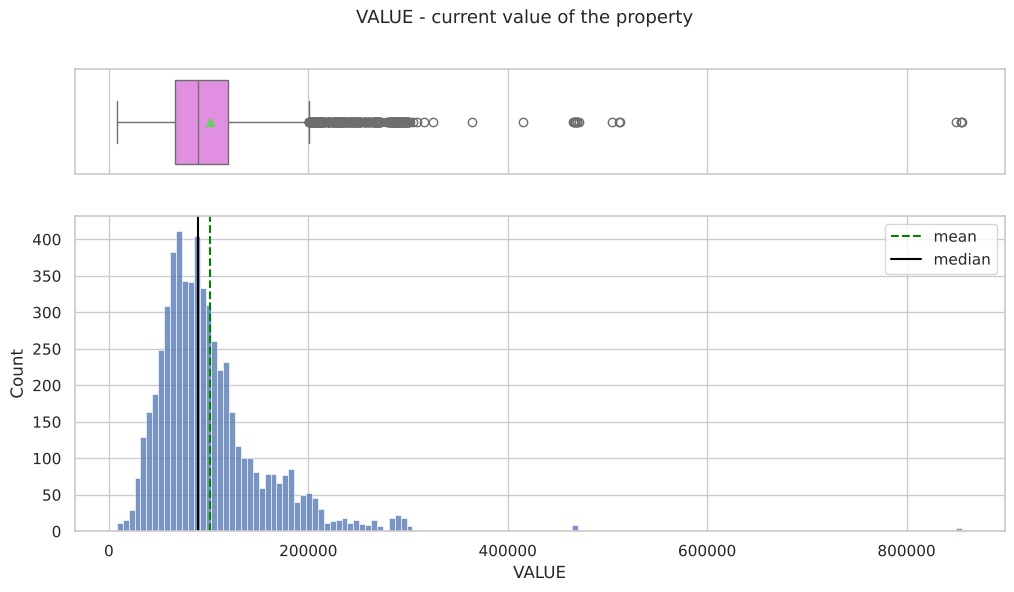

In [19]:
# Distribution and outliers of VALUE
histogram_boxplot(data["VALUE"], title="VALUE - current value of the property")

**Insights - MORTDUE and VALUE:**
- Both are right-skewed with a bulk of properties between \$50,000 and \$150,000 and a small number of very expensive properties (VALUE up to \$855,909).
- Because the two variables describe the same asset, they should be strongly correlated. The correlation heatmap later shows this (r = 0.88). This matters for the logistic regression, where highly correlated inputs make coefficients unstable.

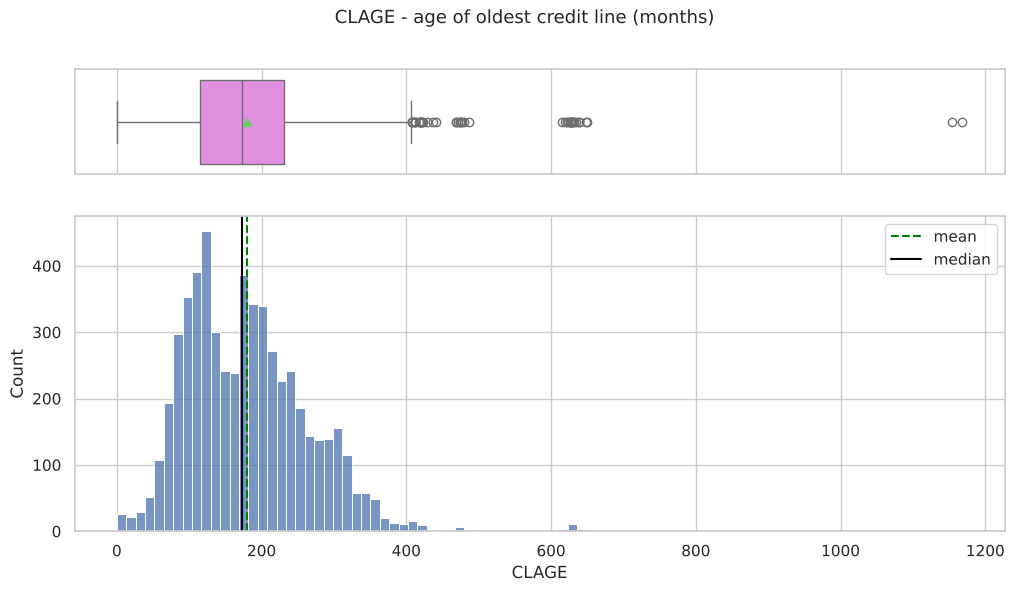

In [20]:
# Distribution and outliers of CLAGE
histogram_boxplot(data["CLAGE"], title="CLAGE - age of oldest credit line (months)")

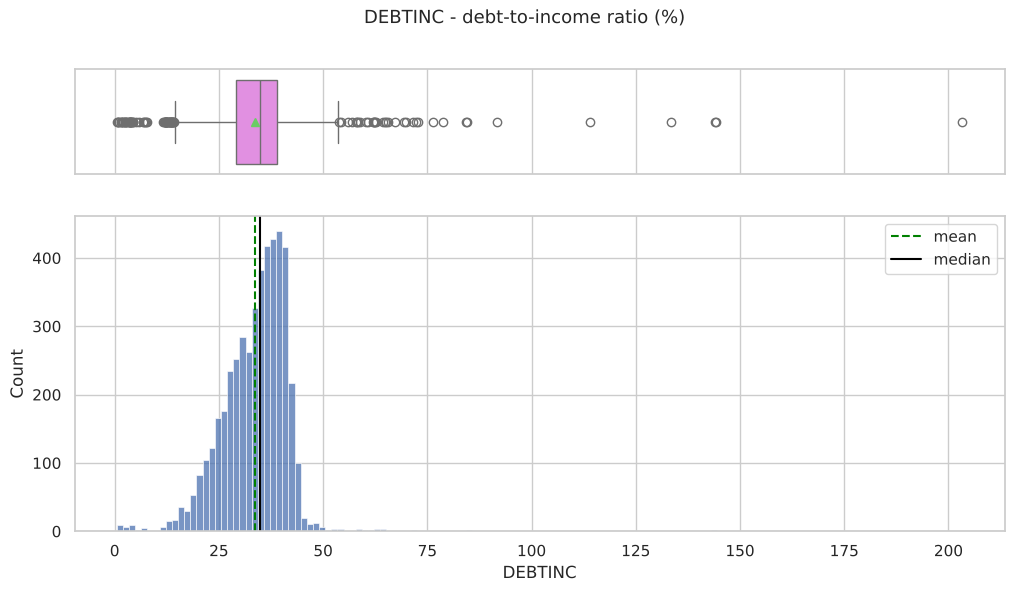

In [21]:
# Distribution and outliers of DEBTINC
histogram_boxplot(data["DEBTINC"], title="DEBTINC - debt-to-income ratio (%)")

**Insights - CLAGE and DEBTINC:**
- `CLAGE` is roughly bell-shaped around 170-180 months (about 15 years of credit history) with a right tail. A handful of values above 600 months (50+ years) and a maximum of 1,168 months are not credible. We will cap them for the linear model.
- `DEBTINC` is tightly concentrated between 25% and 42%. Very few applicants have a recorded ratio above 45%. The maximum of 203% is an impossible value. Note that this plot only shows the 79% of applicants with a recorded ratio.

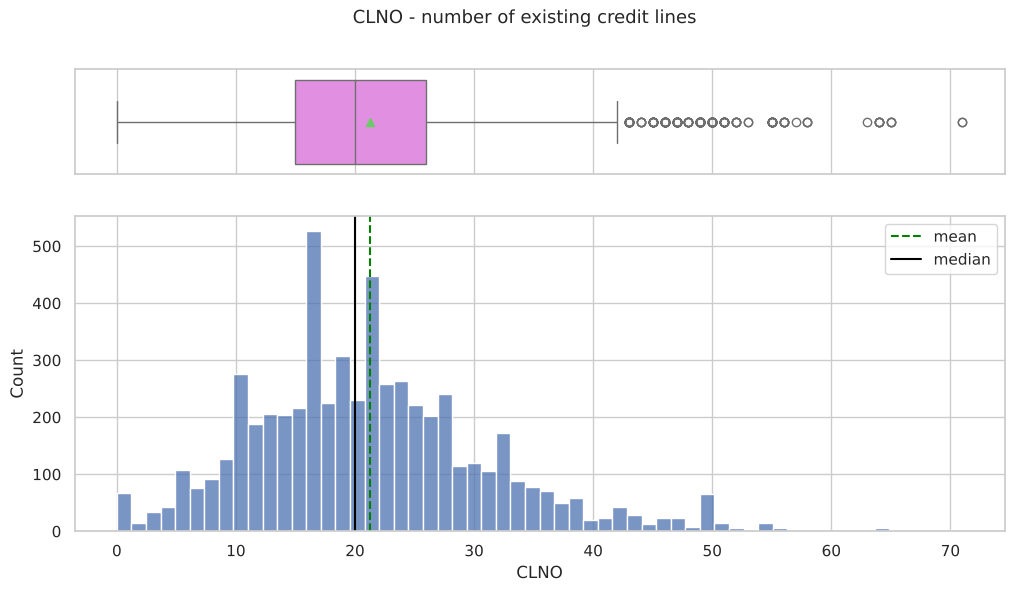

In [22]:
# Distribution and outliers of CLNO
histogram_boxplot(data["CLNO"], title="CLNO - number of existing credit lines")

**Insights - CLNO:**
- Number of credit lines is approximately normal, centred around 20 lines, with a few applicants holding more than 45 lines.

#### Count-type variables (DEROG, DELINQ, NINQ)

These are whole-number counts where most applicants are at zero, so bar charts are more informative than histograms.

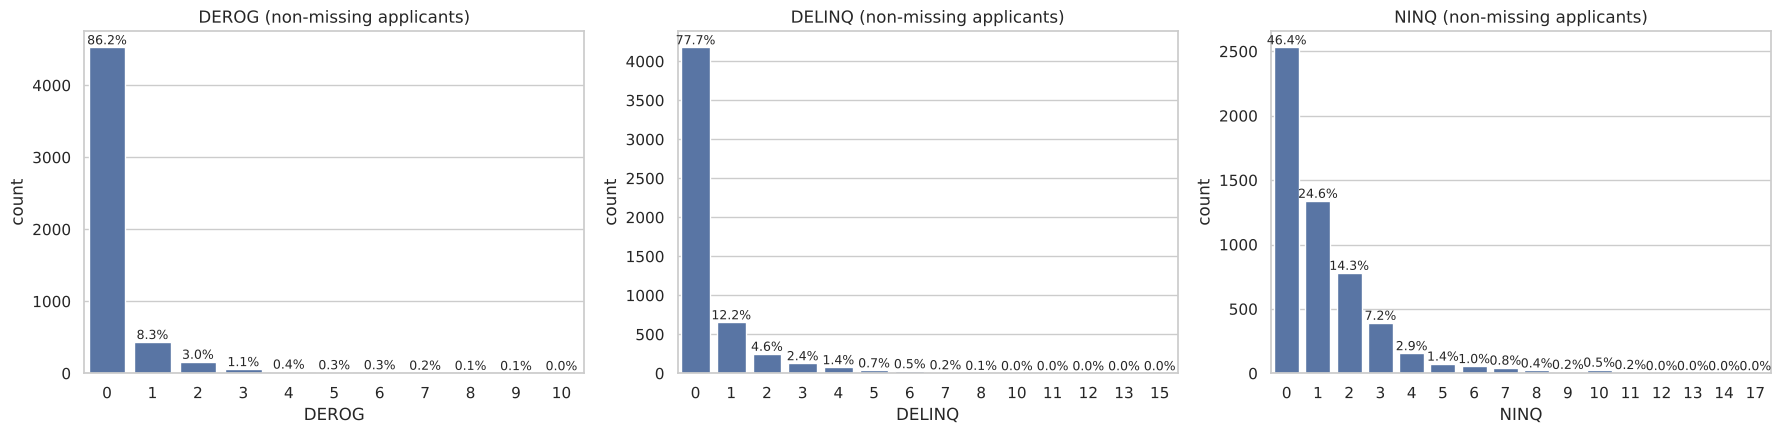

In [23]:
# Helper: write the percentage of the total on each bar
def perc_on_bar(ax, total):
    '''Annotate bars with the percentage of the total.'''
    for p in ax.patches:
        pct = f"{100 * p.get_height() / total:.1f}%"
        ax.annotate(pct, (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["DEROG", "DELINQ", "NINQ"]):
    s = data[col].dropna().astype(int)
    sns.countplot(x=s, ax=ax, color="#4C72B0")
    perc_on_bar(ax, len(s))
    ax.set_title(f"{col} (non-missing applicants)")
plt.tight_layout()
plt.show()

**Insights - DEROG, DELINQ, NINQ:**
- **Among applicants with a record, 86% have zero major derogatory reports** and 78% have zero delinquent credit lines. The minority with one or more is small but, as the bivariate analysis will show, carries a very high default rate.
- Recent credit inquiries are more dispersed. Of applicants with a record, 46% have none, 25% have one, 14% have two, and a tail have five or more. Many recent inquiries can signal an applicant who actively seeks credit under financial stress.

#### Categorical variables (BAD, REASON, JOB)

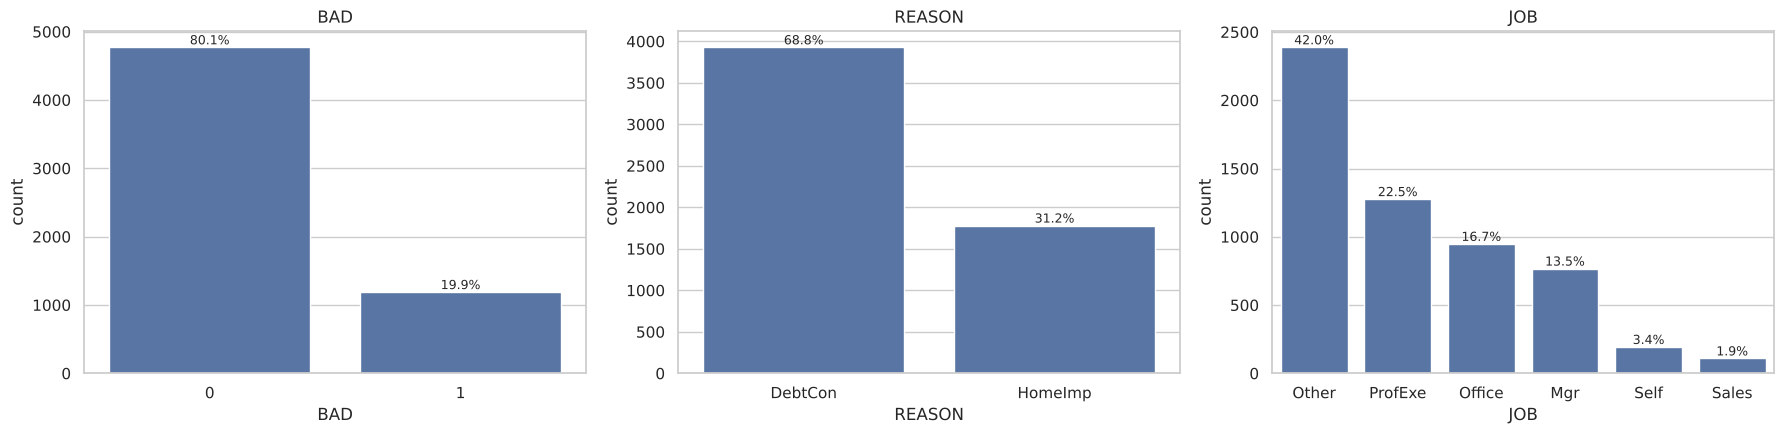

In [24]:
# Plot the class shares of BAD, REASON and JOB
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["BAD", "REASON", "JOB"]):
    s = data[col].dropna()
    order = s.value_counts().index
    sns.countplot(x=s, order=order, ax=ax, color="#4C72B0")
    perc_on_bar(ax, len(s))
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Insights - BAD, REASON, JOB (Q3, Q4):**
- **Target:** applicants repaid 80% of loans and defaulted on 20%. The imbalance is moderate. We will handle it inside the models: class weights when we build the individual models, and the decision threshold when we choose the final one. The success metric is recall, not accuracy.
- **REASON has 2 unique categories.** Debt consolidation (69%) is far more common than home improvement (31%).
- **JOB has 6 unique categories and "Other" is the most common (42%)**, then professional/executive (22%) and office workers (17%). Sales (2%) and self-employed (3%) are small groups, so we should read their default rates with care.

### **Bivariate Analysis**

#### Numerical variables vs the target (BAD)

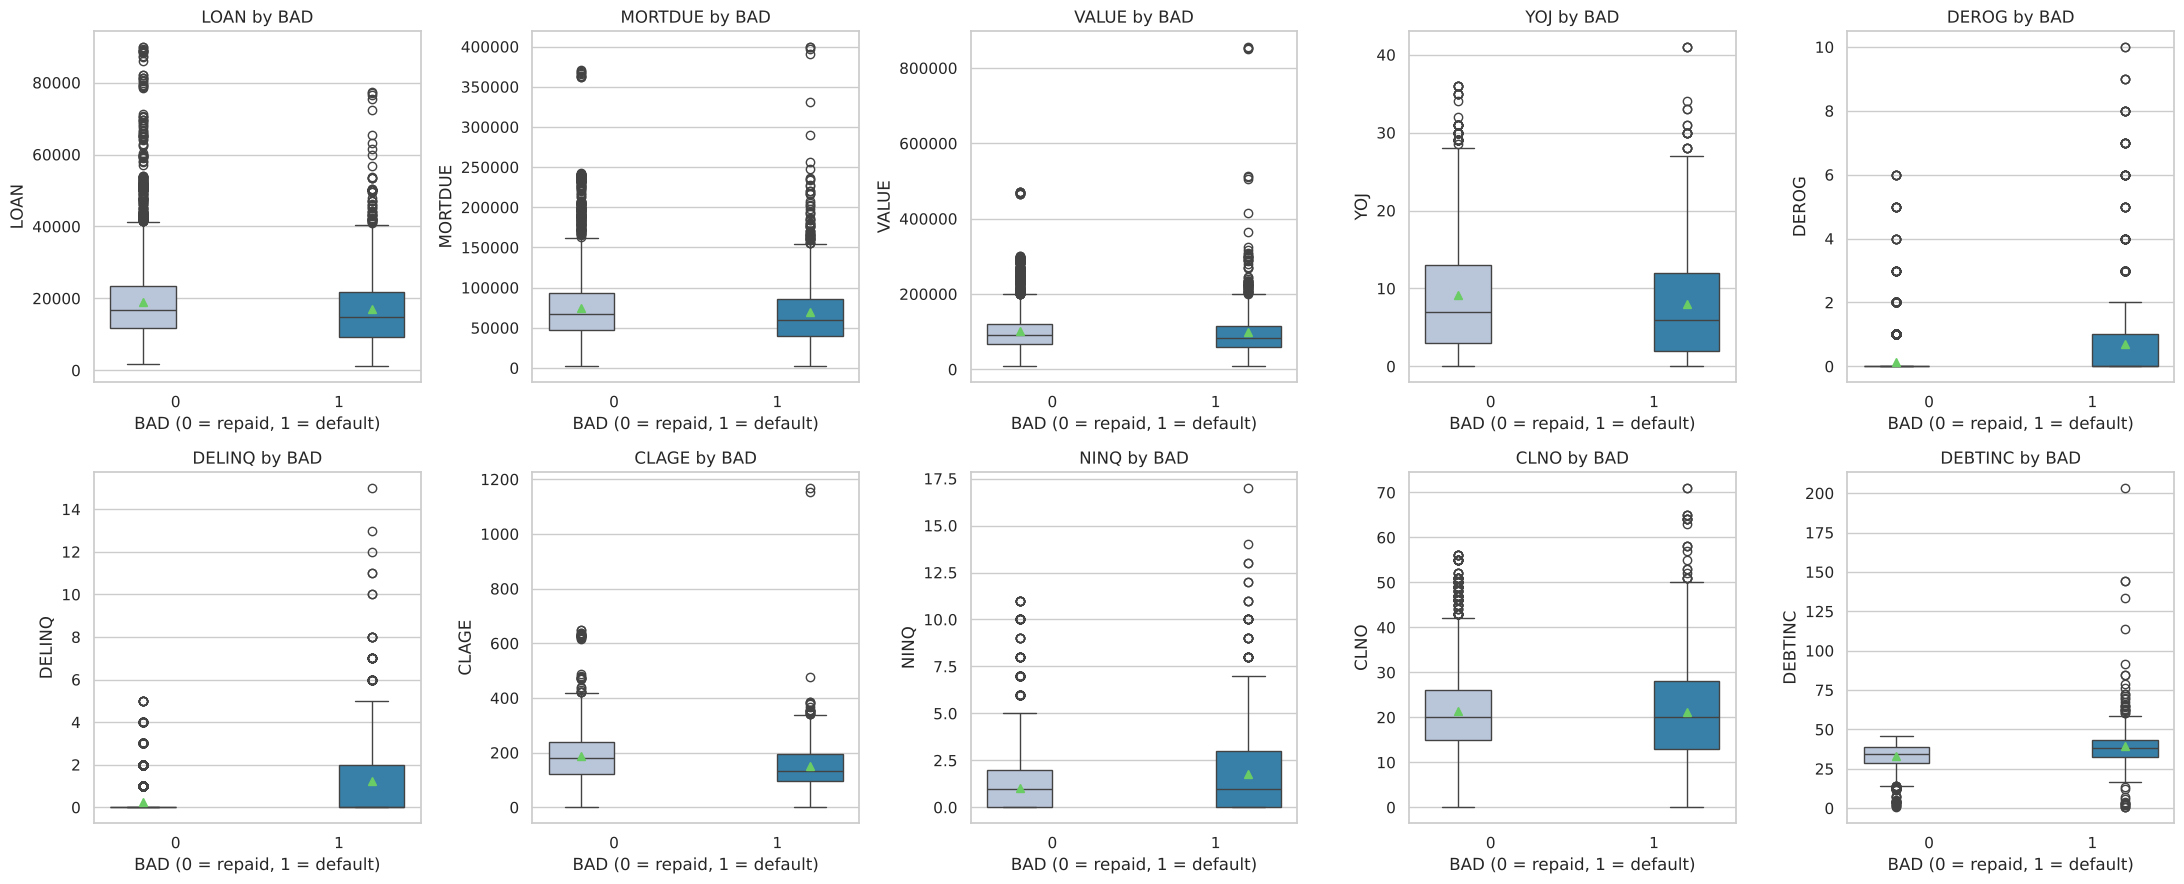

In [25]:
# Compare each numerical variable for repaid (0) and defaulted (1) loans
num_cols = ["LOAN", "MORTDUE", "VALUE", "YOJ", "DEROG", "DELINQ", "CLAGE", "NINQ", "CLNO", "DEBTINC"]

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x=data["BAD"], y=data[col], hue=data["BAD"], legend=False, ax=ax, palette="PuBu", showmeans=True)
    ax.set_title(f"{col} by BAD")
    ax.set_xlabel("BAD (0 = repaid, 1 = default)")
plt.tight_layout()
plt.show()

In [26]:
# Mean and median of each numerical variable by target class
data.groupby("BAD", observed=True)[num_cols].agg(["mean", "median"]).T

BAD                      0          1
LOAN    mean    19,028.107 16,922.119
        median  16,900.000 14,900.000
MORTDUE mean    74,829.249 69,460.453
        median  66,839.000 60,279.000
VALUE   mean   102,595.921 98,172.846
        median  90,659.000 82,000.000
YOJ     mean         9.155      8.028
        median       7.000      6.000
DEROG   mean         0.134      0.708
        median       0.000      0.000
DELINQ  mean         0.245      1.229
        median       0.000      0.000
CLAGE   mean       187.002    150.190
        median     180.416    132.867
NINQ    mean         1.033      1.783
        median       1.000      1.000
CLNO    mean        21.317     21.211
        median      20.000     20.000
DEBTINC mean        33.253     39.388
        median      34.542     38.080

**Insights - numerical variables vs BAD (Q6, Q7, Q8):**

- **LOAN (Q6):** Defaulters borrowed *less* on average (mean \$16,922, median \$14,900) than repayers (mean \$19,028, median \$16,900). The difference is real but modest. Loan size by itself is not a strong separator. The default rate by loan band (next chart) shows the pattern more clearly.
- **VALUE (Q7):** Defaulters have slightly lower property values (median \$82,000 vs \$90,659). The correlation between `VALUE` and `BAD` is weak (r = -0.03), so property value alone does not predict default. Property value matters in combination with the mortgage balance and the loan size.
- **MORTDUE (Q8):** Defaulters have a somewhat lower outstanding mortgage (median \$60,279 vs \$66,839). This is again a modest difference.
- **DEROG and DELINQ** separate the two groups most strongly: defaulters average 0.71 derogatory reports vs 0.13, and 1.23 delinquent lines vs 0.25. These are **5x higher** among defaulters.
- **CLAGE:** Defaulters have a materially shorter credit history (median 133 months vs 180 months). A long, established credit record is protective.
- **NINQ:** Defaulters made more recent inquiries (mean 1.78 vs 1.03).
- **DEBTINC:** Defaulters carry a higher debt burden (median 38.1% vs 34.5%). The defaulter boxplot has a long upper tail where most of the extreme ratios sit.
- **YOJ and CLNO** show little difference between the two groups.

In [27]:
# Are the differences statistically significant? Mann-Whitney U tests for the amounts (robust to skew),
# chi-square tests of independence for the categorical variables.
rows = []
for col in ["LOAN", "MORTDUE", "VALUE", "DEBTINC", "CLAGE"]:
    a = data.loc[data["BAD"] == 1, col].dropna(); b = data.loc[data["BAD"] == 0, col].dropna()
    rows.append({"variable": col, "median_defaulters": a.median(), "median_repayers": b.median(),
                 "test": "Mann-Whitney U", "p_value": stats.mannwhitneyu(a, b).pvalue})
for col in ["REASON", "JOB"]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(data[col], data["BAD"]))
    rows.append({"variable": col, "median_defaulters": np.nan, "median_repayers": np.nan, "test": "Chi-square", "p_value": p})
pd.DataFrame(rows).style.format({"median_defaulters": "{:,.1f}", "median_repayers": "{:,.1f}", "p_value": "{:.2e}"})

,variable,median_defaulters,median_repayers,test,p_value
0,LOAN,"14,900.0","16,900.0",Mann-Whitney U,5.87e-17
1,MORTDUE,"60,279.0","66,839.0",Mann-Whitney U,1.61e-08
2,VALUE,"82,000.0","90,659.0",Mann-Whitney U,4.45e-09
3,DEBTINC,38.1,34.5,Mann-Whitney U,1.11e-23
4,CLAGE,132.9,180.4,Mann-Whitney U,1.45e-44
5,REASON,nan,nan,Chi-square,4.58e-03
6,JOB,nan,nan,Chi-square,3.31e-16


**Insights - significance tests (Q5, Q6, Q8):**
- The differences in `LOAN`, `MORTDUE` and `VALUE` between defaulters and repayers are **statistically significant** (p < 0.001 in each case). With 5,960 loans, the tests can detect even modest gaps. However, the differences are **small in practical terms**: medians differ by \$2,000 to \$9,000 on amounts of \$15,000 to \$90,000. `DEBTINC` and `CLAGE` differ both significantly and materially.
- `REASON` is related to default (chi-square p = 0.005), but the effect is weak (22.2% vs 19.0%). `JOB` is strongly related (p < 0.001).
- Statistical significance tells us the pattern is real. The band charts below tell us where the pattern is large enough for the bank to act.

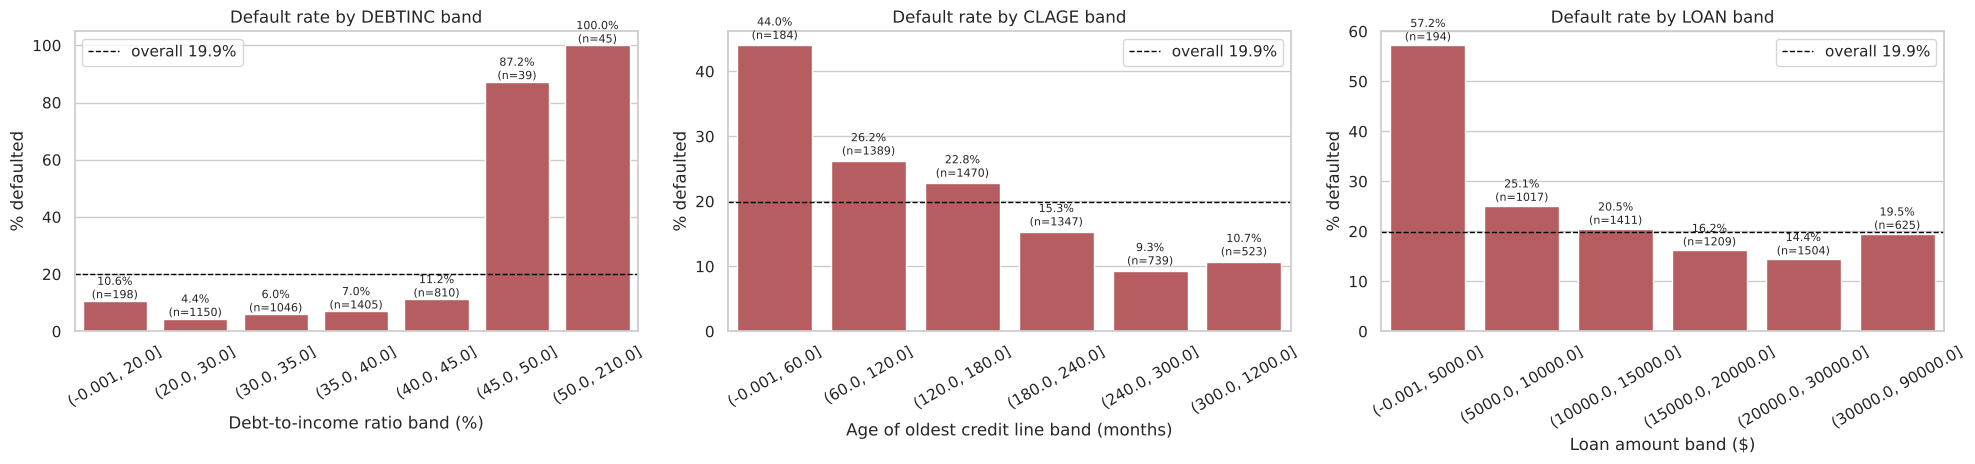

In [28]:
# Helper: default rate and applicant count for each band of a numerical column
def default_rate_by_band(col, bins, labels=None):
    '''Default rate and applicant count per band of a numerical column (missing values excluded).'''
    banded = pd.cut(data[col], bins=bins, labels=labels, include_lowest=True)
    tab = data.groupby(banded, observed=True)["BAD"].agg(
        default_rate=lambda s: (s.astype(int).mean() * 100).round(1),
        applicants="count")
    return tab

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
specs = [
    ("DEBTINC", [0, 20, 30, 35, 40, 45, 50, 210], "Debt-to-income ratio band (%)"),
    ("CLAGE",   [0, 60, 120, 180, 240, 300, 1200], "Age of oldest credit line band (months)"),
    ("LOAN",    [0, 5000, 10000, 15000, 20000, 30000, 90000], "Loan amount band ($)"),
]
for ax, (col, bins, label) in zip(axes, specs):
    tab = default_rate_by_band(col, bins)
    sns.barplot(x=tab.index.astype(str), y=tab["default_rate"], ax=ax, color="#C44E52")
    for i, (rate, n) in enumerate(zip(tab["default_rate"], tab["applicants"])):
        ax.text(i, rate + 1, f"{rate}%\n(n={n})", ha="center", fontsize=8)
    ax.axhline(19.9, color="black", linestyle="--", linewidth=1, label="overall 19.9%")
    ax.set_title(f"Default rate by {col} band"); ax.set_xlabel(label); ax.set_ylabel("% defaulted")
    ax.tick_params(axis="x", rotation=30); ax.legend()
plt.tight_layout()
plt.show()

**Insights - default rate by band:**

- **DEBTINC is a cliff, not a slope.** Applicants with a recorded ratio between 20% and 40% default only 4% to 7% of the time, well below the 20% average. The small group below 20% is at 11%. Between 40% and 45% the rate is 11%. **Above 45% it jumps to 87%, and above 50% it jumps to 100%**. A debt-to-income threshold around 45% is therefore a natural, explainable approval rule.
- **CLAGE protects.** Applicants whose oldest credit line is under 5 years old default 44% of the time. The rate falls steadily to 9% to 11% once the credit history is longer than 20 years.
- **Small loans are the riskiest.** Loans under \$5,000 default 57% of the time, against 14% to 20% for loans above \$15,000. Financially stretched applicants may request small loans, or the bank may already limit its exposure to weaker applicants. Either way, a small requested amount is not a sign of low risk.

#### Categorical and count variables vs the target (BAD)

In [29]:
# Helper: counts and stacked default-rate bars for a categorical column
def stacked_plot(x, title=None):
    '''Cross-tab counts and a normalised stacked bar chart of BAD by a categorical column.'''
    tab_counts = pd.crosstab(x, data["BAD"], margins=True)
    print(tab_counts)
    print("-" * 60)
    tab = pd.crosstab(x, data["BAD"], normalize="index")
    ax = tab.plot(kind="bar", stacked=True, figsize=(9, 4), color=["#4C72B0", "#C44E52"])
    for i, (idx, row) in enumerate(tab.iterrows()):
        ax.text(i, 1.01, f"{row[1]*100:.0f}% bad", ha="center", fontsize=9)
    ax.legend(title="BAD", loc="upper left", bbox_to_anchor=(1, 1))
    ax.set_ylabel("share of applicants")
    ax.set_title(title or f"BAD by {x.name}")
    plt.show()

BAD         0     1   All
REASON                   
DebtCon  3183   745  3928
HomeImp  1384   396  1780
All      4567  1141  5708
------------------------------------------------------------


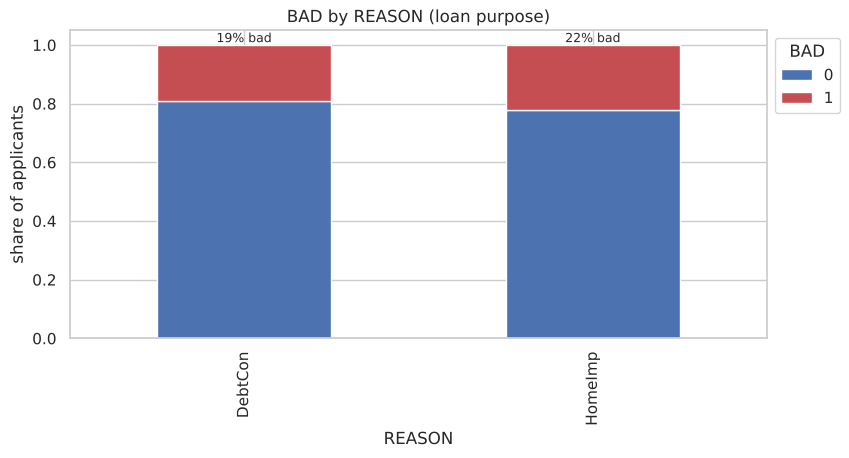

In [30]:
# Default rate for each loan purpose
stacked_plot(data["REASON"], "BAD by REASON (loan purpose)")

**Insights - REASON vs BAD (Q5):**
- Home-improvement loans default slightly more often (**22.2%**) than debt-consolidation loans (**19.0%**). There is a relationship, but it is weak: a 3-point difference around a 20% base rate. Loan purpose on its own should not drive approval decisions.

BAD         0     1   All
JOB                      
Mgr       588   179   767
Office    823   125   948
Other    1834   554  2388
ProfExe  1064   212  1276
Sales      71    38   109
Self      135    58   193
All      4515  1166  5681
------------------------------------------------------------


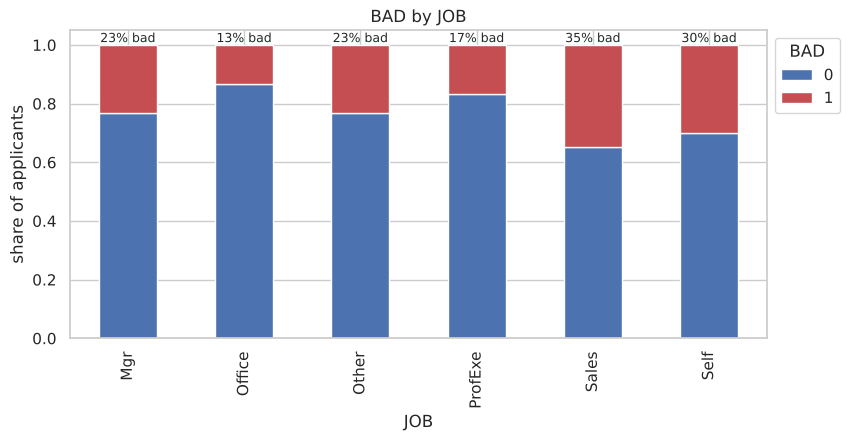

In [31]:
# Default rate for each occupation
stacked_plot(data["JOB"], "BAD by JOB")

**Insights - JOB vs BAD:**
- Default risk varies clearly by occupation. **Sales (34.9%)** and **Self-employed (30.1%)** applicants default at 1.5x to 1.75x the average, consistent with more variable income. **Office workers (13.2%)** and **professionals/executives (16.6%)** are the safest groups. Managers (23.3%) and "Other" (23.2%) sit slightly above average.
- The Sales and Self groups are small (109 and 193 applicants). The model should therefore use occupation as a supporting signal, not a primary one. Note also that the bank must use occupation carefully under fair-lending rules. Occupation is not a protected attribute, but the bank should monitor it for proxy effects.

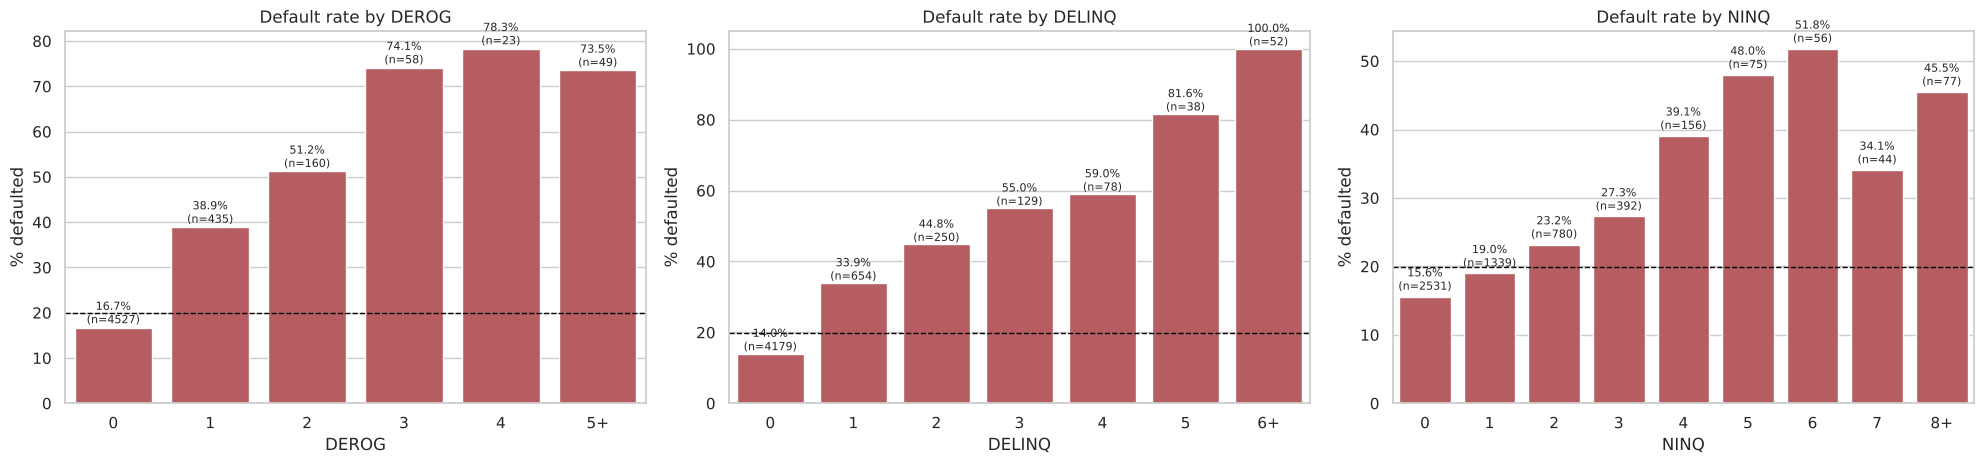

In [32]:
# Default rate by number of derogatory reports, delinquent lines and recent inquiries (capped for readability)
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
for ax, (col, cap) in zip(axes, [("DEROG", 5), ("DELINQ", 6), ("NINQ", 8)]):
    s = data[col].clip(upper=cap)
    tab = data.groupby(s, observed=True)["BAD"].agg(
        default_rate=lambda v: (v.astype(int).mean() * 100).round(1), applicants="count")
    labels = [f"{int(i)}+" if i == cap else f"{int(i)}" for i in tab.index]
    sns.barplot(x=labels, y=tab["default_rate"], ax=ax, color="#C44E52")
    for i, (rate, n) in enumerate(zip(tab["default_rate"], tab["applicants"])):
        ax.text(i, rate + 1, f"{rate}%\n(n={n})", ha="center", fontsize=8)
    ax.axhline(19.9, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Default rate by {col}"); ax.set_ylabel("% defaulted"); ax.set_xlabel(col)
plt.tight_layout()
plt.show()

**Insights - credit-history counts vs BAD:**

- **DEROG:** Applicants with no derogatory report default 16.7% of the time. **One report raises this to 39%, and two reports raise it to 51%. Three or four reports raise it to about 75%, and five or more reports raise it to 73%.** The small groups at the top are noisy, but every one of them is far above average.
- **DELINQ:** The pattern is the same and even steeper. The default rate is 14% with no delinquent line, 34% with one, 45% with two, 55% with three, and **100% with six or more**.
- **NINQ:** Default risk rises with recent inquiries: 16% at zero, 23% at two, 39% at four, and about 46% at five or more (252 applicants). The small groups at five and above are noisy (34% to 52%).
- All three rates rise with the count. They are easy to explain to an applicant ("we declined your application because you have two delinquent credit lines"). They are exactly the kind of evidence that the ECOA requires.

#### Does missing information predict default?

In [33]:
# Default rate when a field is missing vs when it is present
rows = []
for col in data.columns.drop("BAD"):
    if data[col].isnull().any():
        is_na = data[col].isnull()
        rows.append({
            "column": col,
            "missing_rows": int(is_na.sum()),
            "default_rate_when_missing_%": round(data.loc[is_na, "BAD"].astype(int).mean() * 100, 1),
            "default_rate_when_present_%": round(data.loc[~is_na, "BAD"].astype(int).mean() * 100, 1),
        })
missing_vs_bad = pd.DataFrame(rows).sort_values("default_rate_when_missing_%", ascending=False)
missing_vs_bad

,column,missing_rows,default_rate_when_missing_%,default_rate_when_present_%
1,VALUE,112,93.800,18.500
10,DEBTINC,1267,62.000,8.600
7,CLAGE,308,25.300,19.700
9,CLNO,222,23.900,19.800
0,MORTDUE,518,20.500,19.900
2,REASON,252,19.000,20.000
8,NINQ,510,14.700,20.400
4,YOJ,515,12.600,20.600
6,DELINQ,580,12.400,20.800
5,DEROG,708,12.300,21.000


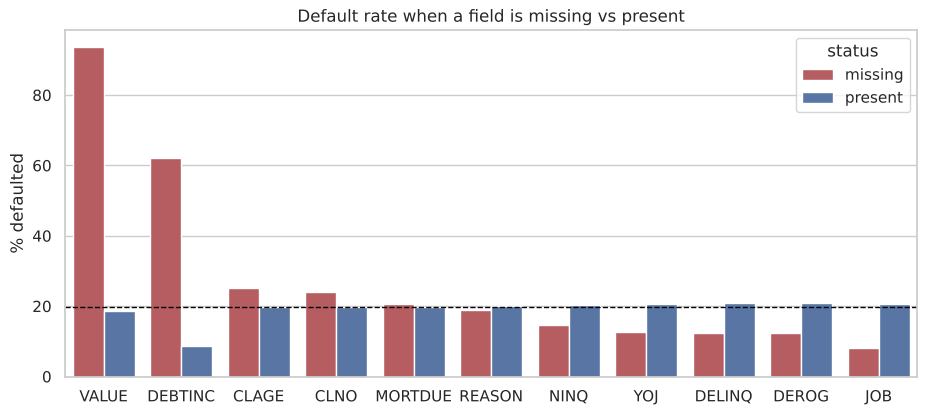

In [34]:
# Plot the default rate when a field is missing and when it is present
plt.figure(figsize=(11, 4.5))
m = missing_vs_bad.melt(id_vars="column", value_vars=["default_rate_when_missing_%", "default_rate_when_present_%"],
                        var_name="status", value_name="default_rate")
m["status"] = m["status"].str.replace("default_rate_when_", "").str.replace("_%", "")
sns.barplot(data=m, x="column", y="default_rate", hue="status", palette=["#C44E52", "#4C72B0"])
plt.axhline(19.9, color="black", linestyle="--", linewidth=1)
plt.title("Default rate when a field is missing vs present")
plt.ylabel("% defaulted"); plt.xlabel("")
plt.show()

**Insights - missingness as a signal (a key finding):**

- **When DEBTINC is missing, 62% of applicants defaulted. When it is present, only 8.6% did.** A missing debt-to-income ratio is the single strongest risk indicator in the whole dataset. In practice, applicants whose income the bank could not check, or who did not supply it, are far riskier than those with a checked ratio.
- **When VALUE is missing, 94% defaulted** (112 applicants). An application without a property valuation is almost always bad.
- Missing `CLAGE` (25%) and `CLNO` (24%) are mildly riskier than average.
- The opposite holds for `DEROG`, `DELINQ`, `YOJ`, `NINQ` and `JOB`: when these are missing the default rate is *lower* (8% to 15%). This probably reflects how the data was recorded (for example, "no record found" stored as blank for good applicants).
- **Implication for pre-processing:** we must not simply fill these gaps with the median and continue. We will **add a binary "was missing" flag for every column with gaps** so the models can learn from the absence of information. Then we will impute the values.

#### Two numerical variables together

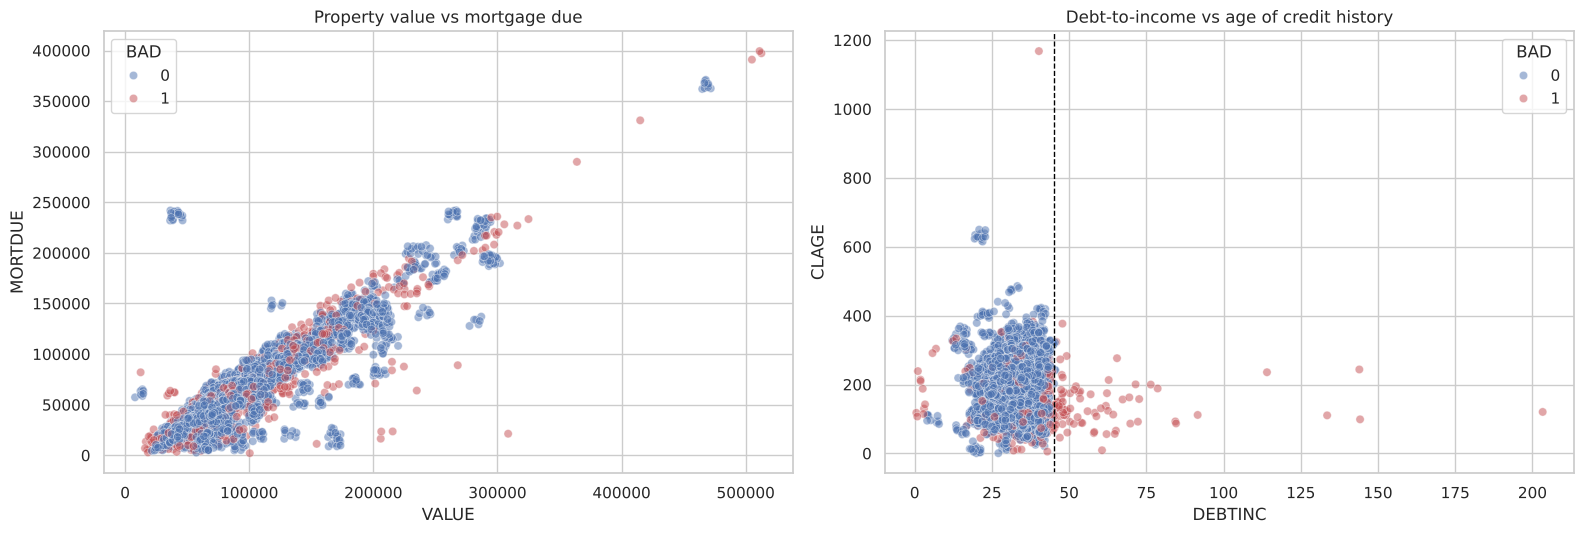

In [35]:
# Plot two pairs of numerical variables, coloured by the outcome
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(data=data, x="VALUE", y="MORTDUE", hue="BAD", alpha=0.5, ax=axes[0], palette=["#4C72B0", "#C44E52"])
axes[0].set_title("Property value vs mortgage due")
sns.scatterplot(data=data, x="DEBTINC", y="CLAGE", hue="BAD", alpha=0.5, ax=axes[1], palette=["#4C72B0", "#C44E52"])
axes[1].axvline(45, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Debt-to-income vs age of credit history")
plt.tight_layout()
plt.show()

**Insights:**
- `VALUE` and `MORTDUE` lie close to a straight line: the mortgage balance is typically 60% to 80% of the property value. Defaulters are scattered throughout rather than clustered, which shows that these two amounts alone do not separate the classes.
- In the right-hand chart almost every applicant to the right of the 45% debt-to-income line is a defaulter, regardless of credit history length. To the left, defaulters are concentrated in the lower part of the chart (short credit history). The two variables complement each other.

### **Multivariate Analysis**

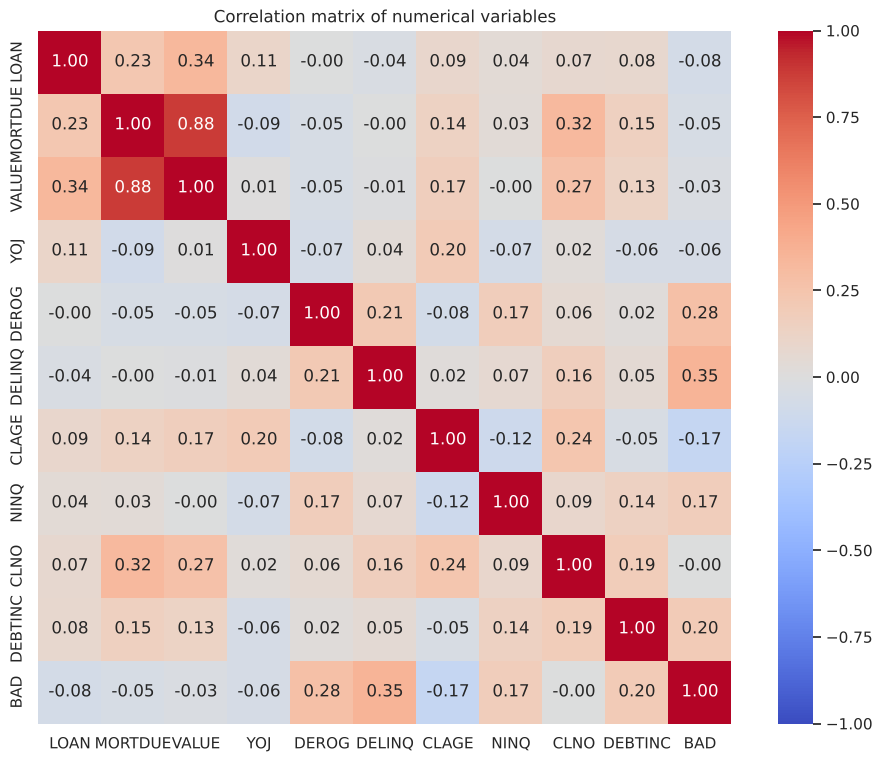

In [36]:
# Correlation heatmap for numerical variables (target included as a number)
corr_df = data[num_cols].copy()
corr_df["BAD"] = data["BAD"].astype(int)
corr = corr_df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix of numerical variables")
plt.show()

**Insights - correlations:**
- The only strong correlation between inputs is **MORTDUE vs VALUE (0.88)**. For the logistic regression this is multicollinearity: the two coefficients will share the same information and individually be less reliable. Tree-based models are unaffected.
- The moderate relationships are `CLNO` with `MORTDUE`/`VALUE` (0.27 to 0.32, wealthier applicants hold more credit lines) and `LOAN` with `VALUE` (0.34).
- Correlations with the target are weak to moderate: `DELINQ` (0.35) and `DEROG` (0.28) are the highest, followed by `DEBTINC` (0.20), `NINQ` (0.17) and `CLAGE` (-0.17). The count variables are close to linear in the default rate. However, the band charts showed that `DEBTINC`, `CLAGE` and `LOAN` act through thresholds and cliffs that a single correlation coefficient understates. This is an early hint that **tree-based models, which capture thresholds naturally, should outperform a purely linear model on the raw inputs**.

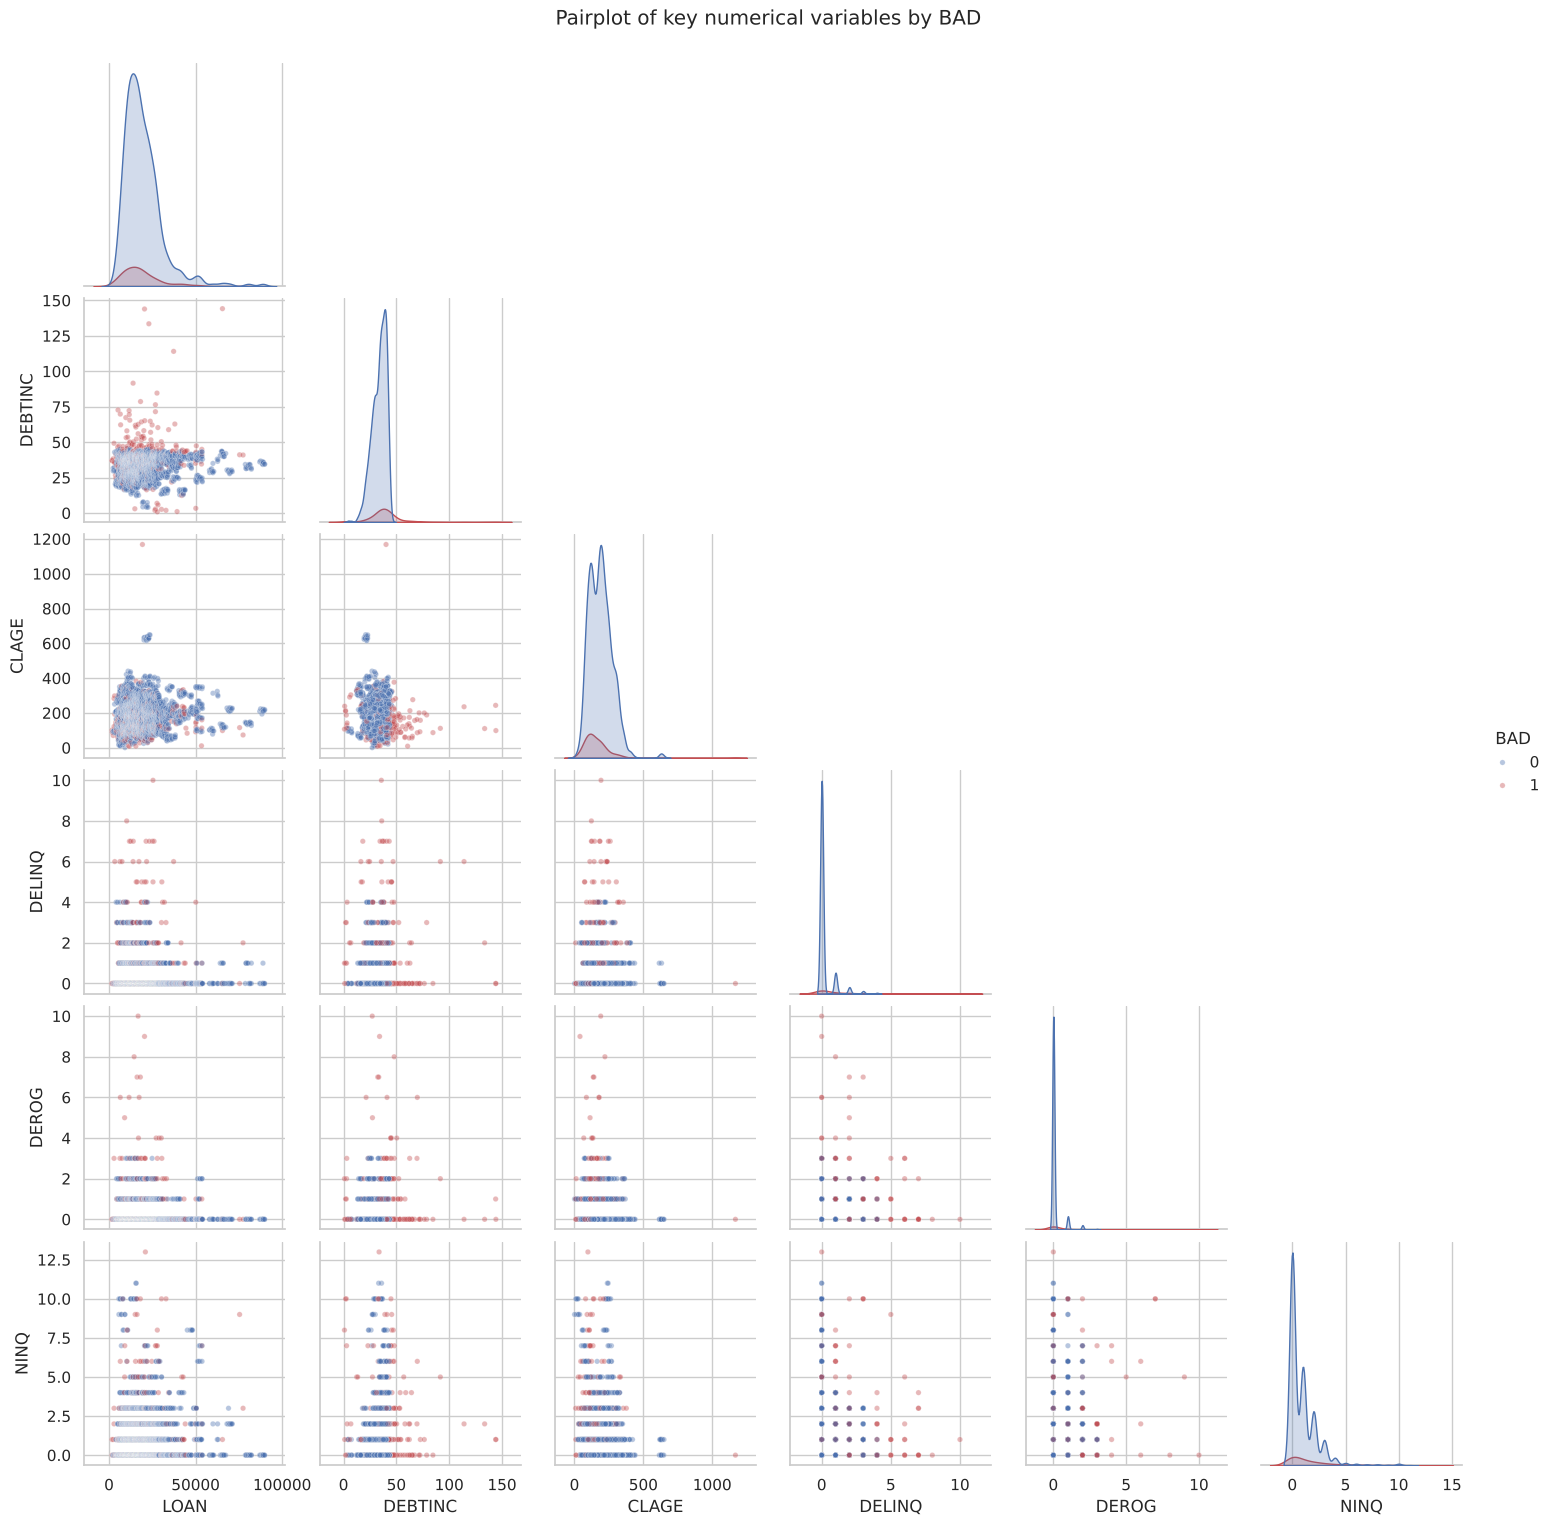

In [37]:
# Pairplot of the most informative numerical variables, coloured by the target
sns.pairplot(data[["LOAN", "DEBTINC", "CLAGE", "DELINQ", "DEROG", "NINQ", "BAD"]].dropna(),
             hue="BAD", palette=["#4C72B0", "#C44E52"], diag_kind="kde", corner=True,
             plot_kws={"alpha": 0.4, "s": 15})
plt.suptitle("Pairplot of key numerical variables by BAD", y=1.02)
plt.show()

**Insights - pairplot:**
- The density curves on the diagonal show that defaulters (red) have visibly shorter `CLAGE`, higher `DEBTINC` and heavier tails on `DELINQ`, `DEROG` and `NINQ`.
- No single pair of variables separates the classes cleanly. The separation comes from combinations, which again favours tree-based models.

#### Two categorical variables and the target: occupation and loan purpose

The bivariate analysis looked at occupation and loan purpose one at a time. Here we cross them, to check whether the risk of a loan purpose depends on the occupation. Applicants with a missing `JOB` or `REASON` are not in this chart.

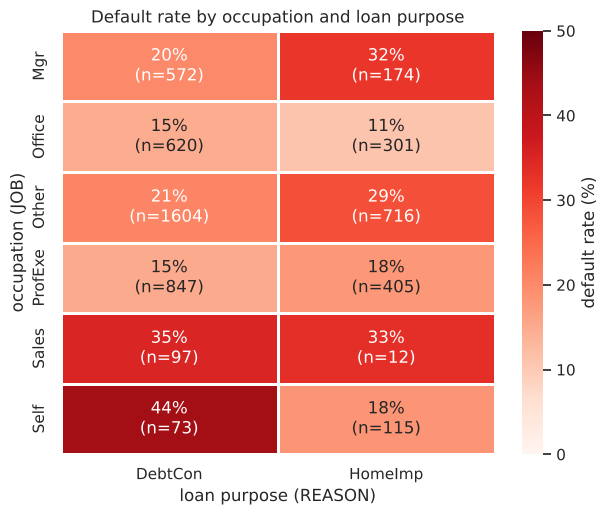

default_rate_%         applicants        
REASON         DebtCon HomeImp    DebtCon HomeImp
JOB                                              
Mgr             20.300  32.200        572     174
Office          14.800  11.000        620     301
Other           20.800  28.600       1604     716
ProfExe         15.200  18.000        847     405
Sales           35.100  33.300         97      12
Self            43.800  18.300         73     115

In [38]:
# Default rate by occupation and loan purpose (two categorical variables and the target)
bad_int = data["BAD"].astype(int)
job_rate = bad_int.groupby([data["JOB"], data["REASON"]], observed=True).mean().unstack() * 100
job_n = bad_int.groupby([data["JOB"], data["REASON"]], observed=True).size().unstack()
cell_labels = job_rate.round(0).astype(int).astype(str) + "%\n(n=" + job_n.astype(str) + ")"

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(job_rate, annot=cell_labels, fmt="", cmap="Reds", vmin=0, vmax=50, linewidths=2, linecolor="white",
            cbar_kws={"label": "default rate (%)"}, ax=ax)
ax.set_xlabel("loan purpose (REASON)"); ax.set_ylabel("occupation (JOB)")
ax.set_title("Default rate by occupation and loan purpose")
plt.show()

pd.concat({"default_rate_%": job_rate.round(1), "applicants": job_n}, axis=1)

**Insights - occupation and loan purpose:**
- Occupation and loan purpose interact. Self-employed applicants who borrowed to consolidate debt defaulted 44% of the time (73 applicants). Self-employed applicants who borrowed for home improvement defaulted 18% of the time (115 applicants).
- Managers show the opposite pattern: 32% default on home-improvement loans (174 applicants) against 20% on debt consolidation (572 applicants). The "Other" group follows the managers (29% against 21%).
- Sales applicants default often for both purposes (35% and 33%), but only 12 of them borrowed for home improvement. Office workers default least for both purposes (15% and 11%).
- On its own, loan purpose looks weak (22% against 19%). Within some occupations it changes the risk by a factor of two. Tree models can learn this interaction directly. A linear model needs an explicit interaction term to learn it. Any rule that uses occupation needs the fair-lending review.

#### A numerical and a categorical variable with the target: debt burden and credit history by occupation

We check whether the two strongest numerical drivers work in every occupation, or only in some. The boxplots hide the extreme values to keep the boxes readable, and they use only applicants with a recorded value.

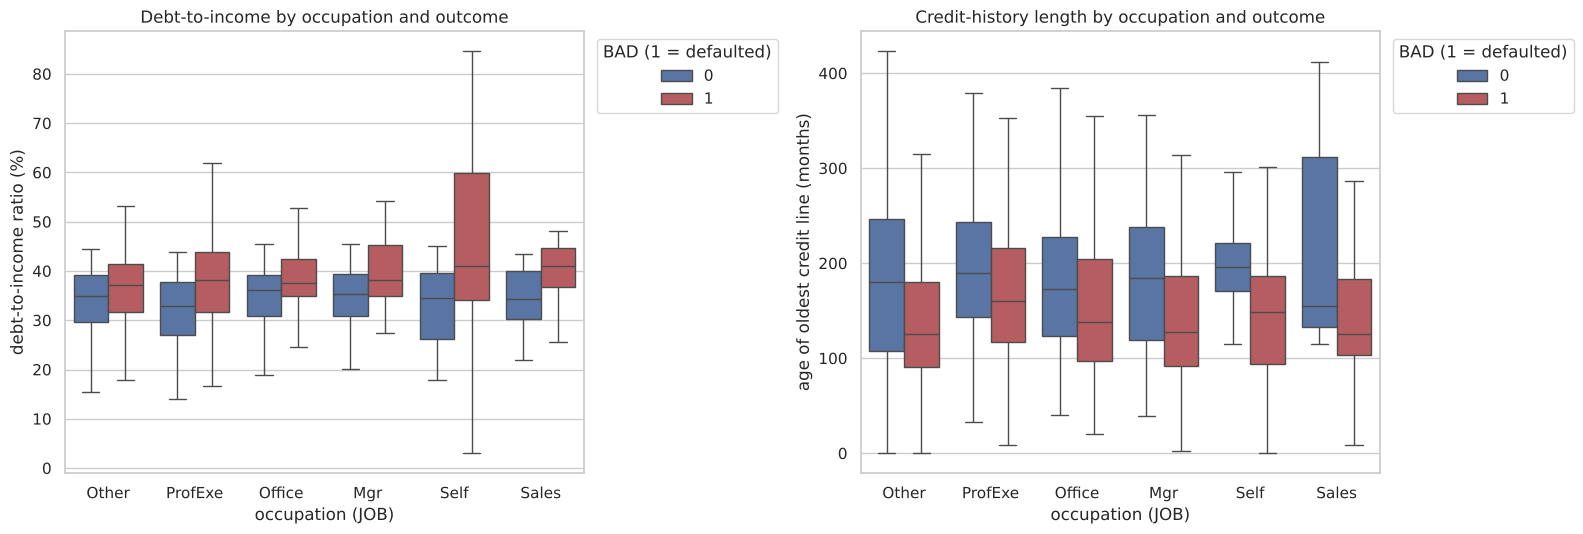

DEBTINC_median        CLAGE_median_months        
BAD                  0      1                   0       1
JOB                                                      
Mgr             35.300 38.300             184.000 127.000
Office          36.100 37.600             173.000 138.000
Other           35.000 37.100             180.000 125.000
ProfExe         32.900 38.200             189.000 160.000
Sales           34.400 41.000             155.000 125.000
Self            34.500 40.900             196.000 149.000

In [39]:
# Debt-to-income and credit-history length by occupation, split by outcome
job_order = data["JOB"].value_counts().index
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, col, label, title in [(axes[0], "DEBTINC", "debt-to-income ratio (%)", "Debt-to-income by occupation and outcome"),
                              (axes[1], "CLAGE", "age of oldest credit line (months)", "Credit-history length by occupation and outcome")]:
    sns.boxplot(data=data, x="JOB", y=col, hue="BAD", order=job_order, palette=["#4C72B0", "#C44E52"],
                showfliers=False, ax=ax)
    ax.set_xlabel("occupation (JOB)"); ax.set_ylabel(label); ax.set_title(title)
    ax.legend(title="BAD (1 = defaulted)", loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout(); plt.show()

pd.concat({"DEBTINC_median": data.groupby(["JOB", "BAD"], observed=True)["DEBTINC"].median().unstack().round(1),
           "CLAGE_median_months": data.groupby(["JOB", "BAD"], observed=True)["CLAGE"].median().unstack().round(0)}, axis=1)

**Insights - debt burden and credit history by occupation:**
- In every occupation, defaulters have a higher median debt-to-income ratio than repayers. The gap is about 1.5 points for office workers (37.6 against 36.1). It is about 6.5 points for sales and self-employed applicants (41.0 against 34.4, and 40.9 against 34.5).
- In every occupation, defaulters have a shorter credit history. The median gap is 29 months for professionals (160 against 189) and 57 months for managers (127 against 184).
- So debt burden and credit-history length work in every occupation. Occupation moves the baseline risk, but it does not replace these two drivers.

#### Interactions between the strongest drivers

The bivariate analysis found four strong drivers: the debt-to-income ratio, delinquent credit lines, credit-history length and derogatory reports. Here we cross them in pairs, and we keep "missing" as its own group because missingness is itself a signal. Each cell shows the default rate and the number of applicants. Cells with very few applicants (for example, a ratio above 45% with one delinquent line) are noisy, so we read them with caution.

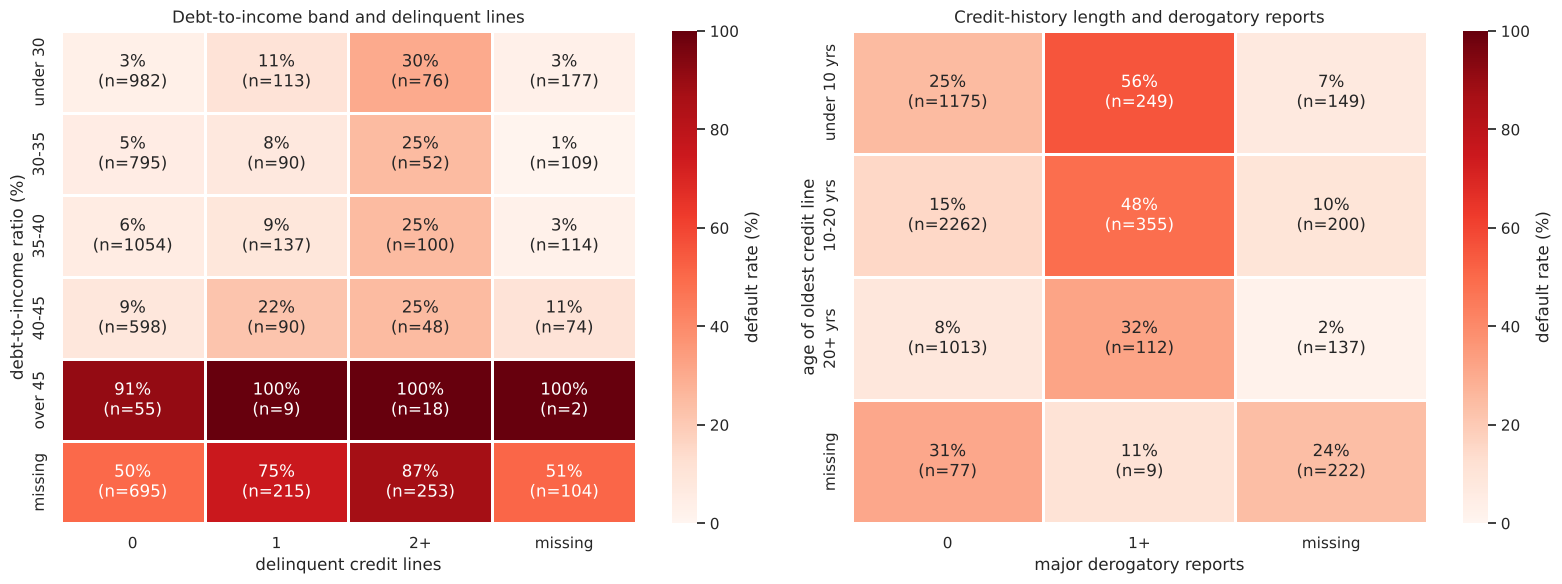

default_rate_pct  applicants
DEBTINC        VALUE                                       
ratio missing  value missing             98.800          81
               value recorded            59.500        1186
ratio recorded value missing             80.600          31
               value recorded             8.100        4662

In [40]:
# Default rate for pairs of drivers, with 'missing' kept as its own group
def band_with_missing(s, bins, labels):
    '''Cut a column into bands and keep blanks as a separate missing band.'''
    banded = pd.cut(s, bins=bins, labels=labels, include_lowest=True).astype(object)
    return banded.where(s.notna(), "missing")

dti_band = band_with_missing(data["DEBTINC"], [0, 30, 35, 40, 45, np.inf], ["under 30", "30-35", "35-40", "40-45", "over 45"])
delinq_group = band_with_missing(data["DELINQ"], [-0.5, 0.5, 1.5, np.inf], ["0", "1", "2+"])
history_band = band_with_missing(data["CLAGE"], [0, 120, 240, np.inf], ["under 10 yrs", "10-20 yrs", "20+ yrs"])
derog_group = band_with_missing(data["DEROG"], [-0.5, 0.5, np.inf], ["0", "1+"])

def rate_grid(rows, cols, row_order, col_order):
    '''Return the default rate and the applicant count for each pair of groups.'''
    grid_rate = bad_int.groupby([rows, cols]).mean().unstack().reindex(index=row_order, columns=col_order) * 100
    grid_n = bad_int.groupby([rows, cols]).size().unstack().reindex(index=row_order, columns=col_order).fillna(0).astype(int)
    return grid_rate, grid_n

grids = [
    (dti_band, delinq_group, ["under 30", "30-35", "35-40", "40-45", "over 45", "missing"], ["0", "1", "2+", "missing"],
     "debt-to-income ratio (%)", "delinquent credit lines", "Debt-to-income band and delinquent lines"),
    (history_band, derog_group, ["under 10 yrs", "10-20 yrs", "20+ yrs", "missing"], ["0", "1+", "missing"],
     "age of oldest credit line", "major derogatory reports", "Credit-history length and derogatory reports"),
]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (rows, cols, row_order, col_order, ylabel, xlabel, title) in zip(axes, grids):
    grid_rate, grid_n = rate_grid(rows, cols, row_order, col_order)
    grid_labels = grid_rate.round(0).fillna(0).astype(int).astype(str) + "%\n(n=" + grid_n.astype(str) + ")"
    sns.heatmap(grid_rate, annot=grid_labels, fmt="", mask=(grid_n == 0), cmap="Reds", vmin=0, vmax=100, linewidths=2,
                linecolor="white", cbar_kws={"label": "default rate (%)"}, ax=ax)
    ax.set_ylabel(ylabel); ax.set_xlabel(xlabel); ax.set_title(title)
plt.tight_layout(); plt.show()

# The two strongest missing-value signals together
ratio_status = data["DEBTINC"].isna().map({False: "ratio recorded", True: "ratio missing"})
value_status = data["VALUE"].isna().map({False: "value recorded", True: "value missing"})
both_missing = bad_int.groupby([ratio_status, value_status]).agg(default_rate_pct="mean", applicants="size")
both_missing["default_rate_pct"] = (100 * both_missing["default_rate_pct"]).round(1)
both_missing

**Insights - interactions between the strongest drivers:**
- **Debt burden and repayment history add up.** When the ratio is 45% or less, delinquency still decides much of the risk. In that group, 3% to 9% defaulted with no delinquent lines, and 25% to 30% defaulted with two or more.
- Above 45%, 91% to 100% defaulted, whatever the number of delinquent lines. The ratio alone is enough in that group.
- When the ratio is missing, delinquency adds risk on top of the missing signal. In that group, 50% defaulted with no delinquent lines (695 applicants) and 87% with two or more (253 applicants).
- **A long credit history lowers the risk but does not cancel a derogatory report.** With one or more reports, the default rate rises from 25% to 56% under 10 years of history. It rises from 15% to 48% at 10 to 20 years, and from 8% to 32% at 20 years or more.
- **The two missing-value signals compound.** With both fields recorded, 8% defaulted (4,662 applicants). With only the ratio missing, 60% defaulted (1,186 applicants). With only the property value missing, 81% defaulted (31 applicants). With both missing, 99% defaulted (81 applicants).
- These combined effects suggest that a tree-based model, which splits on one driver inside another, should beat a model that adds each driver alone. They also match the surrogate tree we fit later. A high or missing ratio flags an applicant, and repayment history and credit-history length decide among the others.

## Hold out the test set before fitting any pre-processing

We fit every statistic that prepares the data (outlier fences, imputation medians and modes, feature scaling) **on the training rows only**. Then we apply these statistics to the test rows. Fitting them on all 5,960 loans would leak a little information about the test applicants into the model. The split is 70% train / 30% test, stratified on `BAD` so both sets keep the 20% default rate. We fix the seed so every model sees the same applicants.

In [41]:
# Split the rows 70/30 before any pre-processing. Stratify on BAD so that both sets keep the 20% default rate.
train_idx, test_idx = train_test_split(data.index, test_size=0.30, random_state=RANDOM_STATE, stratify=data["BAD"])
print(f"Training rows: {len(train_idx):,} | Test rows: {len(test_idx):,}")
print(f"Default rate - train: {data.loc[train_idx, 'BAD'].astype(int).mean():.3f}, test: {data.loc[test_idx, 'BAD'].astype(int).mean():.3f}")

Training rows: 4,172 | Test rows: 1,788
Default rate - train: 0.199, test: 0.200


## Treating Outliers

**Approach.** The boxplots showed outliers in almost every numerical column. Two kinds exist here:

1. *Implausible values* that are probably data errors: `DEBTINC` above 100%, `CLAGE` above about 600 months.
2. *Genuine but extreme values*: large loans, expensive properties, many delinquencies.

Both kinds matter differently for different models:

- **Logistic Regression** is sensitive to extreme values because they pull the fitted line. For the linear model we **cap** each continuous column at the IQR whiskers (Q1 - 1.5 IQR and Q3 + 1.5 IQR). This keeps every row but limits the leverage of extremes. We cap the count variables `DEROG` and `DELINQ` at their 99th percentile instead, because their inter-quartile range is zero. We compute all fences on the training rows.
- **Decision Trees and Random Forests** split on rank order, so an outlier simply falls into the top bucket. Capping does not change their splits. For the tree models we **keep the original values**, because capping would only merge the largest values into one value.

We therefore keep two versions of the data: `df_lr` (outliers capped, for the linear model) and `data` (untreated, for the tree models).

In [42]:
def treat_outliers(df, col, fit_rows):
    '''Cap a numerical column at the IQR whiskers computed on the training rows.'''
    Q1 = df.loc[fit_rows, col].quantile(0.25)
    Q3 = df.loc[fit_rows, col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    df[col] = np.clip(df[col], lower, upper)
    return df

def treat_outliers_all(df, col_list, fit_rows):
    '''Cap each column in col_list at its IQR whiskers, learned on the training rows only.'''
    for c in col_list:
        df = treat_outliers(df, c, fit_rows)
    return df

df_lr = data.copy()

# IQR capping for the continuous variables
iqr_cols = [c for c in num_cols if c not in ("DEROG", "DELINQ")]
df_lr = treat_outliers_all(df_lr, iqr_cols, train_idx)

# DEROG and DELINQ are counts with Q1 = Q3 = 0, so the IQR whiskers collapse to zero and would erase
# the variables entirely. They are capped at the 99th percentile (of the training rows) instead.
for c in ["DEROG", "DELINQ"]:
    df_lr[c] = df_lr[c].clip(upper=df_lr.loc[train_idx, c].quantile(0.99))

# Compare the maximum of each column before and after capping
pd.DataFrame({"max_before": data[num_cols].max(), "max_after": df_lr[num_cols].max(),
              "rows_capped": [(data[c] > df_lr[c]).sum() + (data[c] < df_lr[c]).sum() for c in num_cols]})

,max_before,max_after,rows_capped
LOAN,"89,900.000","41,850.000",249
MORTDUE,"399,550.000","161,277.500",227
VALUE,"855,909.000","201,864.750",307
YOJ,41.000,28.000,91
DEROG,10.000,5.000,34
DELINQ,15.000,6.000,25
CLAGE,"1,168.234",406.840,47
NINQ,17.000,5.000,177
CLNO,71.000,46.500,155
DEBTINC,203.312,53.785,94


**Observations:**
- Capping removes the impossible values (DEBTINC 203% becomes about 54%, CLAGE 1,168 months becomes about 407 months) while keeping every row.
- `DEROG` and `DELINQ` have a 75th percentile of zero, so the IQR whiskers collapse to zero. If we applied the rule blindly, it would set every value to zero and remove two of the strongest risk signals. We therefore cap them at the 99th percentile instead (about 5 derogatory reports and 6 delinquent lines). This limits the leverage of the extreme counts while keeping the signal.
- The capped DEBTINC ceiling (about 54%) is still above the 45% danger threshold, so the linear model can still learn that rule.

## Treating Missing Values

**Approach.**

1. **Create a binary flag** `<column>_missing` for every column with gaps. The bivariate analysis showed that missingness, especially of `DEBTINC` and `VALUE`, is strongly predictive, so we must preserve this information.
2. **Impute numerical columns with the median** and **categorical columns with the mode**. The median is not sensitive to the skew and outliers seen above. Compute both on the training rows only. Then apply them to all rows.
3. Apply exactly the same steps to both versions of the data. Use `df_lr` for the linear model and `data` for the tree models.

In [43]:
# Helper: add a 0/1 flag for each column that has missing values
def add_missing_flags(df):
    '''Add a 0/1 flag column for each column that has missing values.'''
    for col in [c for c in df.columns if df[c].isnull().any()]:
        df[f"{col}_missing"] = df[col].isnull().astype(int)
    return df

def impute(df, fit_rows):
    '''Median for numerical columns, mode for categorical columns, both learned from the training rows.'''
    num = df.select_dtypes("number").columns
    cat = df.select_dtypes("category").columns.drop("BAD")
    df[num] = df[num].fillna(df.loc[fit_rows, num].median())
    for c in cat:
        df[c] = df[c].fillna(df.loc[fit_rows, c].mode()[0])
    return df

for frame in (df_lr, data):
    add_missing_flags(frame)
    impute(frame, train_idx)

print("Remaining missing values (tree data):", data.isnull().sum().sum())
print("Remaining missing values (linear data):", df_lr.isnull().sum().sum())
print("\nFlag columns added:", [c for c in data.columns if c.endswith("_missing")])

Remaining missing values (tree data): 0
Remaining missing values (linear data): 0

Flag columns added: ['MORTDUE_missing', 'VALUE_missing', 'REASON_missing', 'JOB_missing', 'YOJ_missing', 'DEROG_missing', 'DELINQ_missing', 'CLAGE_missing', 'NINQ_missing', 'CLNO_missing', 'DEBTINC_missing']


In [44]:
# Show the first rows after imputation, with the new missing-value flags
data.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC,MORTDUE_missing,VALUE_missing,REASON_missing,JOB_missing,YOJ_missing,DEROG_missing,DELINQ_missing,CLAGE_missing,NINQ_missing,CLNO_missing,DEBTINC_missing
0,1,1100,"25,860.000","39,025.000",HomeImp,Other,10.500,0.000,0.000,94.367,1.000,9.000,34.840,0,0,0,0,0,0,0,0,0,0,1
1,1,1300,"70,053.000","68,400.000",HomeImp,Other,7.000,0.000,2.000,121.833,0.000,14.000,34.840,0,0,0,0,0,0,0,0,0,0,1
2,1,1500,"13,500.000","16,700.000",HomeImp,Other,4.000,0.000,0.000,149.467,1.000,10.000,34.840,0,0,0,0,0,0,0,0,0,0,1
3,1,1500,"66,293.000","89,965.000",DebtCon,Other,7.000,0.000,0.000,173.868,1.000,20.000,34.840,1,1,1,1,1,1,1,1,1,1,1
4,0,1700,"97,800.000","112,000.000",HomeImp,Office,3.000,0.000,0.000,93.333,0.000,14.000,34.840,0,0,0,0,0,0,0,0,0,0,1


## **Important Insights from EDA**

What are the the most important observations and insights from the data based on the EDA performed?

1. **One in five loans goes bad (19.9%).** The classes are imbalanced, so accuracy is the wrong yardstick. We must handle the imbalance with class weights while we build the individual models, and with the decision threshold when we choose the final model.

2. **Missing information is the strongest single risk signal.** Applicants with no recorded debt-to-income ratio default 62% of the time (vs 8.6% when it is recorded). Applicants with no property valuation default 94% of the time. The bank's approval process should treat an unverifiable income or valuation as a red flag, not as a neutral gap.

3. **Debt-to-income ratio has a hard threshold.** Between 20% and 40% the default rate is only 4% to 7% (and 11% below 20%). Between 40% and 45% it is 11%. Above 45% it is 87% to 100%. A 45% threshold is a simple, defensible policy rule.

4. **Past credit behaviour predicts future behaviour.** Each additional major derogatory report or delinquent credit line raises the default rate sharply. The rate is 17% with 0 reports, 39% with 1, 51% with 2, and about 75% with 3 or more. Recent credit inquiries show the same rising pattern.

5. **A long credit history protects.** Applicants whose oldest credit line is under 5 years old default 44% of the time. Above 20 years the rate falls to about 10%.

6. **Small loans are not safe loans.** Loans under \$5,000 default 57% of the time, almost three times the average.

7. **Occupation matters moderately.** Sales (35%) and self-employed (30%) applicants default most. Office workers (13%) and professionals (17%) default least. Loan purpose (home improvement vs debt consolidation) makes only a 3-point difference, although the difference is statistically significant.

8. **Property value and mortgage balance are highly correlated (0.88)** and individually weak predictors. We will keep them, but we should read the linear model's coefficients for them with caution.

9. **Several relationships with the target are threshold-shaped** (debt-to-income, credit-history length, loan size) rather than straight lines. We therefore expect tree-based models to outperform logistic regression on the raw inputs. Logistic regression will remain useful as the most transparent benchmark.

10. **Risk factors combine rather than act alone.** A ratio above 45% flags an applicant by itself. At or below 45%, two or more delinquent lines raise the default rate from 3-9% to 25-30%. A derogatory report raises risk at every credit-history length. When both the ratio and the property value are missing, 99% defaulted. Loan purpose also changes the risk within some occupations (self-employed applicants: 44% on debt consolidation against 18% on home improvement). These interactions favour tree-based models.

11. **Pre-processing decisions:**
    - We did not remove any rows, and we found no duplicates.
    - We separated the test set before we fitted any statistic.
    - We added a missing-value flag for every column with gaps.
    - We learned the median/mode imputation on the training rows.
    - We applied IQR capping only for the linear model (99th-percentile cap for DEROG and DELINQ).
    - We one-hot encoded `REASON` and `JOB`.
    - We scaled the continuous inputs only for the linear model.

## **Model Building - Approach**
- Data preparation
- Partition the data into train and test set
- Build the model
- Fit on the train data
- Tune the model
- Test the model on test set

**A note on technique choice.** The Practical Data Science toolkit covers decision trees, bagging and random forests, and time-series forecasting. We use the first three below. We move from a single tree to a bagged ensemble to a random forest, so that we can see what each idea contributes.

Time-series methods do not apply to this problem. Each row is one loan application with no date or ordering, so there is no sequence to model. We recommend a time-aware validation (train on earlier applications, test on later ones) as further analysis once application dates are available. We include logistic regression as the linear benchmark that we need to compare linear and non-linear techniques fairly.

**Why these techniques suit this data and problem.** The EDA found four facts that set the choice. (1) Risk changes in steps, for example at a 45% debt-to-income ratio (insights 3 and 9). (2) Risk factors combine, for example delinquent lines inside the lower debt-to-income bands (insight 10). (3) A blank field is itself a risk signal (insight 2). (4) Only one applicant in five defaults (insight 1). A decision tree splits on thresholds and on one driver inside another, so it fits facts 1 and 2. It also gives readable rules for adverse-action reasons. A single tree is unstable, so we add bagging to reduce variance. The random forest also tries a random subset of inputs at each split, so its trees are less alike. Missing-value flags cover fact 3. Class weights and the decision threshold cover fact 4. We do not use k-nearest neighbours or support vector machines. The bank cannot easily explain their decisions to an applicant, and the ECOA requires such an explanation.

**How we use the test set.** We choose the hyper-parameters, the final model and its decision threshold with cross-validation on the training rows. We score the test set once per model to report performance, and we never use it to choose any of them.

### Model evaluation criterion - what is the measure of success?

The model makes two kinds of mistakes, and they do not cost the same:

| Model says | Reality | Name | Business consequence |
|---|---|---|---|
| Will repay (approve) | Defaults | **False Negative** | The bank loses a large part of the principal plus collection costs. The defaulted loans in this data averaged about \$16,900. With about half recovered through the collateral, this is roughly \$9,000 per missed defaulter. |
| Will default (reject) | Repays | **False Positive** | The bank loses the interest margin on one good customer and may lose the relationship. This is roughly \$2,000. |

A missed defaulter costs several times more than a wrongly rejected good applicant. The primary metric is therefore **Recall on the defaulter class (BAD = 1)**. *Of all the applicants who later defaulted, what share did the model flag in advance?*

Recall alone can be gamed (rejecting everyone gives 100% recall), so we track two guard-rails:

- **Precision** on the defaulter class: of the applicants we reject, how many would really have defaulted? Low precision means the bank rejects good business.
- **F1-score**: the harmonic mean of the two. We use it as the tie-breaker when recall is similar.

We also report **Accuracy** for completeness and **ROC-AUC** as a threshold-free measure of how well the model ranks risky applicants. ROC-AUC matters because the bank can later move the decision threshold.

We tune the individual models with **cross-validated grid search optimising Recall** (the course convention, and a deliberate push towards catching defaulters). Recall alone rewards flagging everyone. We therefore **choose the final model and its threshold on the expected cost of the two errors**. We estimate this cost with out-of-fold predictions on the training rows, so that precision carries an explicit price.

In [45]:
# Helper: print the classification report and plot the confusion matrix
def metrics_score(actual, predicted, labels=("Repaid (0)", "Default (1)"), title="Confusion matrix"):
    '''Classification report and a confusion matrix heatmap.'''
    print(classification_report(actual, predicted, digits=3))
    cm = confusion_matrix(actual, predicted)
    plt.figure(figsize=(5.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels)
    plt.ylabel("Actual"); plt.xlabel("Predicted"); plt.title(title)
    plt.show()


def model_scores(model, X_tr, y_tr, X_te, y_te, name):
    '''Return a one-row DataFrame of train/test metrics for a fitted model.'''
    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    row = {
        "Model": name,
        "Train Recall": recall_score(y_tr, p_tr), "Test Recall": recall_score(y_te, p_te),
        "Train Precision": precision_score(y_tr, p_tr), "Test Precision": precision_score(y_te, p_te),
        "Train F1": f1_score(y_tr, p_tr), "Test F1": f1_score(y_te, p_te),
        "Train Accuracy": accuracy_score(y_tr, p_tr), "Test Accuracy": accuracy_score(y_te, p_te),
        "Test ROC-AUC": roc_auc_score(y_te, model.predict_proba(X_te)[:, 1]),
    }
    return pd.DataFrame([row])

results = []   # collects the comparison table

### Data preparation and train/test split

- Separate the target from the inputs. One-hot encode `REASON` and `JOB`. Remove the first level of each to avoid redundant columns. Convert the target to integer.
- Use the **70% / 30% stratified split** fixed above (`train_idx`, `test_idx`) for both data versions. In this way, **the same applicants are in the test set** for the linear and the tree models.
- Standardise the **continuous inputs only** for the linear model (fit on the training rows). Leave the 0/1 flags and dummy columns as they are. Then we can read each of their coefficients as the effect of the flag switching from 0 to 1.

In [46]:
def prepare_xy(df):
    '''Return the one-hot encoded inputs X and the integer target y.'''
    X = pd.get_dummies(df.drop(columns=["BAD"]), columns=["REASON", "JOB"], drop_first=True, dtype=int)
    y = df["BAD"].astype(int)
    return X, y

# Linear-model version (outliers capped)
X_lr, y_lr = prepare_xy(df_lr)
X_train_lr, X_test_lr = X_lr.loc[train_idx], X_lr.loc[test_idx]
y_train_lr, y_test_lr = y_lr.loc[train_idx], y_lr.loc[test_idx]

# Tree-model version (outliers untouched)
X, y = prepare_xy(data)
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print("Feature columns:", list(X.columns))
print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")
assert (y_train_lr == y_train).all(), "both data versions must share the same split"

Feature columns: ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC', 'MORTDUE_missing', 'VALUE_missing', 'REASON_missing', 'JOB_missing', 'YOJ_missing', 'DEROG_missing', 'DELINQ_missing', 'CLAGE_missing', 'NINQ_missing', 'CLNO_missing', 'DEBTINC_missing', 'REASON_HomeImp', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']

Train shape: (4172, 27), Test shape: (1788, 27)


In [47]:
# Scale the continuous inputs for the linear model (fit on train only); flags and dummies stay 0/1
scaler = StandardScaler().fit(X_train_lr[num_cols])
X_train_lr_s, X_test_lr_s = X_train_lr.copy(), X_test_lr.copy()
X_train_lr_s[num_cols] = scaler.transform(X_train_lr[num_cols])
X_test_lr_s[num_cols] = scaler.transform(X_test_lr[num_cols])
assert list(X_train_lr_s.columns) == list(X_train.columns), "both data versions carry the same 27 named inputs"
print(f"Linear-model inputs ({X_train_lr_s.shape[1]}), the same columns as the tree models:")
print(f"  capped (IQR whiskers, DEROG and DELINQ at the 99th percentile) and standardised ({len(num_cols)}):", num_cols)
print(f"  left as 0/1 ({X_train_lr_s.shape[1] - len(num_cols)}):", [c for c in X_train_lr_s.columns if c not in num_cols])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

Linear-model inputs (27), the same columns as the tree models:
  capped (IQR whiskers, DEROG and DELINQ at the 99th percentile) and standardised (10): ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
  left as 0/1 (17): ['MORTDUE_missing', 'VALUE_missing', 'REASON_missing', 'JOB_missing', 'YOJ_missing', 'DEROG_missing', 'DELINQ_missing', 'CLAGE_missing', 'NINQ_missing', 'CLNO_missing', 'DEBTINC_missing', 'REASON_HomeImp', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']


#### Model inputs at each step

The table follows the named inputs from the raw fields to the model. The outputs above print every list.

| Step | Tree models (Decision Tree, Bagging, Random Forest) | Logistic regression |
|---|---|---|
| 1. Raw fields (12) | `LOAN`, `MORTDUE`, `VALUE`, `REASON`, `JOB`, `YOJ`, `DEROG`, `DELINQ`, `CLAGE`, `NINQ`, `CLNO`, `DEBTINC` | Same |
| 2. Outlier treatment | None | The 10 numeric fields capped on training-row fences: IQR whiskers, `DEROG` and `DELINQ` at the 99th percentile |
| 3. Missing-value flags (11) | `<field>_missing` for every field except `LOAN` | Same |
| 4. Imputation | Training-row median (numeric fields) or mode (`REASON`, `JOB`) | Same |
| 5. One-hot encoding (6) | `REASON_HomeImp`, `JOB_Office`, `JOB_Other`, `JOB_ProfExe`, `JOB_Sales`, `JOB_Self` | Same |
| 6. Scaling | None | The 10 numeric fields standardised. The 17 flags and indicators stay 0/1 |
| 7. Prepared inputs (27) | 10 numeric fields + 11 flags + 6 indicators. Every tree model uses all 27, except the models in row 8 | The same 27 columns |
| 8. Input-set reduction | Final forest and surrogate tree: 22 inputs. Stage 2 of the selection removes the missing flags of `MORTDUE`, `DELINQ`, `CLAGE`, `NINQ` and `CLNO`. It keeps the 10 numeric fields, 6 flags (`VALUE`, `REASON`, `JOB`, `YOJ`, `DEROG`, `DEBTINC`) and the 6 indicators. Rule: the smallest input set within one standard error of the lowest cost on the seed-averaged curve. Stage 3 checks the 22 inputs against all 27. Fair-lending fallback: the 22 inputs without occupation (16 inputs). Recall-tuned forest: also tested on a 12-input set. The final-pipeline cell prints the kept and removed inputs | Not applied |

### Logistic Regression

Logistic regression is the **linear benchmark**: it models the log-odds of default as a weighted sum of the inputs. Its coefficients are directly interpretable, which is exactly what the ECOA requires. We fit three versions:

1. A plain model (equal class weights) to see the effect of the imbalance.
2. A model with `class_weight="balanced"`, which up-weights the minority defaulter class so the model stops favouring the majority.
3. The balanced model with its regularisation strength `C` tuned by cross-validated grid search on recall. This gives the linear model the same tuning treatment as the tree models.

Train performance - Logistic Regression (plain)
              precision    recall  f1-score   support

           0      0.913     0.960     0.936      3340
           1      0.799     0.635     0.707       832

    accuracy                          0.895      4172
   macro avg      0.856     0.797     0.822      4172
weighted avg      0.891     0.895     0.891      4172



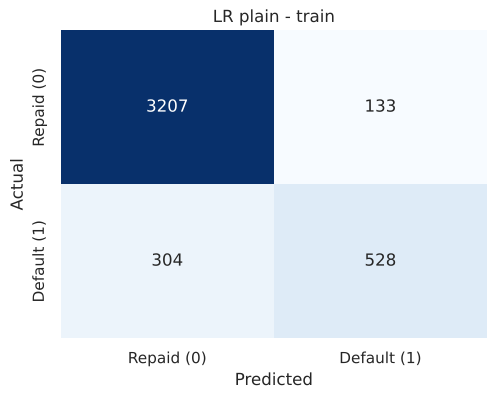

Test performance - Logistic Regression (plain)
              precision    recall  f1-score   support

           0      0.898     0.959     0.928      1431
           1      0.774     0.566     0.654       357

    accuracy                          0.880      1788
   macro avg      0.836     0.762     0.791      1788
weighted avg      0.874     0.880     0.873      1788



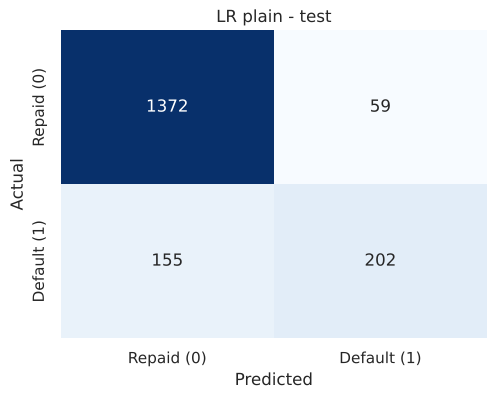

In [48]:
# 1. Plain logistic regression
lr_plain = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
lr_plain.fit(X_train_lr_s, y_train_lr)

print("Train performance - Logistic Regression (plain)")
metrics_score(y_train_lr, lr_plain.predict(X_train_lr_s), title="LR plain - train")
print("Test performance - Logistic Regression (plain)")
metrics_score(y_test_lr, lr_plain.predict(X_test_lr_s), title="LR plain - test")
results.append(model_scores(lr_plain, X_train_lr_s, y_train_lr, X_test_lr_s, y_test_lr, "Logistic Regression (plain)"))

Best C: {'C': 1} | best CV recall: 0.814
 param_C  CV recall
   0.010      0.796
   0.100      0.804
   1.000      0.814
  10.000      0.811

Train performance - Logistic Regression (balanced, tuned C)
              precision    recall  f1-score   support

           0      0.951     0.863     0.905      3340
           1      0.598     0.821     0.692       832

    accuracy                          0.854      4172
   macro avg      0.774     0.842     0.798      4172
weighted avg      0.880     0.854     0.862      4172



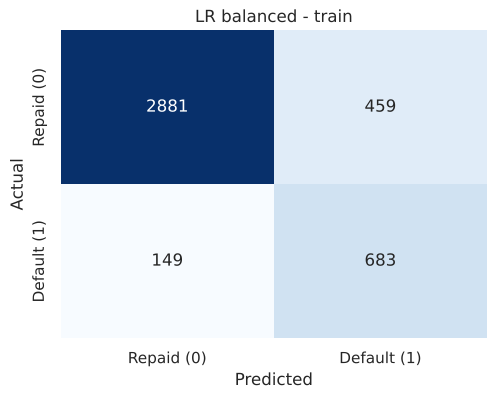

Test performance - Logistic Regression (balanced, tuned C)
              precision    recall  f1-score   support

           0      0.945     0.872     0.907      1431
           1      0.608     0.796     0.689       357

    accuracy                          0.857      1788
   macro avg      0.776     0.834     0.798      1788
weighted avg      0.878     0.857     0.864      1788



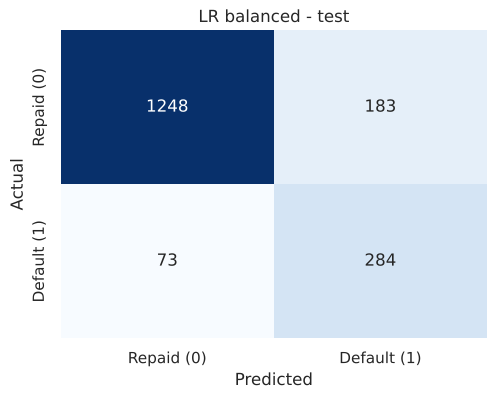

In [49]:
# 2. Logistic regression with balanced class weights, 3. with the regularisation strength tuned by grid search
lr_search = GridSearchCV(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
                         {"C": [0.01, 0.1, 1, 10]}, scoring="recall", cv=cv5, n_jobs=-1)
lr_search.fit(X_train_lr_s, y_train_lr)
print("Best C:", lr_search.best_params_, f"| best CV recall: {lr_search.best_score_:.3f}")
print(pd.DataFrame(lr_search.cv_results_)[["param_C", "mean_test_score"]].rename(columns={"mean_test_score": "CV recall"}).round(3).to_string(index=False))
lr_bal = lr_search.best_estimator_

print("\nTrain performance - Logistic Regression (balanced, tuned C)")
metrics_score(y_train_lr, lr_bal.predict(X_train_lr_s), title="LR balanced - train")
print("Test performance - Logistic Regression (balanced, tuned C)")
metrics_score(y_test_lr, lr_bal.predict(X_test_lr_s), title="LR balanced - test")
results.append(model_scores(lr_bal, X_train_lr_s, y_train_lr, X_test_lr_s, y_test_lr, "Logistic Regression (balanced)"))

**Observations - Logistic Regression:**
- The plain model is accurate overall (about 88% on test) but catches only about **57% of defaulters** on the test set. It favours the "repaid" prediction because that is the majority class.
- Balancing the class weights raises test recall to about **80%** while precision falls to about 61% and accuracy to about 86%. In business terms the balanced model catches roughly 23 more defaulters out of every 100, at the cost of rejecting more good applicants.
- Regularisation strength makes little difference: cross-validated recall is within two points across `C` from 0.01 to 10. So the functional form, not the regularisation, limits the linear model.
- Train and test scores are close, so the linear model **does not over-fit**. Its limitation is that a straight line on the raw inputs cannot capture the threshold effects seen in the EDA. Binned or interaction features would help, and we list them as further work.
- ROC-AUC of about 0.91 shows the model ranks applicants well even though a fixed 0.5 threshold is not ideal.

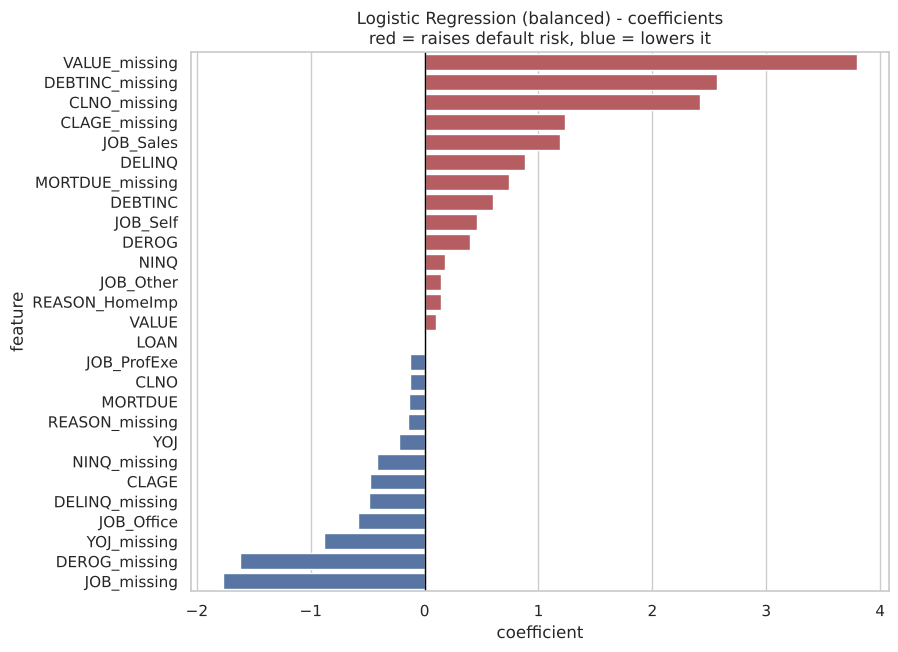

,feature,coefficient,odds_ratio,unit
0,VALUE_missing,3.797,44.551,flag 0 -> 1
1,DEBTINC_missing,2.571,13.074,flag 0 -> 1
2,CLNO_missing,2.417,11.214,flag 0 -> 1
3,CLAGE_missing,1.237,3.445,flag 0 -> 1
4,JOB_Sales,1.193,3.296,flag 0 -> 1
5,DELINQ,0.884,2.422,per 1 standard deviation
6,MORTDUE_missing,0.745,2.106,flag 0 -> 1
7,DEBTINC,0.600,1.821,per 1 standard deviation
8,JOB_Self,0.462,1.587,flag 0 -> 1
9,DEROG,0.401,1.494,per 1 standard deviation


In [50]:
# Coefficients and odds ratios of the balanced logistic regression.
# Continuous inputs are standardised, so their coefficients are per one standard deviation;
# flags and dummies are 0/1, so their coefficients are the effect of the flag switching on.
coef = pd.DataFrame({"feature": X_train_lr_s.columns, "coefficient": lr_bal.coef_[0]})
coef["odds_ratio"] = np.exp(coef["coefficient"])
coef["unit"] = ["per 1 standard deviation" if f in num_cols else "flag 0 -> 1" for f in coef["feature"]]
coef = coef.sort_values("coefficient", ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, 7))
colors = ["#C44E52" if c > 0 else "#4C72B0" for c in coef["coefficient"]]
sns.barplot(data=coef, x="coefficient", y="feature", hue="feature", legend=False, palette=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Logistic Regression (balanced) - coefficients\nred = raises default risk, blue = lowers it")
plt.show()
coef

**Insights - what the linear model says drives default:**

- **Risk-increasing (positive coefficients):** the missing-value flags dominate (these flags are 0/1, so the odds ratios are the full effect of the flag). An application with **no property valuation has odds of default about 45 times higher**, all else equal. An application with **no debt-to-income ratio has odds about 13 times higher**, all else equal. The model also gives `CLNO_missing` a large odds ratio (11.2). Do not read this flag on its own. Every applicant with a missing `CLNO` also has missing `DEROG`, `DELINQ`, `CLAGE` and `NINQ`. The five flag coefficients partly cancel, and together they give an odds ratio of about 3. The EDA shows only 23.9% default when `CLNO` is missing, against 19.8% when it is present. Among the continuous inputs, `DELINQ` (odds ratio about 2.4 per standard deviation) and `DEBTINC` (about 1.8) matter most, followed by `DEROG` and `NINQ`. The `JOB_Sales` indicator roughly triples the odds relative to a manager.
- **Risk-decreasing (negative coefficients):** `CLAGE` (longer credit history, odds ratio about 0.6 per standard deviation), `YOJ` (job tenure) and `JOB_Office` lower the odds. The `DEROG`, `JOB`, `YOJ` and `DELINQ` missing flags also lower the odds: in the EDA, the groups with these fields blank defaulted less often.
- `LOAN` has almost no linear effect once the model includes the other variables. Its relationship with default is non-linear (small loans are riskier, large loans are not), and a straight line cannot represent this.
- `MORTDUE` and `VALUE` have opposite signs, the classic symptom of their 0.88 correlation. We should not over-interpret these two coefficients individually.
- The signs agree with the EDA and with lending common sense, which gives confidence that the model learns real risk rather than noise.

#### Can a different threshold improve the linear model?

The default threshold is 0.5. For an imbalanced problem the best operating point is usually lower. The precision-recall trade-off below shows what the bank gains and loses by moving the threshold.

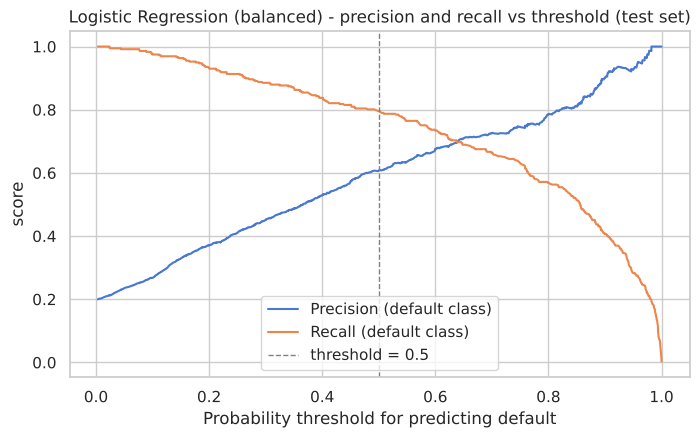

,threshold,recall,precision,f1,accuracy
0,0.300,0.885,0.451,0.597,0.762
1,0.400,0.838,0.529,0.649,0.819
2,0.500,0.796,0.608,0.689,0.857
3,0.600,0.734,0.675,0.703,0.876


In [51]:
# Plot precision and recall of the balanced logistic regression at each threshold on the test set (illustration only)
proba_lr = lr_bal.predict_proba(X_test_lr_s)[:, 1]
prec, rec, thr = precision_recall_curve(y_test_lr, proba_lr)

plt.figure(figsize=(8, 4.5))
plt.plot(thr, prec[:-1], label="Precision (default class)")
plt.plot(thr, rec[:-1], label="Recall (default class)")
plt.axvline(0.5, color="grey", linestyle="--", linewidth=1, label="threshold = 0.5")
plt.xlabel("Probability threshold for predicting default"); plt.ylabel("score")
plt.title("Logistic Regression (balanced) - precision and recall vs threshold (test set)")
plt.legend(); plt.show()

# Metrics at a few candidate thresholds (illustration only; the threshold of the final model is chosen on training data below)
rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    p = (proba_lr > t).astype(int)
    rows.append({"threshold": t, "recall": recall_score(y_test_lr, p),
                 "precision": precision_score(y_test_lr, p), "f1": f1_score(y_test_lr, p),
                 "accuracy": accuracy_score(y_test_lr, p)})
pd.DataFrame(rows)

**Observations:**
- Lowering the threshold to 0.4 lifts recall to about 84% but precision drops to about 53%. Raising it to 0.6 does the reverse (about 73% recall, 68% precision). F1 is highest around 0.5-0.6, so the balanced model at 0.5 is already close to its best balance.
- The threshold is a **business lever**, not a technical constant: the bank's risk appetite decides where to sit on this curve. For the final model we choose it formally, on the training rows, in the model-selection section.

### Decision Tree

A decision tree learns a sequence of yes/no questions ("Is DEBTINC above 43.7%?") that split the applicants into increasingly pure groups. It captures the threshold effects seen in the EDA directly and produces rules that the bank can read to an applicant or a regulator.

We train the tree models on the **untreated data** (`X_train`, `X_test`). Outliers do not distort tree splits, and capping would only merge the largest values into one value.

We proceed in three steps:

1. Start with a fully grown tree to establish a baseline.
2. Add class weights.
3. Prune with grid search.

Train performance - Decision Tree (default)
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      3340
           1      1.000     1.000     1.000       832

    accuracy                          1.000      4172
   macro avg      1.000     1.000     1.000      4172
weighted avg      1.000     1.000     1.000      4172



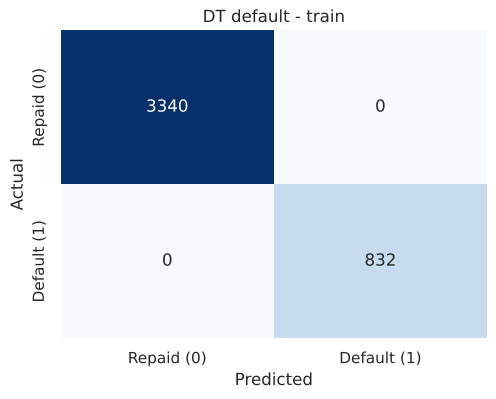

Test performance - Decision Tree (default)
              precision    recall  f1-score   support

           0      0.922     0.929     0.925      1431
           1      0.706     0.686     0.696       357

    accuracy                          0.880      1788
   macro avg      0.814     0.807     0.811      1788
weighted avg      0.879     0.880     0.880      1788



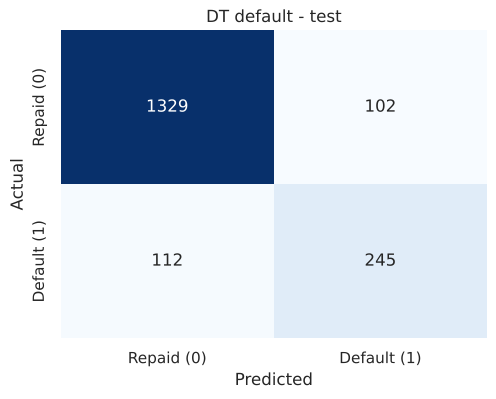

Tree depth: 28 | number of leaves: 366


In [52]:
# Baseline decision tree (fully grown)
dt_base = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_base.fit(X_train, y_train)

print("Train performance - Decision Tree (default)")
metrics_score(y_train, dt_base.predict(X_train), title="DT default - train")
print("Test performance - Decision Tree (default)")
metrics_score(y_test, dt_base.predict(X_test), title="DT default - test")
results.append(model_scores(dt_base, X_train, y_train, X_test, y_test, "Decision Tree (default)"))
print("Tree depth:", dt_base.get_depth(), "| number of leaves:", dt_base.get_n_leaves())

**Observations - default Decision Tree:**
- The fully grown tree is a textbook case of **over-fitting**. It scores 100% recall, precision and accuracy on the training rows, but only about **69% recall** and 71% precision on the test set. It memorised the training applicants (dozens of levels deep, hundreds of leaves) instead of learning general rules.
- Even so, its test recall is already higher than the plain logistic regression, which shows that non-linear splits help on this data.

Train performance - Decision Tree (class weights 0.2/0.8)


              precision    recall  f1-score   support

           0      1.000     1.000     1.000      3340
           1      1.000     1.000     1.000       832

    accuracy                          1.000      4172
   macro avg      1.000     1.000     1.000      4172
weighted avg      1.000     1.000     1.000      4172



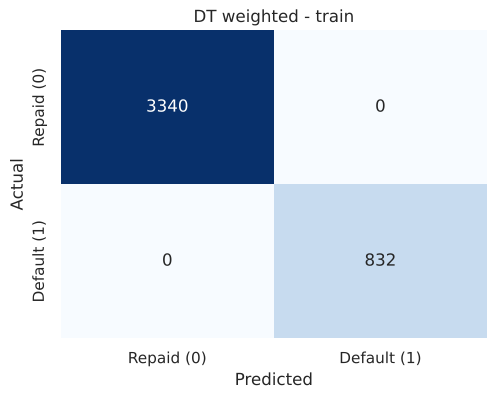

Test performance - Decision Tree (class weights 0.2/0.8)
              precision    recall  f1-score   support

           0      0.908     0.940     0.923      1431
           1      0.719     0.616     0.664       357

    accuracy                          0.875      1788
   macro avg      0.813     0.778     0.794      1788
weighted avg      0.870     0.875     0.872      1788



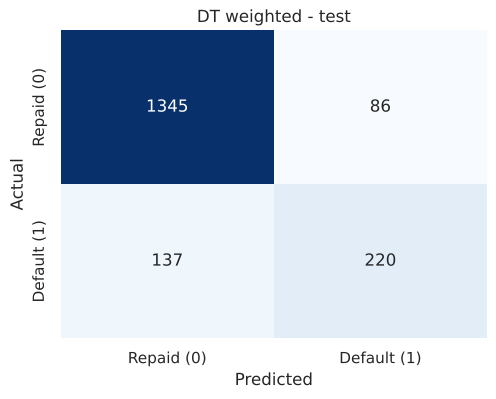

In [53]:
# Decision tree with class weights favouring the defaulter class
dt_cw = DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight={0: 0.2, 1: 0.8})
dt_cw.fit(X_train, y_train)

print("Train performance - Decision Tree (class weights 0.2/0.8)")
metrics_score(y_train, dt_cw.predict(X_train), title="DT weighted - train")
print("Test performance - Decision Tree (class weights 0.2/0.8)")
metrics_score(y_test, dt_cw.predict(X_test), title="DT weighted - test")
results.append(model_scores(dt_cw, X_train, y_train, X_test, y_test, "Decision Tree (class weights)"))

**Observations:**
- Adding class weights to an un-pruned tree does **not** help: test recall is about 62%, no better than the baseline. The weights change the weighted impurity and therefore the chosen splits (this is a different tree). But they cannot change the fact that a fully grown tree fits every training applicant perfectly. So the test predictions remain those of an over-fitted tree.
- Class weights only help once we constrain (prune) the tree, which is what the grid search does next.

### **Decision Tree - Hyperparameter Tuning**

* Hyperparameter tuning is difficult. **No direct method tells us how a change in a hyperparameter value will reduce the loss of the model**. So we usually experiment. We use grid search to tune the hyperparameters.
* **Grid search is a tuning technique that attempts to compute the optimum values of hyperparameters.**
* **It is an exhaustive search**: it tries every combination of the parameter values that we specify.
* **Cross-validated grid search** chooses the parameters of the estimator from a parameter grid.

**Criterion {"gini", "entropy"}**

The function to measure the quality of a split. Supported criteria are "gini" for the Gini impurity and "entropy" for the information gain.

**max_depth**

The maximum depth of the tree. If None, the tree grows until all leaves are pure or until all leaves contain less than min_samples_split samples.

**min_samples_leaf**

The minimum number of samples that a leaf node must contain. The tree considers a split point at any depth only if the split leaves at least min_samples_leaf training samples in each branch. This may smooth the model, especially in regression.

This link describes more hyperparameters that you can tune.

https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

We search over depth, minimum leaf size, split criterion and class weights. We use **5-fold stratified cross-validation on the training rows with Recall as the scoring metric**. Because class weights are in the grid, recall-scoring will favour the heavier minority weighting. We report the precision cost of that choice alongside.

In [54]:
# Test every combination of tree settings. Score each one by 5-fold cross-validated recall.
dt_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 5, 10, 20, 50],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced", {0: 0.2, 1: 0.8}],
}

dt_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), dt_grid,
                         scoring="recall", cv=cv5, n_jobs=-1)
dt_search.fit(X_train, y_train)

print("Best parameters :", dt_search.best_params_)
print(f"Best CV recall  : {dt_search.best_score_:.3f}")
dt_tuned = dt_search.best_estimator_

Best parameters : {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 20}
Best CV recall  : 0.826


Train performance - Decision Tree (tuned)
              precision    recall  f1-score   support

           0      0.977     0.826     0.895      3340
           1      0.569     0.921     0.703       832

    accuracy                          0.845      4172
   macro avg      0.773     0.874     0.799      4172
weighted avg      0.895     0.845     0.857      4172



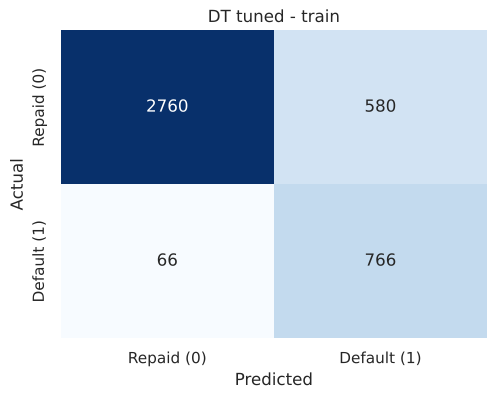

Test performance - Decision Tree (tuned)
              precision    recall  f1-score   support

           0      0.948     0.819     0.879      1431
           1      0.531     0.821     0.645       357

    accuracy                          0.819      1788
   macro avg      0.740     0.820     0.762      1788
weighted avg      0.865     0.819     0.832      1788



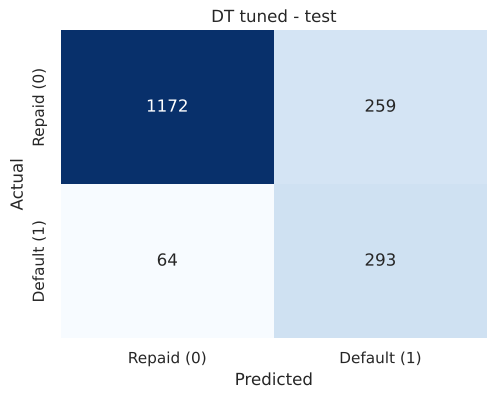

Tree depth: 14 | number of leaves: 106


In [55]:
# Score the tuned tree on the training and test rows
print("Train performance - Decision Tree (tuned)")
metrics_score(y_train, dt_tuned.predict(X_train), title="DT tuned - train")
print("Test performance - Decision Tree (tuned)")
metrics_score(y_test, dt_tuned.predict(X_test), title="DT tuned - test")
results.append(model_scores(dt_tuned, X_train, y_train, X_test, y_test, "Decision Tree (tuned)"))
print("Tree depth:", dt_tuned.get_depth(), "| number of leaves:", dt_tuned.get_n_leaves())

**Observations - tuned Decision Tree:**
- Pruning (a minimum of 20 applicants per leaf) cuts the tree from several hundred leaves to about 100. Combined with balanced class weights, it lifts **test recall to about 82%**, the highest of the single-model approaches. The train-test gap narrows from about 30 points to about 10 (92% vs 82%), so over-fitting is much smaller though not gone.
- The price is precision: only about 53% of the applicants the tree rejects would actually have defaulted, and overall accuracy falls to about 82%. The tree is deliberately cautious - it flags anyone who looks even moderately risky.
- This is the recall-precision trade-off in action. Whether 53% precision is acceptable depends on how much good business the bank is willing to decline. The ensembles below improve this balance.

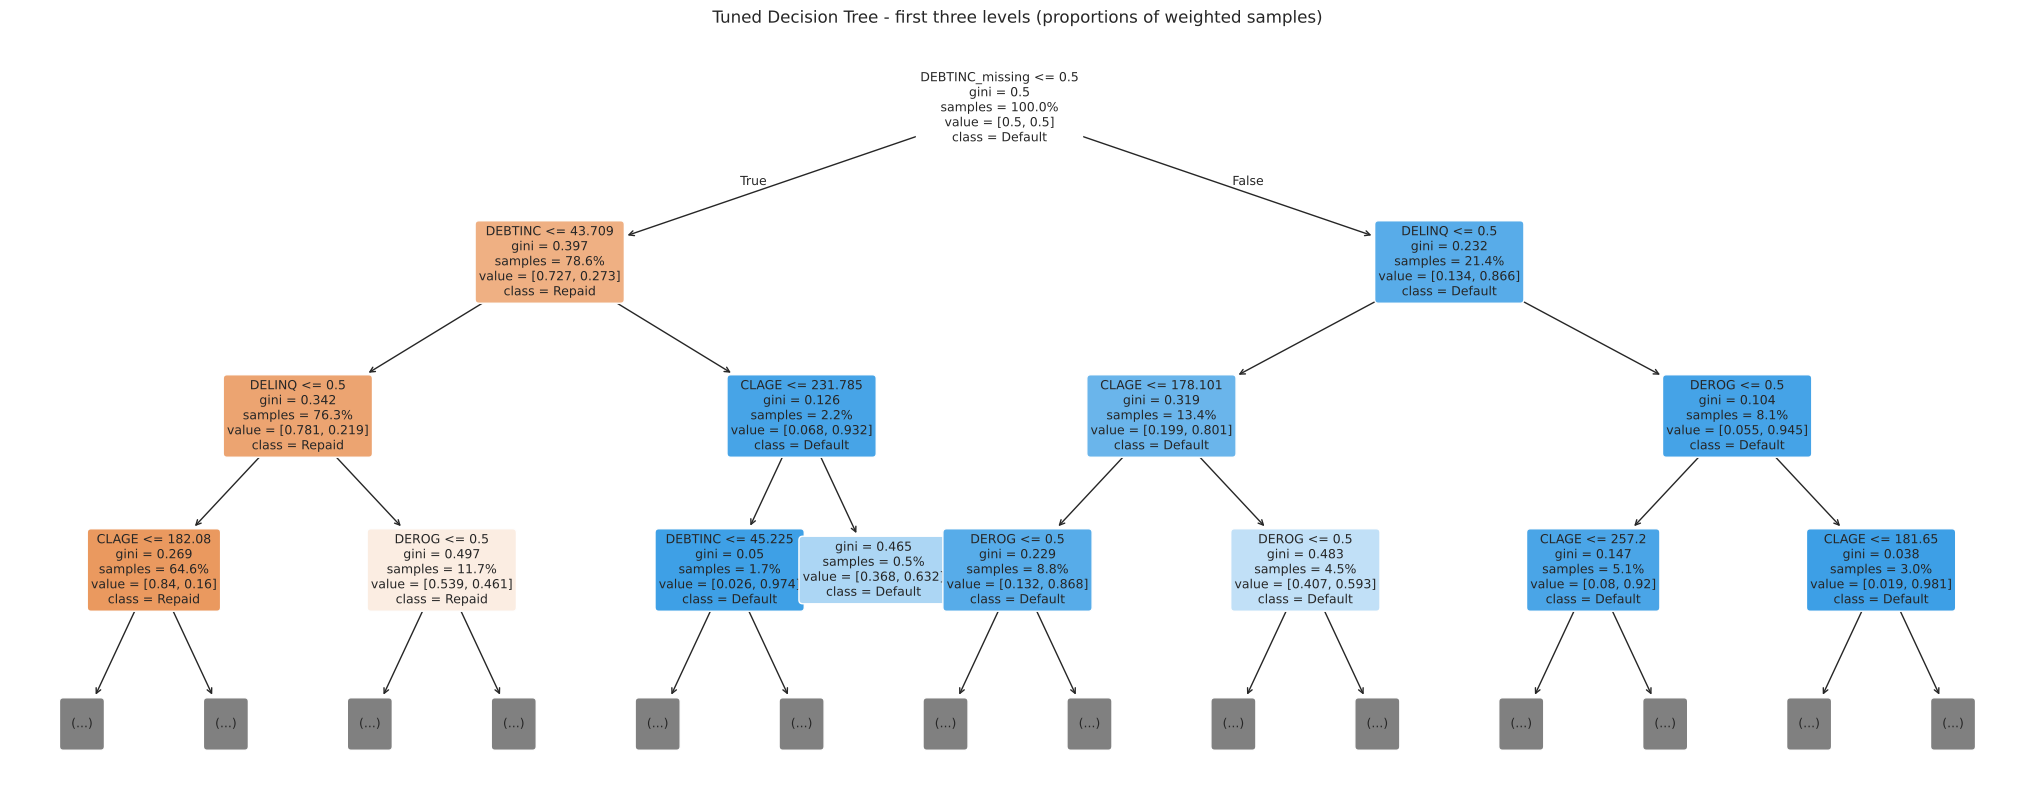

In [56]:
# Visualise the top levels of the tuned tree (the full tree is deeper; the first 3 levels carry the main rules)
plt.figure(figsize=(26, 10))
plot_tree(dt_tuned, feature_names=X_train.columns, class_names=["Repaid", "Default"],
          filled=True, rounded=True, max_depth=3, fontsize=9, proportion=True)
plt.title("Tuned Decision Tree - first three levels (proportions of weighted samples)")
plt.show()

In [57]:
# Text version of the decision rules (first three levels). Note: the tree was fitted with balanced class weights,
# so a leaf labelled 'class: 1' means the weighted majority is 'default', i.e. a raw default rate above roughly 20%,
# not a near-certain default. The observed default rates of the main rules are computed next.
print(export_text(dt_tuned, feature_names=list(X_train.columns), max_depth=3, show_weights=False))

|--- DEBTINC_missing <= 0.50
|   |--- DEBTINC <= 43.71
|   |   |--- DELINQ <= 0.50
|   |   |   |--- CLAGE <= 182.08
|   |   |   |   |--- truncated branch of depth 11
|   |   |   |--- CLAGE >  182.08
|   |   |   |   |--- truncated branch of depth 10
|   |   |--- DELINQ >  0.50
|   |   |   |--- DEROG <= 0.50
|   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- DEROG >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |--- DEBTINC >  43.71
|   |   |--- CLAGE <= 231.79
|   |   |   |--- DEBTINC <= 45.23
|   |   |   |   |--- class: 1
|   |   |   |--- DEBTINC >  45.23
|   |   |   |   |--- class: 1
|   |   |--- CLAGE >  231.79
|   |   |   |--- class: 1
|--- DEBTINC_missing >  0.50
|   |--- DELINQ <= 0.50
|   |   |--- CLAGE <= 178.10
|   |   |   |--- DEROG <= 0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- DEROG >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- CLAGE >  178.10
|   |   |   |--- DEROG <= 0.50
|   |   |   |   |--- tr

In [58]:
# Observed default rate (training rows) of the groups defined by the tree's first splits
tr = data.loc[train_idx]
root_split = dt_tuned.tree_.threshold[dt_tuned.tree_.children_left[0]]   # DEBTINC threshold under 'DEBTINC_missing <= 0.5'
groups = {
    "Debt-to-income ratio missing": tr["DEBTINC_missing"] == 1,
    f"Ratio recorded and above {root_split:.1f}%": (tr["DEBTINC_missing"] == 0) & (tr["DEBTINC"] > root_split),
    f"Ratio recorded, at most {root_split:.1f}%, 1+ delinquent lines": (tr["DEBTINC_missing"] == 0) & (tr["DEBTINC"] <= root_split) & (tr["DELINQ"] >= 1),
    f"Ratio recorded, at most {root_split:.1f}%, no delinquent lines": (tr["DEBTINC_missing"] == 0) & (tr["DEBTINC"] <= root_split) & (tr["DELINQ"] == 0),
}
pd.DataFrame({"applicants": {k: int(v.sum()) for k, v in groups.items()},
              "default_rate_%": {k: round(tr.loc[v, "BAD"].astype(int).mean() * 100, 1) for k, v in groups.items()}})

,applicants,default_rate_%
Debt-to-income ratio missing,894,61.700
Ratio recorded and above 43.7%,93,77.400
"Ratio recorded, at most 43.7%, 1+ delinquent lines",490,17.600
"Ratio recorded, at most 43.7%, no delinquent lines",2695,4.500


**Business rules deduced from the tree:**

The top of the tree, with the observed default rates of each group, gives the bank plain-language rules. The bank can defend these rules in front of an applicant or a regulator:

1. **Is the debt-to-income ratio missing?** If yes, the applicant is in a high-risk group: about 62% of these applicants defaulted. If income is unverified, the bank should either reject the applicant or require an income-verification step.
2. **If the ratio is recorded, is it above about 44%?** If yes, roughly three out of four defaulted (and above 45% the EDA showed 87% to 100%): decline.
3. **Below that ratio, how many delinquent credit lines does the applicant have?** With none, only about 4-5% default (the safest group in the book). With one or more, the rate is about four times higher and the tree asks further questions.
4. **Among the remaining applicants, how long is the credit history (CLAGE) and are there derogatory reports (DEROG)?** Short histories (under about 15 years) with any derogatory report are risky. Long clean histories are safe.
5. **In the "ratio missing" branch the tree asks the same questions again** (delinquencies, derogatory reports, credit-history length, loan size). Almost every path that combines a missing ratio with any delinquency or derogatory report ends in "default".

These rules match the EDA findings exactly, which is reassuring: the model formalises the patterns in the data rather than inventing new ones.

### Bagging (Bootstrap Aggregating): from one tree to many

A single decision tree has **high variance**: small changes in the training rows produce a different tree. This is why the fully grown tree scored 100% on the training rows and far less on the test set. **Bagging** trains many trees, each on a *bootstrap sample* (a random sample of the training applicants drawn with replacement), and combines their votes. Averaging many over-fitted trees cancels their individual errors, which lowers variance without raising bias.

A Random Forest is bagging plus one more idea (a random subset of features at every split). So we build a plain bagged ensemble first, to show how much of the improvement comes from bagging alone.

Train performance - Bagging (200 trees)


              precision    recall  f1-score   support

           0      1.000     1.000     1.000      3340
           1      1.000     1.000     1.000       832

    accuracy                          1.000      4172
   macro avg      1.000     1.000     1.000      4172
weighted avg      1.000     1.000     1.000      4172



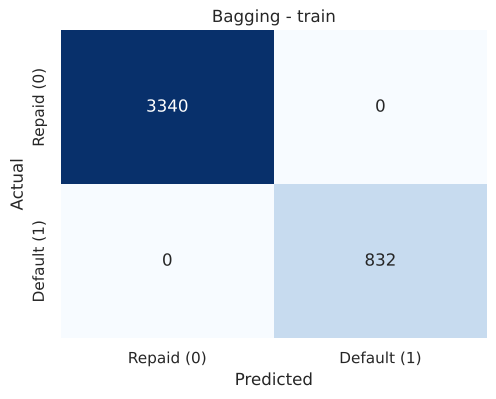

Test performance - Bagging (200 trees)


              precision    recall  f1-score   support

           0      0.924     0.964     0.944      1431
           1      0.827     0.683     0.748       357

    accuracy                          0.908      1788
   macro avg      0.876     0.824     0.846      1788
weighted avg      0.905     0.908     0.905      1788



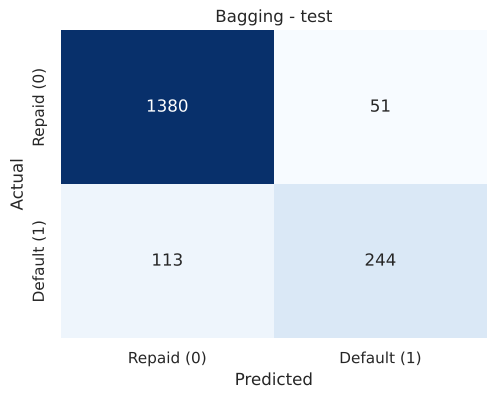

In [59]:
# Bagging of 200 fully grown decision trees
bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
bag.fit(X_train, y_train)

print("Train performance - Bagging (200 trees)")
metrics_score(y_train, bag.predict(X_train), title="Bagging - train")
print("Test performance - Bagging (200 trees)")
metrics_score(y_test, bag.predict(X_test), title="Bagging - test")
results.append(model_scores(bag, X_train, y_train, X_test, y_test, "Bagging (200 trees)"))

In [60]:
# Does weighting the base trees towards the defaulter class help a bagged ensemble?
bag_cw = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight={0: 0.2, 1: 0.8}),
                           n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
bag_cw.fit(X_train, y_train)
results.append(model_scores(bag_cw, X_train, y_train, X_test, y_test, "Bagging (class-weighted trees)"))
pd.concat(results[-2:], ignore_index=True).set_index("Model").round(3)

,Train Recall,Test Recall,Train Precision,Test Precision,Train F1,Test F1,Train Accuracy,Test Accuracy,Test ROC-AUC
Model,,,,,,,,,
Bagging (200 trees),1.000,0.683,1.000,0.827,1.000,0.748,1.000,0.908,0.945
Bagging (class-weighted trees),1.000,0.597,1.000,0.810,1.000,0.687,1.000,0.891,0.946


**Observations - Bagging:**
- Averaging 200 trees lifts **test precision from 71% (single tree) to about 83% and ROC-AUC from 0.81 to about 0.95**. Recall stays the same (about 68%). That is the variance reduction bagging promises. The ensemble is right far more often when it flags a defaulter, and it ranks applicants by risk almost as well as the forest will.
- Train recall is still 100%: bagging limits the *damage* of over-fitting on unseen data. It does not stop each tree from memorising its sample.
- Weighting the base trees towards the defaulter class does **not** raise recall (it falls to about 60%). As with the single tree, the weights change which splits each fully grown tree makes. They do not change the fact that each tree fits its bootstrap sample perfectly. The forest sections and the final selection below test whether class weights help an ensemble. They also test whether an ensemble needs the weights at all once we tune the decision threshold.
- A bagged ensemble still misses about a third of defaulters. The random forest adds feature sub-sampling, which de-correlates the trees and should improve ranking. At the 0.5 threshold, class weights are then one way to trade some precision for recall.

### **Building a Random Forest Classifier**

**Random Forest is a bagging algorithm where the base models are Decision Trees.** The algorithm takes samples from the training data, and on each sample a decision tree makes a prediction.

**The forest combines the results from all the decision trees and makes the final prediction by voting or averaging.**

Each tree sees a different bootstrap sample and a random subset of features at each split. Because of this, the individual over-fitted trees balance each other in the average. This usually improves test performance greatly over a single tree, and the forest keeps the ability to model thresholds. The cost is interpretability: we cannot read a forest of hundreds of trees as a rule list. So we will use **feature importances** and, for the final model, a **surrogate decision tree** to explain it.

Train performance - Random Forest (default)
              precision    recall  f1-score   support

           0      1.000     1.000     1.000      3340
           1      1.000     1.000     1.000       832

    accuracy                          1.000      4172
   macro avg      1.000     1.000     1.000      4172
weighted avg      1.000     1.000     1.000      4172



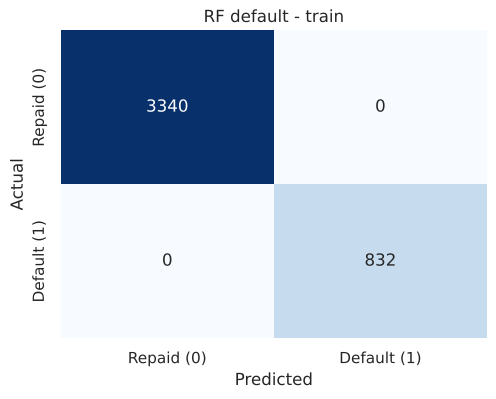

Test performance - Random Forest (default)


              precision    recall  f1-score   support

           0      0.925     0.968     0.946      1431
           1      0.842     0.686     0.756       357

    accuracy                          0.912      1788
   macro avg      0.884     0.827     0.851      1788
weighted avg      0.909     0.912     0.908      1788



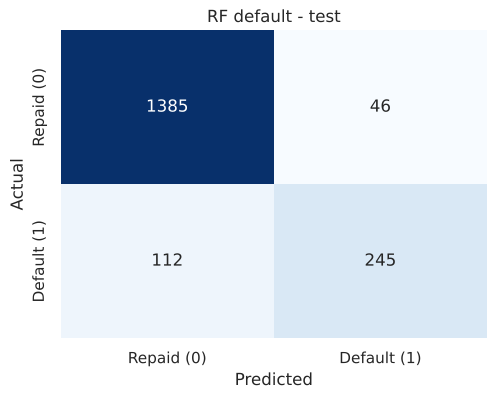

In [61]:
# Baseline random forest
rf_base = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train, y_train)

print("Train performance - Random Forest (default)")
metrics_score(y_train, rf_base.predict(X_train), title="RF default - train")
print("Test performance - Random Forest (default)")
metrics_score(y_test, rf_base.predict(X_test), title="RF default - test")
results.append(model_scores(rf_base, X_train, y_train, X_test, y_test, "Random Forest (default)"))

**Observations - default Random Forest:**
- Like the single tree, the forest fits the training rows perfectly, but on the test set it does much better. It scores about **69% recall with 84% precision**, 91% accuracy and a ROC-AUC of about 0.96 (the best ranking ability of all the models).
- The forest is conservative about flagging an applicant as a defaulter: when it does, it is right 84% of the time. But it still misses about a third of the defaulters. Class weights should shift that balance towards recall.

### **Build a Random Forest model with Class Weights**

Train performance - Random Forest (class weights 0.2/0.8)
              precision    recall  f1-score   support

           0      1.000     0.998     0.999      3340
           1      0.993     1.000     0.996       832

    accuracy                          0.999      4172
   macro avg      0.996     0.999     0.998      4172
weighted avg      0.999     0.999     0.999      4172



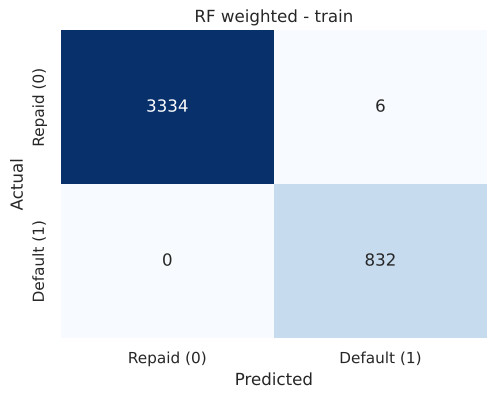

Test performance - Random Forest (class weights 0.2/0.8)
              precision    recall  f1-score   support

           0      0.943     0.942     0.943      1431
           1      0.769     0.773     0.771       357

    accuracy                          0.908      1788
   macro avg      0.856     0.858     0.857      1788
weighted avg      0.908     0.908     0.908      1788



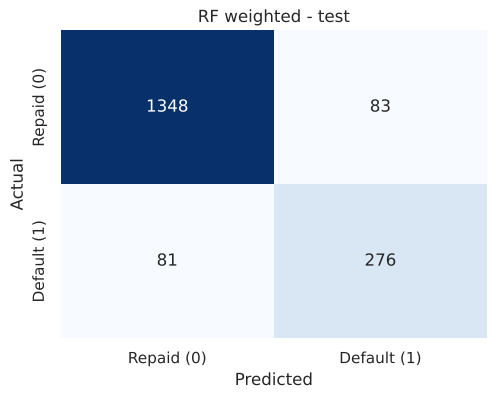

In [62]:
# Fit a forest of 200 trees. The 0.2/0.8 weights make each defaulter count four times as much as a repayer.
rf_cw = RandomForestClassifier(n_estimators=200, class_weight={0: 0.2, 1: 0.8},
                               random_state=RANDOM_STATE, n_jobs=-1)
rf_cw.fit(X_train, y_train)

print("Train performance - Random Forest (class weights 0.2/0.8)")
metrics_score(y_train, rf_cw.predict(X_train), title="RF weighted - train")
print("Test performance - Random Forest (class weights 0.2/0.8)")
metrics_score(y_test, rf_cw.predict(X_test), title="RF weighted - test")
results.append(model_scores(rf_cw, X_train, y_train, X_test, y_test, "Random Forest (class weights)"))

**Observations - weighted Random Forest:**
- Class weights lift **test recall to about 77%** while precision stays near 77% and accuracy near 91%. Unlike the single tree, the forest's recall responds to class weights at the 0.5 threshold. The weights shift the ensemble's averaged probabilities, which moves applicants across the fixed threshold. The final selection tests whether that shift is better than simply moving the threshold.
- This is the best balance of recall and precision so far. The forest catches almost as many defaulters as the balanced logistic regression (77% vs 80%) with far higher precision (77% vs 61%). So it declines far fewer good applicants.
- Train scores are still near-perfect, so there is residual over-fitting of the training labels. We judge below whether that hurts on unseen applicants, with out-of-fold cross-validation rather than training scores.

### **Random Forest Classifier Hyperparameter Tuning**

We search over the number of trees, maximum depth, minimum leaf size, the number of features considered per split and the class weights. Again we use **stratified 3-fold cross-validation on the training rows and Recall as the scoring metric**. (3 folds instead of 5 keep the run time reasonable for the larger forest grid.)

In [63]:
# Test every combination of forest settings. Use 3 folds to keep the run time short.
rf_grid = {
    "n_estimators": [150, 300],
    "max_depth": [6, 10, None],
    "min_samples_leaf": [1, 5, 10],
    "max_features": ["sqrt", 0.5],
    "class_weight": ["balanced", {0: 0.2, 1: 0.8}],
}

rf_search = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), rf_grid,
                         scoring="recall", cv=cv3, n_jobs=-1)
rf_search.fit(X_train, y_train)

print("Best parameters :", rf_search.best_params_)
print(f"Best CV recall  : {rf_search.best_score_:.3f}")
rf_tuned = rf_search.best_estimator_

Best parameters : {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 300}
Best CV recall  : 0.811


Train performance - Random Forest (tuned for recall)
              precision    recall  f1-score   support

           0      0.978     0.901     0.938      3340
           1      0.699     0.918     0.794       832

    accuracy                          0.905      4172
   macro avg      0.838     0.910     0.866      4172
weighted avg      0.922     0.905     0.909      4172



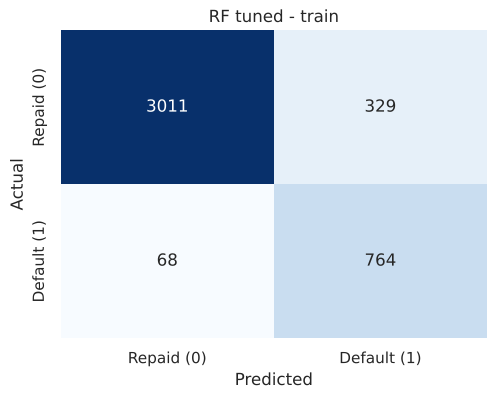

Test performance - Random Forest (tuned for recall)
              precision    recall  f1-score   support

           0      0.945     0.897     0.920      1431
           1      0.656     0.790     0.717       357

    accuracy                          0.875      1788
   macro avg      0.800     0.843     0.818      1788
weighted avg      0.887     0.875     0.879      1788



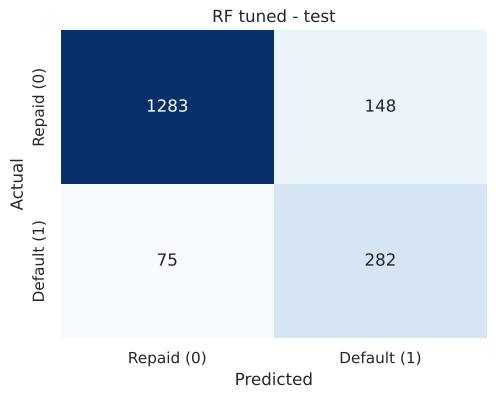

In [64]:
# Score the recall-tuned forest on the training and test rows
print("Train performance - Random Forest (tuned for recall)")
metrics_score(y_train, rf_tuned.predict(X_train), title="RF tuned - train")
print("Test performance - Random Forest (tuned for recall)")
metrics_score(y_test, rf_tuned.predict(X_test), title="RF tuned - test")
results.append(model_scores(rf_tuned, X_train, y_train, X_test, y_test, "Random Forest (tuned, recall)"))

**Observations - recall-tuned Random Forest:**
- Optimising purely for recall pushes the grid towards larger leaves (10 applicants minimum) and balanced weights. Test recall lands at about **79%**, close to the weighted forest. But precision drops to about 66% because the forest becomes more willing to flag borderline applicants.
- The train-test gap shrinks (train recall is no longer 100%), so the tuned forest memorises less, even though its headline test numbers are no better.
- Recall-only tuning illustrates the limitation of a single-metric search on an imbalanced problem: beyond a point, extra recall costs a lot of precision. This is why we choose the final model on expected cost, not on recall alone.

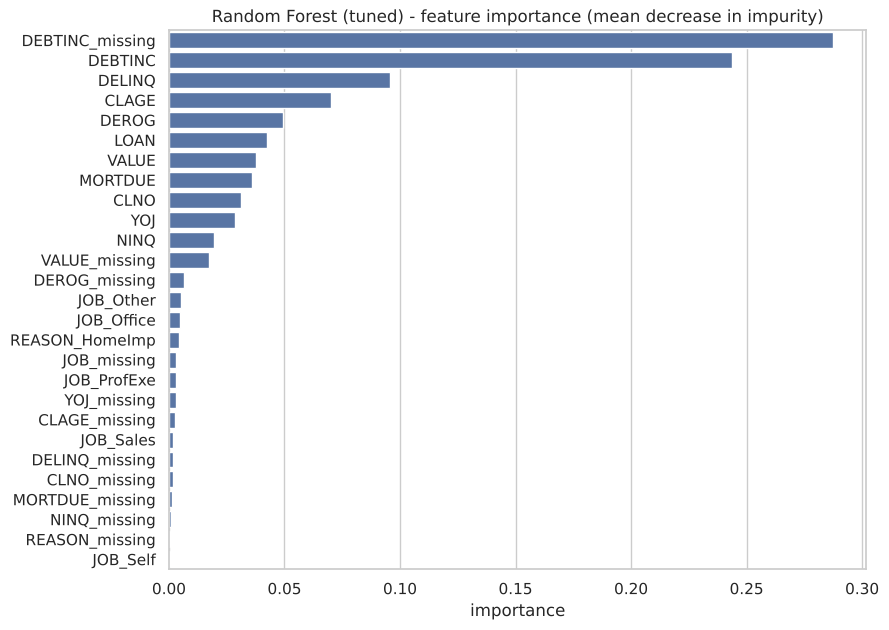

,importance
DEBTINC_missing,0.287
DEBTINC,0.244
DELINQ,0.096
CLAGE,0.070
DEROG,0.049
LOAN,0.042
VALUE,0.038
MORTDUE,0.036
CLNO,0.031
YOJ,0.028


In [65]:
# Feature importance of the recall-tuned random forest, used to test a leaner feature set
importances = pd.Series(rf_tuned.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
sns.barplot(x=importances.values, y=importances.index, color="#4C72B0")
plt.title("Random Forest (tuned) - feature importance (mean decrease in impurity)")
plt.xlabel("importance"); plt.ylabel("")
plt.show()
importances.round(4).to_frame("importance").head(12)

**Insights - what the forest relies on:**
- The two debt-to-income features dominate: **`DEBTINC_missing` and `DEBTINC` together provide about half of this forest's split power.** This agrees with the EDA finding that affordability, and whether the bank could check it, is the heart of the decision.
- Next come **`DELINQ`, `CLAGE` and `DEROG`** (past repayment behaviour and depth of credit history), then `LOAN`, `VALUE`, `MORTDUE` and `CLNO`.
- `NINQ`, `YOJ` and `VALUE_missing` contribute modestly. The `JOB` and `REASON` dummies rank at the bottom: once the model knows the financial behaviour, occupation and loan purpose add little on their own. (Mean-decrease-in-impurity importance favours continuous variables with many split points, so we complement it below with permutation importance for the final model.)

#### Improving the forest by removing weak variables

A best-practice check: does the model keep its performance with fewer inputs? A leaner model is cheaper to maintain, easier to explain and less prone to learning spurious patterns. We refit the recall-tuned forest on only the features with importance above 1%. In the final selection this 12-input set is a candidate only for the recall-tuned forest. The chosen forest gets its own input set from a cost curve (Stage 2 of the selection). There the rule keeps the smallest input set whose seed-averaged out-of-fold cost is within one standard error of the lowest cost on the curve.

Keeping 12 of 27 features: ['DEBTINC_missing', 'DEBTINC', 'DELINQ', 'CLAGE', 'DEROG', 'LOAN', 'VALUE', 'MORTDUE', 'CLNO', 'YOJ', 'NINQ', 'VALUE_missing']
Dropped: ['MORTDUE_missing', 'REASON_missing', 'JOB_missing', 'YOJ_missing', 'DEROG_missing', 'DELINQ_missing', 'CLAGE_missing', 'NINQ_missing', 'CLNO_missing', 'REASON_HomeImp', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']


Test performance - Random Forest (tuned, reduced features)
              precision    recall  f1-score   support

           0      0.944     0.899     0.921      1431
           1      0.660     0.784     0.717       357

    accuracy                          0.876      1788
   macro avg      0.802     0.842     0.819      1788
weighted avg      0.887     0.876     0.880      1788



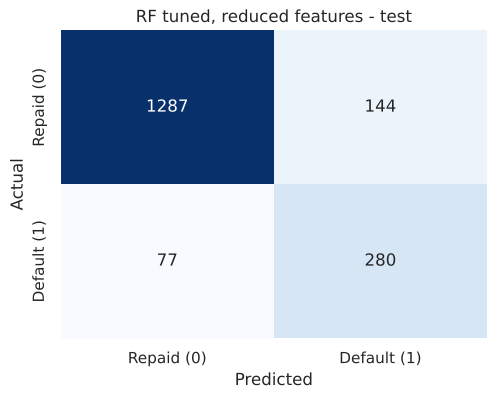

In [66]:
# Keep only the inputs with an importance above 1%, then refit the tuned forest on them
keep = importances[importances > 0.01].index.tolist()
dropped = [c for c in X_train.columns if c not in keep]
print(f"Keeping {len(keep)} of {X_train.shape[1]} features: {keep}")
print(f"Dropped: {dropped}")

rf_lean = RandomForestClassifier(**{k: v for k, v in rf_search.best_params_.items()},
                                 random_state=RANDOM_STATE, n_jobs=-1)
rf_lean.fit(X_train[keep], y_train)

print("Test performance - Random Forest (tuned, reduced features)")
metrics_score(y_test, rf_lean.predict(X_test[keep]), title="RF tuned, reduced features - test")
results.append(model_scores(rf_lean, X_train[keep], y_train, X_test[keep], y_test, "Random Forest (tuned, reduced features)"))

**Observations:**
- At the default 0.5 threshold, removing the 15 low-importance columns changes test recall and precision by about a point. (The removed columns are all occupation and loan-purpose dummies and nine of the eleven missing-value flags.) For this model the signal lives mainly in 12 variables: the ten financial attributes plus the `DEBTINC` and `VALUE` missing flags.
- The next section tests properly whether the leaner set is also good enough at the business-optimal threshold. There the recall-tuned forest on these 12 inputs competes against the same forest on all 27 inputs, on expected cost.

#### Did tuning improve the validation scores?

The grid searches above give no cross-validated score for the untuned baselines. Here we score each untuned baseline on the same folds, so that we can compare before and after tuning on the training rows. The test set plays no part.

In [67]:
# Validation scores before and after tuning, on the same folds that each grid search used (training rows only).
# This shows that tuning improves the cross-validated scores, not only the test scores.
before_after = [
    ("Logistic Regression", "before: plain", lr_plain, X_train_lr_s, y_train_lr, cv5),
    ("Logistic Regression", "after: balanced, C tuned", lr_bal, X_train_lr_s, y_train_lr, cv5),
    ("Decision Tree", "before: fully grown", dt_base, X_train, y_train, cv5),
    ("Decision Tree", "after: grid search", dt_tuned, X_train, y_train, cv5),
    ("Random Forest", "before: default", rf_base, X_train, y_train, cv3),
    ("Random Forest", "class weights 0.2/0.8", rf_cw, X_train, y_train, cv3),
    ("Random Forest", "after: grid search", rf_tuned, X_train, y_train, cv3),
]
tuning_rows = []
for technique, stage, model, X_cv, y_cv, folds in before_after:
    cv_scores = cross_validate(clone(model), X_cv, y_cv, cv=folds, scoring=["recall", "precision", "roc_auc"], n_jobs=-1)
    tuning_rows.append({"Technique": technique, "Stage": stage, "CV recall": cv_scores["test_recall"].mean(),
                        "CV precision": cv_scores["test_precision"].mean(), "CV ROC-AUC": cv_scores["test_roc_auc"].mean()})
pd.DataFrame(tuning_rows).set_index(["Technique", "Stage"]).round(3)

CV recall  CV precision  \
Technique           Stage                                               
Logistic Regression before: plain                 0.626         0.789   
                    after: balanced, C tuned      0.814         0.598   
Decision Tree       before: fully grown           0.644         0.663   
                    after: grid search            0.826         0.533   
Random Forest       before: default               0.703         0.829   
                    class weights 0.2/0.8         0.790         0.757   
                    after: grid search            0.811         0.640   

                                              CV ROC-AUC  
Technique           Stage                                 
Logistic Regression before: plain                  0.907  
                    after: balanced, C tuned       0.907  
Decision Tree       before: fully grown            0.781  
                    after: grid search             0.881  
Random Forest       before: default                0.954  
                    class weights 0.2/0.8          0.952  
                    after: grid search             0.921

**Observations - validation scores before and after tuning:**
- Tuning raises the cross-validated recall of each tuned technique. Logistic regression rises from 0.626 to 0.814, almost all from the balanced class weights. The grid above shows that `C` moves it by less than two points. The decision tree rises from 0.644 to 0.826. The random forest rises from 0.703 to 0.811 (0.790 with class weights alone).
- The test set shows the same direction (0.566 to 0.796, 0.686 to 0.821 and 0.686 to 0.790). So the gains do not come from one lucky split.
- Recall-only tuning costs precision in every case (0.789 to 0.598, 0.663 to 0.533 and 0.829 to 0.640). It also lowers the forest's cross-validated ROC-AUC from 0.954 to 0.921. This is why we choose the final configuration and its threshold on expected cost in the selection section below.

## **Model Performance Comparison and Final Model Selection**

**1. Comparison of various techniques and their relative performance based on chosen Metric (Measure of success):**
- How do different techniques perform? Which one is performing relatively better? Is there scope to improve the performance further?

In [68]:
# Put the scores of all models in one table. Darker cells show higher test scores.
comparison = pd.concat(results, ignore_index=True).set_index("Model")
comparison.style.format("{:.3f}").background_gradient(subset=["Test Recall", "Test Precision", "Test F1", "Test ROC-AUC"], cmap="Blues")

,Train Recall,Test Recall,Train Precision,Test Precision,Train F1,Test F1,Train Accuracy,Test Accuracy,Test ROC-AUC
Model,,,,,,,,,
Logistic Regression (plain),0.635,0.566,0.799,0.774,0.707,0.654,0.895,0.880,0.907
Logistic Regression (balanced),0.821,0.796,0.598,0.608,0.692,0.689,0.854,0.857,0.906
Decision Tree (default),1.000,0.686,1.000,0.706,1.000,0.696,1.000,0.880,0.807
Decision Tree (class weights),1.000,0.616,1.000,0.719,1.000,0.664,1.000,0.875,0.778
Decision Tree (tuned),0.921,0.821,0.569,0.531,0.703,0.645,0.845,0.819,0.877
Bagging (200 trees),1.000,0.683,1.000,0.827,1.000,0.748,1.000,0.908,0.945
Bagging (class-weighted trees),1.000,0.597,1.000,0.810,1.000,0.687,1.000,0.891,0.946
Random Forest (default),1.000,0.686,1.000,0.842,1.000,0.756,1.000,0.912,0.963
Random Forest (class weights),1.000,0.773,0.993,0.769,0.996,0.771,0.999,0.908,0.959


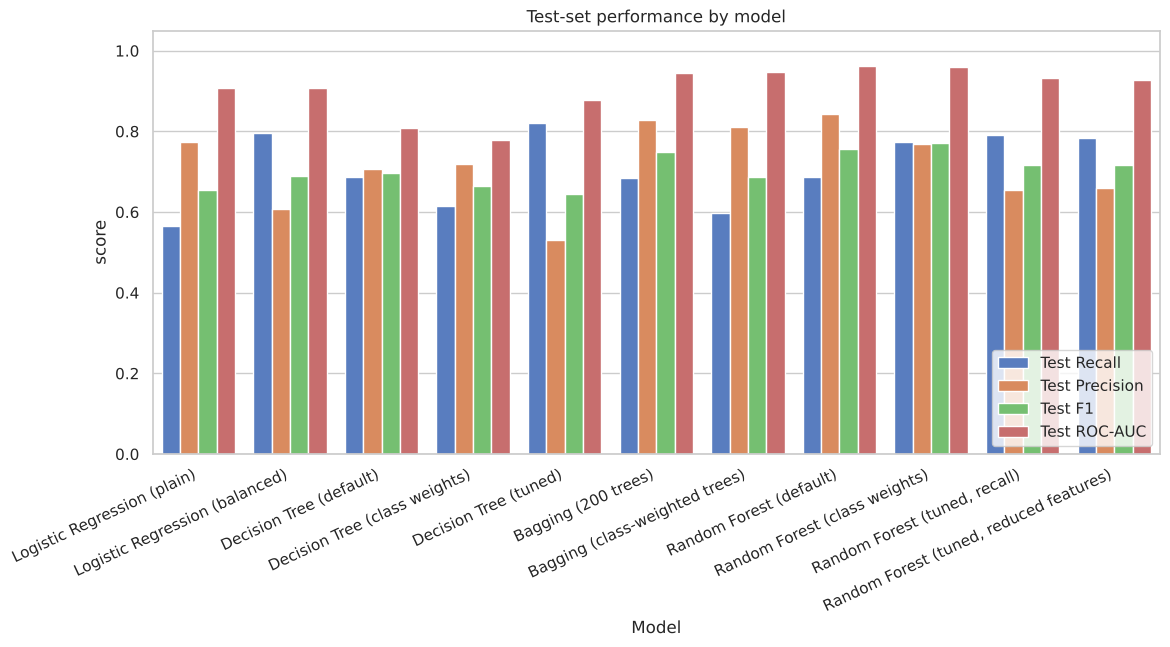

In [69]:
# Visual comparison on the test set
plot_df = comparison[["Test Recall", "Test Precision", "Test F1", "Test ROC-AUC"]].reset_index().melt(
    id_vars="Model", var_name="metric", value_name="score")
plt.figure(figsize=(13, 5.5))
ax = sns.barplot(data=plot_df, x="Model", y="score", hue="metric", palette="muted")
plt.xticks(rotation=25, ha="right"); plt.ylim(0, 1.05)
plt.title("Test-set performance by model"); plt.legend(loc="lower right")
plt.show()

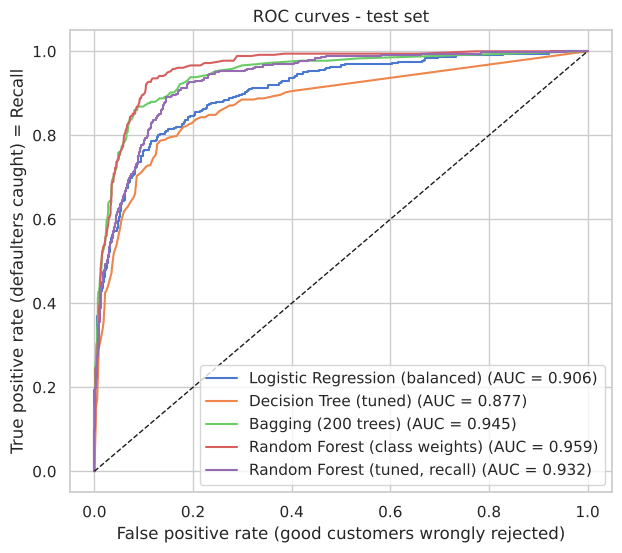

In [70]:
# ROC curves for the main candidates on the test set
plt.figure(figsize=(7, 6))
for name, model, Xt in [("Logistic Regression (balanced)", lr_bal, X_test_lr_s),
                        ("Decision Tree (tuned)", dt_tuned, X_test),
                        ("Bagging (200 trees)", bag, X_test),
                        ("Random Forest (class weights)", rf_cw, X_test),
                        ("Random Forest (tuned, recall)", rf_tuned, X_test)]:
    pr = model.predict_proba(Xt)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, pr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, pr):.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False positive rate (good customers wrongly rejected)")
plt.ylabel("True positive rate (defaulters caught) = Recall")
plt.title("ROC curves - test set"); plt.legend(); plt.show()

**Comparison - how the techniques perform (at the default 0.5 threshold):**

*Linear vs non-linear.* The balanced logistic regression reaches about 80% recall but only about 61% precision and a ROC-AUC of about 0.91. Every random forest beats it on precision and AUC. The class-weighted and recall-tuned forests do this at a similar recall (77% to 79% against 80%). This shows that trees capture the threshold-shaped relationships in this data better. The linear model remains the most transparent benchmark.

*Single tree vs bagging vs forest.* The tuned decision tree achieves the **highest raw recall (about 82%)** but the **lowest precision (about 53%)**. It would reject almost one good applicant for every defaulter it catches. Bagging 200 trees shows the value of averaging. At the same 68% recall as the single fully grown tree, precision rises to about 83% and ROC-AUC from 0.81 to about 0.95.

The random forests add feature sub-sampling. Without class weights the forest is the most precise model at 0.5 (69% recall at 84% precision) and ranks applicants best of all (ROC-AUC 0.963). With class weights or recall tuning it reaches 77-79% recall at 66-77% precision, a far better balance than the single tree at this threshold.

*Among the forests.* The class-weighted forest (0.2/0.8) has the best F1 (about 0.77) and precision at the same recall. The recall-tuned forest has the same recall with lower precision but a smaller train-test gap. The reduced-feature forest performs essentially the same as the tuned one with 12 instead of 27 inputs. This table cannot show which of these is best for the bank. This is because the business cares about the cost of the two errors at the best operating threshold, not at 0.5. We choose among them next, on the training rows.

*Which technique performs relatively better?* The Random Forest performs relatively better. In the table above, the unweighted forest has the best ROC-AUC (0.963) and the class-weighted forest has the best F1 (0.771). Stage 3 below compares each technique at its own cost-minimising threshold. There the 22-input forest costs \$324,145 per 1,000 applicants, against \$389,821 for bagging, \$550,176 for the logistic regression and \$607,223 for the tuned tree. It wins because it averages many fully grown trees that differ from each other. Their averaged scores follow the thresholds and combined risk factors in the data, so the forests rank applicants best (out-of-fold ROC-AUC 0.96).

*Is there scope to improve further?* Yes, in three directions:
1. **Threshold tuning** on the chosen forest (next section) moves recall above 90% at a controlled precision cost, because the forest's AUC is high.
2. **Feature engineering** such as a loan-to-value ratio ((LOAN + MORTDUE) / VALUE), binned debt-to-income or interaction terms. The trees approximate these features but could use them directly. These features would also help the linear model. Binned debt-to-income captures the step in risk at a 45% ratio (EDA insight 3). Interaction terms capture the combined risk factors (EDA insight 10), such as delinquent lines inside the lower debt-to-income bands. A loan-to-value ratio joins the loan, mortgage and property amounts, which matter in combination rather than alone.
3. **Gradient boosting and probability calibration.** Gradient boosting builds trees one after another, and each new tree corrects the errors of the earlier trees. It keeps what makes trees fit this data (thresholds, combined risk factors and blank fields). On tabular data like this it often ranks applicants better than a random forest. Calibration matters because the forest's scores understate risk in the decision range (see the calibration check below). Both were outside the scope of this milestone, and we list them as next steps.

#### Implementation feasibility, risks and benefits of each technique

Performance is only one side of the decision. The table below weighs each technique on how practical it is to put in front of the bank's credit officers and regulators.

| Technique | Interpretability (ECOA adverse-action reasons) | Build and run cost | Stability and maintenance | Main risks | Verdict |
|---|---|---|---|---|---|
| Logistic Regression (balanced) | Excellent: one coefficient per attribute, and the bank can quote odds ratios directly | Trivial. Trains in under a second. Needs scaling and outlier capping in the pipeline | Very stable across re-trainings | Under-fits threshold effects on the raw inputs, so at the same recall it declines many more good applicants than the forest. Needs careful handling of correlated inputs (MORTDUE/VALUE) | Keep as the transparent benchmark and challenger model |
| Decision Tree (tuned) | Excellent: a short rule list a credit officer can read | Trivial | Unstable: small changes in the training rows can re-shape the tree. The bank must check it again at every re-train | Lowest precision (53%): too much good business declined | Use as a rule summary, not as the scorer |
| Bagged trees (200) | Same as the forest: importances and per-applicant risk drivers, no rule list | Low | Stable, like the forest | Class weights do not move its recall, so it catches only about two thirds of defaulters. Below the forest on every metric | The Random Forest supersedes it |
| Random Forest (unweighted, class-weighted or tuned) | Good with the right tooling: global importances, a surrogate tree that reproduces most of its decisions, and per-applicant risk drivers (built before the shadow run). Not a rule list on its own | Low: trains in seconds, scores in milliseconds. 200-300 trees are trivial to host | Stable: averaging removes single-tree instability. Needs drift monitoring and yearly re-training like any credit model | Some stakeholders perceive it as a black box. Needs model-risk documentation and a fairness review before the bank starts to use it | **Adopt as the scoring engine**, with the surrogate tree for explanations |

**A caveat that applies to every technique.** The data contains only loans the bank *approved* under its current process (the problem statement: "recent applicants who have been given credit"). The models therefore never saw the applicants the old process declined. The "approve all" baseline used below describes the outcome of today's process on the applicants it accepts, not the full applicant population. For this reason we list reject inference and a shadow period on all applications as risks and next steps.

### Choosing the final model and its decision threshold, on training rows only

Above, we compared the models at the conventional 0.5 threshold. We never tested the class weights used so far (0.2/0.8 by convention, `balanced` from a recall-only grid search) against the business criterion. The bank's real question is: **which forest configuration, at its best threshold, produces the lowest expected cost of credit errors?** Class weights and the decision threshold are two dials for the same trade-off (how readily the model flags an applicant). So we must choose them together and on that criterion.

To answer it **without touching the test set**, we score every candidate with **repeated 5-fold out-of-fold predictions on the training rows**. We use three different stratified 5-fold splits. So each training applicant receives three probabilities from models that never saw them, and we judge every candidate on 15 validation folds. For each candidate we find, on those out-of-fold predictions, the threshold that minimises the mean of the indicative expected cost.

**Selection rule, fixed before the search:** the candidate with the lowest mean expected cost on out-of-fold predictions wins. If several candidates lie within one fold-to-fold standard error of the lowest cost, we prefer the simplest of them (fewest non-default settings, then fewest inputs). The standard error is the standard deviation of the 15 pooled fold costs divided by the square root of 15. This convention treats the three repeats as independent. We show paired fold-by-fold checks of the two closest contests with the robustness checks. Only then do we refit the winner on all training rows and score it once on the test set.

Indicative cost assumptions: a missed defaulter costs about \$9,000 (roughly half of the \$16,900 average defaulted loan after recovery of the collateral). A wrongly declined good applicant costs about \$2,000 in lost interest margin and acquisition spend. We show afterwards how sensitive the chosen threshold is to these assumptions.

The search runs in three stages:

**(1)** The forest's class weights and minimum leaf size, on all 27 inputs. These are the two dials the course material and the earlier grid search used. The number of trees and the features tried per split stay at their defaults, 200 and the square root of the input count.

**(2)** The number of inputs for the winning configuration. This is the counterpart of choosing how many principal components to keep. We remove the weakest input one at a time and score each smaller set. The six occupation columns and the two loan-purpose columns leave together, so that no category is half removed. The rule keeps the smallest input set whose mean cost is within one standard error of the lowest cost on this curve.

**(3)** The winning configuration on the selected input set, against the same forest on all 27 inputs. A third version uses the selected set without any occupation information (the fallback a fair-lending review might require). The recall-tuned grid winner also competes, on all 27 inputs and on the 12-input set.

For completeness on the chosen yardstick, we score three more techniques the same way at their own cost-minimising thresholds. These are the bagged trees, the balanced logistic regression and the recall-tuned decision tree.

In [71]:
COST_FN, COST_FP = 9000, 2000   # indicative dollar cost of a missed defaulter / a wrongly declined good customer
THRESHOLDS = np.round(np.arange(0.05, 0.71, 0.05), 2)
CV_REPEATS = [1, 2, 3]          # three different stratified 5-fold splits of the training rows = 15 validation folds per candidate
COST_COL = "Mean OOF expected cost per 1,000 ($)"

def cost_table(y_true, proba, thresholds=THRESHOLDS):
    '''Recall, precision and indicative expected cost per 1,000 applicants at each threshold.'''
    rows = []
    for t in thresholds:
        pred = (proba > t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
        n = len(y_true)
        rows.append({"threshold": float(t), "recall": tp / (tp + fn), "precision": tp / (tp + fp) if tp + fp else 0.0,
                     "accuracy": (tp + tn) / n,
                     "missed_defaulters_per_1000": 1000 * fn / n, "good_customers_declined_per_1000": 1000 * fp / n,
                     "expected_cost_per_1000_$": 1000 * (fn * COST_FN + fp * COST_FP) / n})
    return pd.DataFrame(rows)

def oof_evaluate(model, cols, X=None):
    '''Repeated 5-fold out-of-fold evaluation of one candidate on the training rows (X defaults to the tree data X_train;
    the linear model passes its own capped and scaled frame). Returns the per-repeat OOF probabilities, the threshold
    table averaged over the repeats, its best row, the mean OOF ROC-AUC, the fold-to-fold SD of the cost at the best threshold
    and the 15 fold costs at every threshold.'''
    X = X_train if X is None else X
    probas, tables, fold_costs = [], [], {}
    for seed in CV_REPEATS:
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        p = cross_val_predict(model, X[cols], y_train, cv=cv, method="predict_proba")[:, 1]
        probas.append(p)
        tables.append(cost_table(y_train, p))
        for _, val in cv.split(X[cols], y_train):
            fold_tbl = cost_table(y_train.iloc[val], p[val])
            for t, c in zip(fold_tbl["threshold"], fold_tbl["expected_cost_per_1000_$"]):
                fold_costs.setdefault(t, []).append(c)
    tbl = pd.concat(tables).groupby("threshold", as_index=False).mean()
    best = tbl.loc[tbl["expected_cost_per_1000_$"].idxmin()]
    return {"probas": probas, "table": tbl, "best": best,
            "auc": np.mean([roc_auc_score(y_train, p) for p in probas]),
            "fold_sd": np.std(fold_costs[best["threshold"]], ddof=1), "fold_costs": fold_costs}

def summary_row(res):
    '''Return one row of the selection table from an out-of-fold result.'''
    return {"Mean OOF ROC-AUC": res["auc"], "Best threshold": res["best"]["threshold"],
            "OOF recall at best": res["best"]["recall"], "OOF precision at best": res["best"]["precision"],
            COST_COL: res["best"]["expected_cost_per_1000_$"], "Fold-to-fold SD of cost ($)": res["fold_sd"]}

SELECTION_FORMAT = {"Mean OOF ROC-AUC": "{:.3f}", "Best threshold": "{:.2f}", "OOF recall at best": "{:.3f}",
                    "OOF precision at best": "{:.3f}", COST_COL: "{:,.0f}", "Fold-to-fold SD of cost ($)": "{:,.0f}"}

# Stage 1: class weights x minimum leaf size (200 trees, all 27 inputs)
weight_options = {"none": None, "balanced": "balanced", "0.3/0.7": {0: 0.3, 1: 0.7}, "0.2/0.8": {0: 0.2, 1: 0.8}, "0.1/0.9": {0: 0.1, 1: 0.9}}
leaf_options = [1, 5, 10]        # 1 = fully grown trees (the default); 5 and 10 = the constrained settings in the recall-only grid (10 was its choice)
stage1 = {}
for w_name, w in weight_options.items():
    for leaf in leaf_options:
        model = RandomForestClassifier(n_estimators=200, class_weight=w, min_samples_leaf=leaf, random_state=RANDOM_STATE, n_jobs=-1)
        stage1[(w_name, leaf)] = oof_evaluate(model, list(X_train.columns))
config_search = pd.DataFrame({k: summary_row(v) for k, v in stage1.items()}).T
config_search.index.names = ["Class weights", "Min. applicants per leaf"]
config_search.style.format(SELECTION_FORMAT).highlight_min(subset=[COST_COL], color="#c6efce")

In [72]:
# Apply the pre-stated rule: lowest mean cost, and among the configurations within one standard error of it, the simplest
lowest = config_search[COST_COL].min()
one_se = config_search.loc[config_search[COST_COL].idxmin(), "Fold-to-fold SD of cost ($)"] / np.sqrt(5 * len(CV_REPEATS))
within = config_search[config_search[COST_COL] <= lowest + one_se].copy()
within["non-default settings"] = [(w != "none") + (leaf != 1) for w, leaf in within.index]
print(f"Lowest mean OOF cost: ${lowest:,.0f} per 1,000 applicants; one standard error (15 folds): ${one_se:,.0f}")
print("Configurations within one standard error of the lowest cost:")
display(within[[COST_COL, "Best threshold", "non-default settings"]].style.format({COST_COL: "{:,.0f}", "Best threshold": "{:.2f}"}))
best_weights, best_leaf = within.sort_values(["non-default settings", COST_COL]).index[0]
best_leaf = int(best_leaf)
print(f"\nStage 1 choice: class weights = {best_weights}, min. applicants per leaf = {best_leaf}")

Lowest mean OOF cost: $317,354 per 1,000 applicants; one standard error (15 folds): $10,502
Configurations within one standard error of the lowest cost:


,,"Mean OOF expected cost per 1,000 ($)",Best threshold,non-default settings
Class weights,Min. applicants per leaf,,,
none,1,"317,354",0.15,0
0.3/0.7,1,"319,671",0.20,1
0.2/0.8,1,"321,189",0.25,1



Stage 1 choice: class weights = none, min. applicants per leaf = 1


**Observations - configuration search:**
- **Fully grown trees beat constrained trees by a wide margin for every class-weight setting.** With a minimum leaf of 1 the expected cost is about \$317,000-345,000 per 1,000 applicants, against roughly \$430,000-460,000 with a leaf of 5. With the leaf of 10 that the recall-only grid search chose, it is roughly \$477,000-503,000. Constraining the leaves buys recall at the 0.5 threshold by making the probabilities cruder. Once the threshold is free to move, the finer probabilities of fully grown trees are worth far more. (We searched tree size through the leaf size only, and we kept the number of trees and the features tried per split at their defaults.)
- **Among the fully grown forests the class weights barely matter.** No weights (\$317,000), 0.3/0.7 (\$320,000) and 0.2/0.8 (\$321,000) lie within one fold-to-fold standard error (about \$10,500) of each other. Each simply reaches its minimum at a different threshold (0.15, 0.20 and 0.25). Class weights and the decision threshold are two ways to shift the same trade-off, and the threshold alone does the job. The extreme 0.1/0.9 weighting is clearly worse. The `balanced` weighting is somewhat worse (about \$13,000 above the lowest cost, just outside one standard error).
- By the pre-stated rule we choose the **unweighted forest with fully grown trees** for the next stage. It has the lowest mean cost, and it is the simplest of the configurations within one standard error. Its score also keeps a natural reading as an estimated default rate (we check this below with a calibration table). That reading makes the threshold interpretable as the bank's risk appetite.

#### Stage 2: how many inputs does the forest need?

A model with fewer inputs is easier to explain and to monitor. So we check how far we can cut the input set before the cost rises. This is the same question as choosing how many principal components to keep, and we answer it the same way: with a curve. The curve plots the expected cost against the number of inputs, and a pre-stated rule picks the point.

- **Order.** We rank the inputs by the chosen forest's impurity importance (mean of three seeds) and remove the weakest first. The six occupation columns and the two loan-purpose columns leave as one group each, so no category is half removed.
- **Score.** We score every set on the same repeated 5-fold splits, with three forest seeds. A single forest's own randomness moves the cost by about as much as one standard error. So one seed alone could pick a set by chance.
- **Rule.** We keep the smallest input set whose seed-averaged cost is within one standard error of the lowest cost on the curve.

In [73]:
# Stage 2: input-set reduction for the chosen configuration (the counterpart of choosing how many principal components to keep).
# Nested input sets: remove the weakest input first, ranked by the forest's impurity importance (mean of three seeds).
# The six occupation columns and the two loan-purpose columns leave together, so that no category is half removed.
FOREST_SEEDS = [1, 2, 3]         # a single forest's randomness moves the cost by about one standard error, so we average three seeds
SMALLEST_SET = 10                # stop at 10 inputs: the cost rises steeply well before that point

def chosen_forest(seed=RANDOM_STATE):
    '''Return an unfitted forest with the configuration that stage 1 chose.'''
    return RandomForestClassifier(n_estimators=200, class_weight=weight_options[best_weights], min_samples_leaf=best_leaf,
                                  random_state=seed, n_jobs=-1)

input_units = {"occupation (JOB_missing and five JOB indicators)": [c for c in X_train.columns if c.startswith("JOB_")],
               "loan purpose (REASON_missing and REASON_HomeImp)": [c for c in X_train.columns if c.startswith("REASON_")]}
input_units.update({c: [c] for c in X_train.columns if not c.startswith(("JOB_", "REASON_"))})
seed_importance = pd.Series(np.mean([chosen_forest(s).fit(X_train, y_train).feature_importances_ for s in FOREST_SEEDS], axis=0),
                            index=X_train.columns)
unit_importance = pd.Series({u: seed_importance[cols].sum() for u, cols in input_units.items()}).sort_values()

stage2_runs = {}                 # (inputs, seed) -> out-of-fold result, reused in stage 3
def seed_averaged_cost(cols):
    '''Mean out-of-fold cost of the chosen configuration on these inputs, averaged over the forest seeds.'''
    runs = []
    for s in FOREST_SEEDS:
        key = (tuple(cols), s)
        if len(cols) == X_train.shape[1] and s == RANDOM_STATE:
            stage2_runs[key] = stage1[(best_weights, best_leaf)]      # the same model on the same splits as in stage 1
        elif key not in stage2_runs:
            stage2_runs[key] = oof_evaluate(chosen_forest(s), cols)
        runs.append(stage2_runs[key])
    tbl = pd.concat([r["table"] for r in runs]).groupby("threshold", as_index=False).mean()
    best = tbl.loc[tbl["expected_cost_per_1000_$"].idxmin()]
    t = best["threshold"]
    return {COST_COL: best["expected_cost_per_1000_$"], "Best threshold": t,
            "Cost with seed 1 / 2 / 3 ($)": " / ".join(f"{r['table'].set_index('threshold').loc[t, 'expected_cost_per_1000_$']:,.0f}" for r in runs),
            "Fold-to-fold SD of cost ($)": np.mean([np.std(r["fold_costs"][t], ddof=1) for r in runs])}

rows, input_sets, cols = [], {}, list(X_train.columns)
for unit in [None] + list(unit_importance.index):
    if unit is not None:
        cols = [c for c in cols if c not in input_units[unit]]
    if len(cols) < SMALLEST_SET:
        break
    input_sets[len(cols)] = cols
    rows.append({"Inputs": len(cols), "Removed in this step": unit or "(none: all inputs)",
                 "Importance of the removed input": unit_importance[unit] if unit else np.nan, **seed_averaged_cost(cols)})
reduction = pd.DataFrame(rows).set_index("Inputs")

# The rule: the smallest input set whose seed-averaged cost is within one standard error of the lowest cost on the curve
lowest_red = reduction[COST_COL].min()
one_se_red = reduction.loc[reduction[COST_COL].idxmin(), "Fold-to-fold SD of cost ($)"] / np.sqrt(5 * len(CV_REPEATS))
selected_size = int(reduction[reduction[COST_COL] <= lowest_red + one_se_red].index.min())
selected_inputs = input_sets[selected_size]
removed_inputs = [c for c in X_train.columns if c not in selected_inputs]
print(f"Lowest seed-averaged cost: ${lowest_red:,.0f} per 1,000 applicants ({reduction[COST_COL].idxmin()} inputs); "
      f"one standard error: ${one_se_red:,.0f}")
print(f"Selected input set: {selected_size} inputs at ${reduction.loc[selected_size, COST_COL]:,.0f}")
print(f"Removed ({len(removed_inputs)}):", removed_inputs)
print(f"Kept ({selected_size}):", selected_inputs)
(reduction.style.format({COST_COL: "{:,.0f}", "Best threshold": "{:.2f}", "Fold-to-fold SD of cost ($)": "{:,.0f}",
                         "Importance of the removed input": "{:.3f}"}, na_rep="")
          .apply(lambda r: ["background-color: #c6efce" if r.name == selected_size else "" for _ in r], axis=1))

Lowest seed-averaged cost: $317,700 per 1,000 applicants (24 inputs); one standard error: $9,731
Selected input set: 22 inputs at $321,242
Removed (5): ['MORTDUE_missing', 'DELINQ_missing', 'CLAGE_missing', 'NINQ_missing', 'CLNO_missing']
Kept (22): ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC', 'VALUE_missing', 'REASON_missing', 'JOB_missing', 'YOJ_missing', 'DEROG_missing', 'DEBTINC_missing', 'REASON_HomeImp', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']


,Removed in this step,Importance of the removed input,"Mean OOF expected cost per 1,000 ($)",Best threshold,Cost with seed 1 / 2 / 3 ($),Fold-to-fold SD of cost ($)
Inputs,,,,,,
27,(none: all inputs),,"320,150",0.15,"317,354 / 318,233 / 324,864","37,060"
26,CLNO_missing,0.003,"320,230",0.15,"317,673 / 326,063 / 316,954","35,930"
25,NINQ_missing,0.004,"325,024",0.15,"325,823 / 326,862 / 322,387","37,919"
24,DELINQ_missing,0.004,"317,700",0.15,"312,480 / 316,715 / 323,905","37,689"
23,CLAGE_missing,0.005,"320,177",0.15,"321,828 / 317,354 / 321,349","37,253"
22,MORTDUE_missing,0.005,"321,242",0.15,"324,145 / 319,032 / 320,550","38,644"
21,YOJ_missing,0.006,"328,753",0.15,"327,341 / 329,498 / 329,418","38,459"
20,DEROG_missing,0.007,"333,520",0.15,"338,047 / 333,653 / 328,859","36,733"
18,loan purpose (REASON_missing and REASON_HomeImp),0.016,"344,013",0.15,"341,323 / 352,029 / 338,686","36,346"


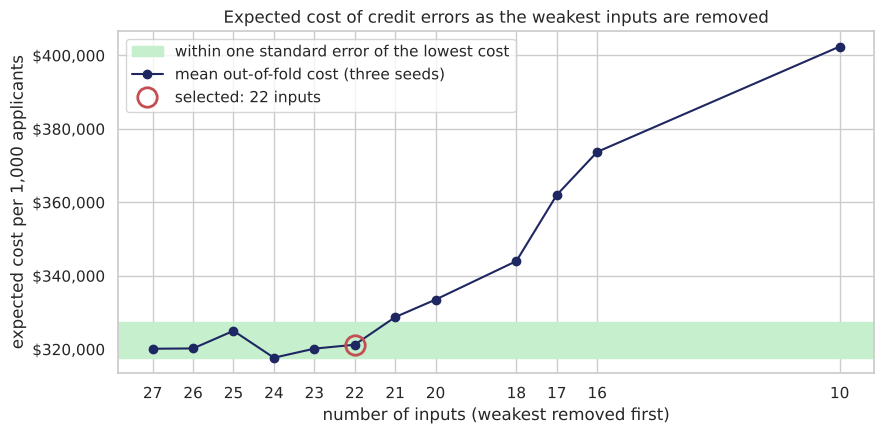

In [74]:
# Cost against the number of inputs (the counterpart of a scree plot), with the one-standard-error band of the rule
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axhspan(lowest_red, lowest_red + one_se_red, color="#c6efce", label="within one standard error of the lowest cost")
ax.plot(reduction.index, reduction[COST_COL], marker="o", color="#1E2761", label="mean out-of-fold cost (three seeds)")
ax.plot(selected_size, reduction.loc[selected_size, COST_COL], marker="o", markersize=14, markerfacecolor="none",
        markeredgecolor="#C44E52", markeredgewidth=2, linestyle="none", label=f"selected: {selected_size} inputs")
ax.invert_xaxis()
ax.set_xticks(reduction.index)
ax.yaxis.set_major_formatter(lambda x, _: f"${x:,.0f}")
ax.set_xlabel("number of inputs (weakest removed first)"); ax.set_ylabel("expected cost per 1,000 applicants")
ax.set_title("Expected cost of credit errors as the weakest inputs are removed")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Observations - input-set reduction:**
- The curve is flat from 27 down to 22 inputs. The first five inputs removed are missing-value flags with almost no weight: `CLNO_missing`, `NINQ_missing`, `DELINQ_missing`, `CLAGE_missing` and `MORTDUE_missing` (together about 2% of the split power). Without them the cost stays between \$317,700 and \$325,000 per 1,000 applicants, against \$320,150 for all 27 inputs.
- With fewer than 22 inputs the cost rises steadily: about \$328,800 for 21 inputs, \$333,500 for 20, \$373,700 for 16 and \$402,400 for 10. The remaining flags, loan purpose and occupation each carry some signal at the cost-optimal threshold.
- By the rule we keep **22 inputs**: the 10 financial attributes, six missing flags and the six one-hot indicators. The kept flags are those of `VALUE`, `REASON`, `JOB`, `YOJ`, `DEROG` and `DEBTINC`. Stage 3 tests this set against all 27 inputs on the same splits.
- One seed alone would mislead here. With seed 1 only, the 25-input set costs about \$13,000 more than the 24-input set. The mean of three seeds removes most of this noise.
- We ranked the inputs on all training rows before the repeated cross-validation, which can slightly favour the reduced sets. The removed flags carry almost no weight, so the effect is small.

In [75]:
# Stage 3: the chosen configuration on the selected input set, on all 27 inputs and without any occupation information
# (the fair-lending fallback), against the recall-tuned grid winner on all 27 inputs and on the 12-input set
no_occupation = [c for c in selected_inputs if not c.startswith("JOB_")]   # fair-lending fallback: the selected set without occupation
forest_name = f"RF class weights {best_weights}, leaf {best_leaf}"
candidates = {
    f"{forest_name}, {len(selected_inputs)} inputs (selected set)": (chosen_forest(), selected_inputs),
    f"{forest_name}, 27 inputs": (chosen_forest(), list(X_train.columns)),
    f"{forest_name}, {len(no_occupation)} inputs (selected set without occupation)": (chosen_forest(), no_occupation),
    "RF recall-tuned grid winner, 27 inputs": (RandomForestClassifier(**rf_search.best_params_, random_state=RANDOM_STATE, n_jobs=-1), list(X_train.columns)),
    "RF recall-tuned grid winner, 12 inputs": (RandomForestClassifier(**rf_search.best_params_, random_state=RANDOM_STATE, n_jobs=-1), keep),
}
# The other techniques at their own cost-minimising thresholds, so that the comparison on the chosen yardstick is complete
# (the logistic regression is evaluated on its own capped and scaled data version)
other_techniques = {
    "Bagging (200 trees), own threshold": (clone(bag), list(X_train.columns), X_train),
    "Logistic Regression (balanced, C tuned), own threshold": (clone(lr_bal), list(X_train_lr_s.columns), X_train_lr_s),
    "Decision Tree (recall-tuned), own threshold": (clone(dt_tuned), list(X_train.columns), X_train),
}
oof = {}
for name, (model, cols) in candidates.items():
    reuse = (tuple(cols), RANDOM_STATE)       # the chosen forest with seed 1 on a set that stage 2 already scored on the same splits
    oof[name] = stage2_runs[reuse] if name.startswith(forest_name) and reuse in stage2_runs else oof_evaluate(model, cols)
for name, (model, cols, frame) in other_techniques.items():
    oof[name] = oof_evaluate(model, cols, X=frame)
selection = pd.DataFrame({name: summary_row(res) for name, res in oof.items()}).T
selection.index.name = "Candidate"
selection["Inputs"] = [len(cols) for _, cols in candidates.values()] + [len(c[1]) for c in other_techniques.values()]

lowest = selection[COST_COL].min()
one_se = selection.loc[selection[COST_COL].idxmin(), "Fold-to-fold SD of cost ($)"] / np.sqrt(5 * len(CV_REPEATS))
within = selection[selection[COST_COL] <= lowest + one_se]
winner = within.sort_values(["Inputs", COST_COL]).index[0]      # simplest (fewest inputs) among those within one standard error
FINAL_THRESHOLD = float(selection.loc[winner, "Best threshold"])
assert winner in candidates, "the cells that follow score the winner on the untreated tree data; a linear winner would need its own data version"
final_model, final_cols = candidates[winner]
print(f"Candidates within one standard error (${one_se:,.0f}) of the lowest cost: {list(within.index)}")
print(f"Selected model : {winner}")
print(f"Selected threshold (from out-of-fold cost): {FINAL_THRESHOLD:.2f}")
selection.style.format(SELECTION_FORMAT).highlight_min(subset=[COST_COL], color="#c6efce")

Candidates within one standard error ($10,502) of the lowest cost: ['RF class weights none, leaf 1, 22 inputs (selected set)', 'RF class weights none, leaf 1, 27 inputs']
Selected model : RF class weights none, leaf 1, 22 inputs (selected set)
Selected threshold (from out-of-fold cost): 0.15


,Mean OOF ROC-AUC,Best threshold,OOF recall at best,OOF precision at best,"Mean OOF expected cost per 1,000 ($)",Fold-to-fold SD of cost ($),Inputs
Candidate,,,,,,,
"RF class weights none, leaf 1, 22 inputs (selected set)",0.960,0.15,0.937,0.639,"324,145","42,440",22
"RF class weights none, leaf 1, 27 inputs",0.961,0.15,0.937,0.647,"317,354","40,675",27
"RF class weights none, leaf 1, 16 inputs (selected set without occupation)",0.951,0.15,0.917,0.629,"364,813","32,700",16
"RF recall-tuned grid winner, 27 inputs",0.927,0.35,0.897,0.540,"489,613","52,035",27
"RF recall-tuned grid winner, 12 inputs",0.921,0.35,0.883,0.537,"512,544","47,688",12
"Bagging (200 trees), own threshold",0.944,0.15,0.901,0.629,"389,821","53,643",27
"Logistic Regression (balanced, C tuned), own threshold",0.907,0.50,0.815,0.599,"550,176","58,089",27
"Decision Tree (recall-tuned), own threshold",0.880,0.55,0.800,0.563,"607,223","73,679",27


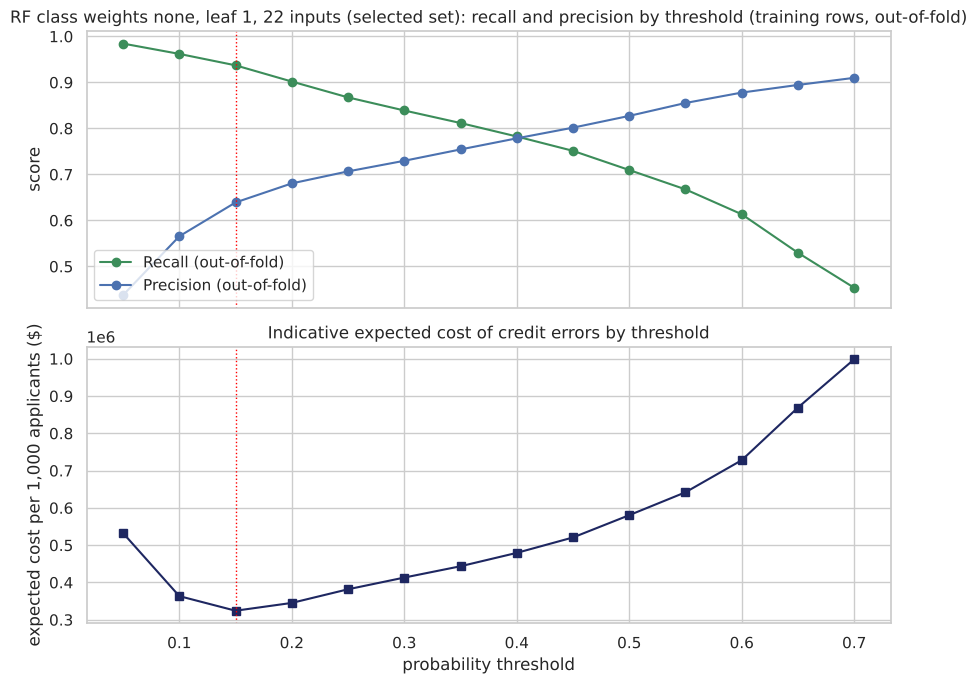

,threshold,recall,precision,accuracy,missed_defaulters_per_1000,good_customers_declined_per_1000,expected_cost_per_1000_$
0,0.050000,0.984,0.438,0.745,3.1,252.2,"532,359"
1,0.100000,0.962,0.566,0.845,7.6,147.5,"363,295"
2,0.150000,0.937,0.639,0.882,12.5,105.6,"324,145"
3,0.200000,0.902,0.680,0.896,19.6,84.5,"345,078"
4,0.250000,0.867,0.707,0.902,26.4,71.8,"381,671"
5,0.300000,0.839,0.730,0.906,32.1,62.0,"413,071"
6,0.350000,0.812,0.754,0.910,37.6,52.7,"443,432"
7,0.400000,0.782,0.778,0.912,43.4,44.4,"479,306"
8,0.450000,0.751,0.802,0.913,49.6,37.1,"520,694"
9,0.500000,0.710,0.827,0.913,57.9,29.6,"580,457"


In [76]:
# Out-of-fold cost curve of the winner (mean over the three repeated 5-fold splits)
# Two panels that share the threshold axis, one y-axis each (no dual-axis chart)
tbl = oof[winner]["table"]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax1.plot(tbl["threshold"], tbl["recall"], marker="o", color="#3C8D5A", label="Recall (out-of-fold)")
ax1.plot(tbl["threshold"], tbl["precision"], marker="o", color="#4C72B0", label="Precision (out-of-fold)")
ax1.set_ylabel("score"); ax1.legend(loc="lower left")
ax1.set_title(f"{winner}: recall and precision by threshold (training rows, out-of-fold)")
ax2.plot(tbl["threshold"], tbl["expected_cost_per_1000_$"], marker="s", color="#1E2761")
ax2.set_ylabel("expected cost per 1,000 applicants ($)"); ax2.set_xlabel("probability threshold")
ax2.set_title("Indicative expected cost of credit errors by threshold")
for ax in (ax1, ax2):
    ax.axvline(FINAL_THRESHOLD, color="red", linestyle=":", linewidth=1)
plt.tight_layout(); plt.show()

tbl.style.format({"recall": "{:.3f}", "precision": "{:.3f}", "accuracy": "{:.3f}", "missed_defaulters_per_1000": "{:.1f}",
                  "good_customers_declined_per_1000": "{:.1f}", "expected_cost_per_1000_$": "{:,.0f}"}).highlight_min(subset=["expected_cost_per_1000_$"], color="#c6efce")

In [77]:
# How sensitive is the chosen threshold to the cost assumptions? Re-run the threshold choice for other cost ratios.
rows = []
for ratio in [2, 3, 4.5, 6, 7, 8, 9]:
    costs = []
    for t in THRESHOLDS:
        c = 0
        for proba_oof in oof[winner]["probas"]:
            tn, fp, fn, tp = confusion_matrix(y_train, (proba_oof > t).astype(int)).ravel()
            c += fn * ratio + fp
        costs.append(c)
    rows.append({"cost of a missed defaulter / cost of a wrongly declined customer": f"{ratio}:1",
                 "cost-minimising threshold": THRESHOLDS[int(np.argmin(costs))],
                 "break-even threshold for a perfectly calibrated score": round(1 / (1 + ratio), 2)})
pd.DataFrame(rows)

,cost of a missed defaulter / cost of a wrongly declined customer,cost-minimising threshold,break-even threshold for a perfectly calibrated score
0,2:1,0.200,0.330
1,3:1,0.200,0.250
2,4.5:1,0.150,0.180
3,6:1,0.150,0.140
4,7:1,0.150,0.120
5,8:1,0.150,0.110
6,9:1,0.100,0.100


In [78]:
# Five robustness checks on the selection, all on training rows only.

# (a) A finer threshold grid for the winner: does the 0.05 step hide a better cut-off?
fine = np.round(np.arange(0.08, 0.26, 0.01), 2)
fine_cost = np.mean([cost_table(y_train, p, thresholds=fine)["expected_cost_per_1000_$"].values for p in oof[winner]["probas"]], axis=0)
print(f"(a) Finer grid, 0.01 steps: cost-minimising threshold {fine[int(np.argmin(fine_cost))]:.2f}; mean OOF cost per 1,000 ($) by threshold:")
print(pd.Series(fine_cost.round(0).astype(int), index=fine).to_frame("cost").T.to_string())

# (b) Calibration: do the out-of-fold scores behave like default rates? Reliability table and Brier score for the winner
#     and for the class-weighted forest it replaced.
score_bins = [0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.70, 1.0]
def reliability(proba, label):
    '''Return the reliability table: mean score and observed default rate per score band.'''
    t = (pd.DataFrame({"score band": pd.cut(proba, score_bins, include_lowest=True), "p": proba, "y": y_train.values})
           .groupby("score band", observed=True).agg(applicants=("y", "size"), mean_score=("p", "mean"), observed_default_rate=("y", "mean")))
    t.columns = pd.MultiIndex.from_product([[label], t.columns])
    return t
p_final, p_weighted = oof[winner]["probas"][0], stage1[("0.2/0.8", 1)]["probas"][0]
print(f"(b) Brier score (mean squared error of the score as a probability, lower is better; the base rate alone scores "
      f"{brier_score_loss(y_train, np.full(len(y_train), y_train.mean())):.3f}): "
      f"final forest {brier_score_loss(y_train, p_final):.3f}, class weights 0.2/0.8 {brier_score_loss(y_train, p_weighted):.3f}")
display(pd.concat([reliability(p_final, "Final forest (unweighted)"), reliability(p_weighted, "Class weights 0.2/0.8")], axis=1).round(3))

# (c) The approve / refer / decline bands proposed later (0.10 and 0.25), on the out-of-fold scores of the training rows
oof_bands = pd.cut(p_final, [-0.01, 0.10, 0.25, 1.0], labels=["approve (score <= 0.10)", "refer (0.10 - 0.25)", "decline (score > 0.25)"])
band_oof = (pd.DataFrame({"band": oof_bands, "defaulted": y_train.values}).groupby("band", observed=True)
              .agg(applicants=("defaulted", "size"), defaulters=("defaulted", "sum"), observed_default_rate=("defaulted", "mean")))
band_oof["share_of_applicants"] = band_oof["applicants"] / len(y_train)
band_oof["share_of_defaulters"] = band_oof["defaulters"] / y_train.sum()
print("(c) Approve / refer / decline bands on the out-of-fold scores (training rows):")
display(band_oof.style.format({"observed_default_rate": "{:.1%}", "share_of_applicants": "{:.1%}", "share_of_defaulters": "{:.1%}"}))

# (d) Paired checks of the 'within noise' statements, over the same 15 validation folds: the 0.2/0.8 forest against the
#     unweighted forest (both on all 27 inputs), and the winner against the unweighted forest on all 27 inputs
def fold_costs_at(res, t):
    '''Return the expected cost per 1,000 applicants in each validation fold at threshold t.'''
    out = []
    for seed, p in zip(CV_REPEATS, res["probas"]):
        for _, val in StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(X_train, y_train):
            out.append(cost_table(y_train.iloc[val], p[val], thresholds=np.array([t]))["expected_cost_per_1000_$"].iloc[0])
    return np.array(out)
weighted, all_inputs = stage1[("0.2/0.8", 1)], stage1[(best_weights, best_leaf)]
for label, a, b in [("class weights 0.2/0.8 minus no class weights, both on 27 inputs", weighted, all_inputs),
                    (f"the selected {len(final_cols)} inputs (the winner) minus all 27 inputs", oof[winner], all_inputs)]:
    diff = fold_costs_at(a, a["best"]["threshold"]) - fold_costs_at(b, b["best"]["threshold"])
    print(f"(d) Paired fold-by-fold difference, {label}, each at its own best threshold "
          f"({a['best']['threshold']:.2f} and {b['best']['threshold']:.2f}): mean ${diff.mean():,.0f} per 1,000 applicants, "
          f"paired standard error ${diff.std(ddof=1) / np.sqrt(len(diff)):,.0f} ({len(diff)} folds)")

# (e) Does the choice depend on this particular 70/30 split? Repeat stage 1 (fully grown trees) on two other stratified splits,
#     rebuilding the missing flags and the imputation from each split's own training rows.
def training_rows_for_split(seed):
    '''Rebuild the tree inputs of the training rows for another stratified 70/30 split.'''
    frame = hm.copy()
    for c in ["REASON", "JOB", "BAD"]:
        frame[c] = frame[c].astype("category")
    tr, _ = train_test_split(frame.index, test_size=0.30, random_state=seed, stratify=frame["BAD"])
    add_missing_flags(frame)
    impute(frame, tr)
    Xs, ys = prepare_xy(frame)
    return Xs.loc[tr], ys.loc[tr]

rows = []
for seed in [2, 3]:
    Xs, ys = training_rows_for_split(seed)
    cv_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for w_name, w in weight_options.items():
        p = cross_val_predict(RandomForestClassifier(n_estimators=200, class_weight=w, random_state=RANDOM_STATE, n_jobs=-1),
                              Xs, ys, cv=cv_s, method="predict_proba")[:, 1]
        t = cost_table(ys, p)
        best = t.loc[t["expected_cost_per_1000_$"].idxmin()]
        rows.append({"class weights": w_name, "split seed": seed, "best threshold": best["threshold"],
                     "OOF cost per 1,000 ($)": best["expected_cost_per_1000_$"]})
split_check = (pd.DataFrame(rows).pivot(index="class weights", columns="split seed", values=["best threshold", "OOF cost per 1,000 ($)"])
                 .loc[list(weight_options)])
print("(e) Stage 1 repeated on two other 70/30 splits (fully grown trees, single 5-fold OOF). Cheapest configuration per split:",
      {seed: split_check[("OOF cost per 1,000 ($)", seed)].idxmin() for seed in [2, 3]})
split_check.style.format({c: ("{:.2f}" if c[0] == "best threshold" else "{:,.0f}") for c in split_check.columns})

(a) Finer grid, 0.01 steps: cost-minimising threshold 0.15; mean OOF cost per 1,000 ($) by threshold:
       0.080   0.090   0.100   0.110   0.120   0.130   0.140   0.150   0.160   0.170   0.180   0.190   0.200   0.210   0.220   0.230   0.240   0.250
cost  402125  377996  363295  348754  334452  329338  326782  324145  330058  333253  332614  339086  345078  354027  364573  368408  377437  381671
(b) Brier score (mean squared error of the score as a probability, lower is better; the base rate alone scores 0.160): final forest 0.063, class weights 0.2/0.8 0.065


Final forest (unweighted)                                   \
                              applicants mean_score observed_default_rate   
score band                                                                  
(-0.001, 0.05]                      2299      0.018                 0.005   
(0.05, 0.1]                          457      0.073                 0.035   
(0.1, 0.15]                          198      0.125                 0.101   
(0.15, 0.2]                          116      0.174                 0.284   
(0.2, 0.3]                           146      0.249                 0.363   
(0.3, 0.4]                           125      0.353                 0.368   
(0.4, 0.5]                           113      0.456                 0.513   
(0.5, 0.7]                           301      0.608                 0.701   
(0.7, 1.0]                           417      0.815                 0.918   

               Class weights 0.2/0.8                                   
                          applicants mean_score observed_default_rate  
score band                                                             
(-0.001, 0.05]                  1665      0.023                 0.002  
(0.05, 0.1]                      654      0.074                 0.012  
(0.1, 0.15]                      324      0.124                 0.034  
(0.15, 0.2]                      210      0.175                 0.067  
(0.2, 0.3]                       211      0.246                 0.209  
(0.3, 0.4]                       122      0.349                 0.377  
(0.4, 0.5]                       107      0.455                 0.355  
(0.5, 0.7]                       266      0.603                 0.560  
(0.7, 1.0]                       613      0.841                 0.845

(c) Approve / refer / decline bands on the out-of-fold scores (training rows):


,applicants,defaulters,observed_default_rate,share_of_applicants,share_of_defaulters
band,,,,,
approve (score <= 0.10),2756,28,1.0%,66.1%,3.4%
refer (0.10 - 0.25),395,78,19.7%,9.5%,9.4%
decline (score > 0.25),1021,726,71.1%,24.5%,87.3%


(d) Paired fold-by-fold difference, class weights 0.2/0.8 minus no class weights, both on 27 inputs, each at its own best threshold (0.25 and 0.15): mean $3,836 per 1,000 applicants, paired standard error $5,122 (15 folds)


(d) Paired fold-by-fold difference, the selected 22 inputs (the winner) minus all 27 inputs, each at its own best threshold (0.15 and 0.15): mean $6,792 per 1,000 applicants, paired standard error $6,276 (15 folds)


(e) Stage 1 repeated on two other 70/30 splits (fully grown trees, single 5-fold OOF). Cheapest configuration per split: {2: 'none', 3: 'none'}


**Observations - model and threshold selection:**
- **Stage 3 keeps the 22-input forest.** On the single-seed out-of-fold predictions, the unweighted forest on all 27 inputs has the lowest expected cost, \$317,354 per 1,000 applicants. The same forest on the 22 selected inputs costs \$324,145. That is within one standard error (\$10,502) of the lowest cost. The rule therefore picks the simpler 22-input forest. The second paired check in the robustness cell agrees. The 22-input forest costs \$6,792 more on average, with a paired standard error of \$6,276 over the 15 folds. This difference is about one paired standard error, so it is within noise. On the Stage 2 curve, with three forest seeds, the two sets differ by only about \$1,100 (\$321,242 against \$320,150).
- Removing all occupation information from the selected set (the five occupation indicators and the occupation-missing flag) leaves 16 inputs. That forest costs about 13% more (\$364,813), outside one standard error. Occupation carries real signal, so removing it is a policy choice with a measurable price, not a free one.
- The recall-tuned grid winner is far worse once precision enters the cost: \$490,000 on all 27 inputs and \$513,000 on the 12-input set. This shows that recall-only tuning over-shoots. We scored the bagged trees, the balanced logistic regression and the recall-tuned decision tree the same way, at their own best thresholds. All three cost more than every fully grown forest in Stage 1 and Stage 3 (\$390,000, \$550,000 and \$607,000, see the table). The technique choice therefore holds on the chosen yardstick as well as on ranking quality.
- The cost-minimising threshold is **0.15**: flag every applicant whose score exceeds 0.15 (an estimated default risk of roughly one in five, see the calibration check). It stays at 0.15 for any cost ratio from 4.5:1 to 8:1. At 2:1 and 3:1 it would move to 0.20. It falls to 0.10 once a missed defaulter costs about nine times a wrongly declined applicant. The stated 4.5:1 ratio sits at the lower edge of this range. The bank must therefore re-derive the threshold from its own figures. For a perfectly calibrated score the textbook break-even at the stated costs would be \$2,000 / (\$9,000 + \$2,000) = 0.18. The forest's optimum sits a little below it because its scores understate risk in the decision range, as the calibration check shows.
- **Threshold tuning lowers the out-of-fold expected cost.** On the same out-of-fold predictions at the default 0.5 threshold, the 22-input forest has recall 0.710 and precision 0.827. Its expected cost is \$580,457 per 1,000 applicants. At 0.15 it has recall 0.937, precision 0.639 and an expected cost of \$324,145. That is 44% lower, and we measured it on the training rows only.
- **Robustness of the choice.** A finer 0.01 grid gives the same threshold (0.15). The second-cheapest threshold, 0.14, costs about \$2,600 more. The robustness cell prints two paired fold-by-fold checks. The first compares the 0.2/0.8 forest with the unweighted forest, both on 27 inputs. The mean difference is about \$4,000 per 1,000 applicants, with a paired standard error of about \$5,000, so the two are within noise. The second compares the 22-input winner with all 27 inputs (see the first point). On two other 70/30 splits the unweighted forest is again the cheapest configuration, and the weighted forests are again within noise of it. The choice is therefore not an artefact of this split.
- **Calibration.** The final forest's out-of-fold scores rank applicants well (Brier score 0.063 against 0.160 for the base rate). The observed default rate rises in every score band. In the decision range the scores understate the default rate: applicants scored 0.15-0.20 defaulted about 28% of the time, and those scored 0.20-0.30 about 36%. The class-weighted forest's scores are much further from the observed rates (applicants it scored 0.15-0.20 defaulted only 7% of the time). That is the concrete reason an unweighted score is easier to explain and govern. Therefore, read a score of 0.15 as "estimated default risk of roughly one in five", not exactly 15%. We list probability calibration under further analysis.
- **What the test set can and cannot show.** We fixed the imputation statistics, the 12-input set and the Stage 2 ranking of the inputs on all training rows before the repeated cross-validation. The ranking can slightly favour the reduced input sets, but the removed flags carry almost no weight, so the effect is small. We also chose the configuration, the input set and the threshold on the same out-of-fold predictions. The single test evaluation below is therefore a consistency check of the chosen model's performance. It is not evidence for the choice between configurations or input sets. Its cost comes with a standard error of about \$28,000 per 1,000 applicants. That is wider than the differences between the fully grown configurations and between the 22-input and 27-input forests. The paired fold-by-fold checks in the robustness cell are the right evidence for those differences.

In [79]:
# The final solution written out end to end, so that every step and every input to the scoring model is explicit
flag_cols = [c for c in final_cols if c.endswith("_missing")]
dummy_cols = [c for c in final_cols if c.startswith(("REASON_", "JOB_")) and c not in flag_cols]
raw_cols = [c for c in final_cols if c not in flag_cols + dummy_cols]
assert len(final_cols) == len(raw_cols) + len(flag_cols) + len(dummy_cols)
assert final_cols == [c for c in X_train.columns if c in final_cols], "the final inputs keep the order of the prepared columns"
unused_flags = [c for c in X_train.columns if c.endswith("_missing") and c not in final_cols]

print(f"FINAL PIPELINE  (every statistic below was learned on the {len(train_idx):,} training rows only)")
print(f"1. Raw inputs kept as numbers ({len(raw_cols)}):", raw_cols)
print(f"2. Missing-value flags, 1 if the field was blank, kept as inputs ({len(flag_cols)}):", flag_cols)
print(f"   Flags removed by the input-set reduction ({len(unused_flags)}):", unused_flags)
print("3. Imputation of blanks - training-row medians:", {k: round(v, 2) for k, v in hm.loc[train_idx, num_cols].median().items()})
print("                          training-row modes  :", {c: hm.loc[train_idx, c].mode()[0] for c in ["REASON", "JOB"]})
print(f"4. One-hot encoding of REASON and JOB, first level dropped ({len(dummy_cols)}):", dummy_cols)
print("5. No outlier capping and no scaling: tree ensembles are unaffected by monotone transformations of an input")
print("6. Model:", type(final_model).__name__, {k: v for k, v in final_model.get_params().items()
      if k in ["n_estimators", "class_weight", "min_samples_leaf", "max_features", "max_depth", "random_state"]})
print(f"7. Model inputs, in order ({len(final_cols)}):", final_cols)
print(f"8. Decision rule: flag the applicant when the predicted default probability exceeds {FINAL_THRESHOLD:.2f}")
print(f"9. Input-set reduction (stage 2). Rule: keep the smallest input set whose mean out-of-fold cost over {len(FOREST_SEEDS)} forest "
      f"seeds is within one standard error (${one_se_red:,.0f}) of the lowest cost on the curve (${lowest_red:,.0f}).")
smaller = [n for n in reduction.index if n < selected_size]
print(f"   Selected: {selected_size} inputs at ${reduction.loc[selected_size, COST_COL]:,.0f} per 1,000 applicants; all 27 inputs: "
      f"${reduction.loc[27, COST_COL]:,.0f}" + (f"; next smaller set ({smaller[0]} inputs): ${reduction.loc[smaller[0], COST_COL]:,.0f}, "
      "outside one standard error" if smaller else ""))
print(f"   Removed ({len(removed_inputs)}):", removed_inputs)
print(f"   Stage 3 confirmed the selected set: {winner}")

FINAL PIPELINE  (every statistic below was learned on the 4,172 training rows only)
1. Raw inputs kept as numbers (10): ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
2. Missing-value flags, 1 if the field was blank, kept as inputs (6): ['VALUE_missing', 'REASON_missing', 'JOB_missing', 'YOJ_missing', 'DEROG_missing', 'DEBTINC_missing']
   Flags removed by the input-set reduction (5): ['MORTDUE_missing', 'DELINQ_missing', 'CLAGE_missing', 'NINQ_missing', 'CLNO_missing']
3. Imputation of blanks - training-row medians: {'LOAN': 16200.0, 'MORTDUE': 66293.0, 'VALUE': 89965.0, 'YOJ': 7.0, 'DEROG': 0.0, 'DELINQ': 0.0, 'CLAGE': 173.87, 'NINQ': 1.0, 'CLNO': 20.0, 'DEBTINC': 34.84}
                          training-row modes  : {'REASON': 'DebtCon', 'JOB': 'Other'}
4. One-hot encoding of REASON and JOB, first level dropped (6): ['REASON_HomeImp', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']
5. No outlier capping and no scaling: 

Final model: RF class weights none, leaf 1, 22 inputs (selected set) at threshold 0.15 - TEST SET
              precision    recall  f1-score   support

           0      0.980     0.888     0.932      1431
           1      0.674     0.927     0.781       357

    accuracy                          0.896      1788
   macro avg      0.827     0.908     0.856      1788
weighted avg      0.919     0.896     0.902      1788



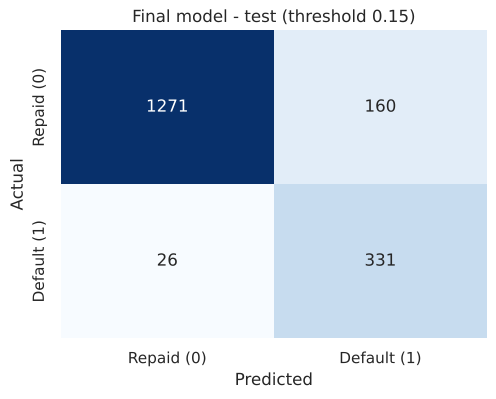

Test ROC-AUC: 0.961
Test expected cost per 1,000 applicants: $309,843 (standard error about $28,385); out-of-fold estimate $324,145


,threshold,recall,precision,accuracy,missed_defaulters_per_1000,good_customers_declined_per_1000,expected_cost_per_1000_$
0,0.150000,0.927,0.674,0.896,14.5,89.5,"309,843"
1,0.500000,0.678,0.829,0.908,64.3,28.0,"634,787"


In [80]:
# Fit the selected model on all training rows and score the test set ONCE, at the selected threshold and at 0.5 for reference
final_model.fit(X_train[final_cols], y_train)
proba_test = final_model.predict_proba(X_test[final_cols])[:, 1]
final_pred = (proba_test > FINAL_THRESHOLD).astype(int)

print(f"Final model: {winner} at threshold {FINAL_THRESHOLD:.2f} - TEST SET")
metrics_score(y_test, final_pred, title=f"Final model - test (threshold {FINAL_THRESHOLD:.2f})")
print(f"Test ROC-AUC: {roc_auc_score(y_test, proba_test):.3f}")

cost_per_applicant = np.where((y_test == 1) & (final_pred == 0), COST_FN, np.where((y_test == 0) & (final_pred == 1), COST_FP, 0.0))
print(f"Test expected cost per 1,000 applicants: ${1000 * cost_per_applicant.mean():,.0f} "
      f"(standard error about ${1000 * cost_per_applicant.std(ddof=1) / np.sqrt(len(y_test)):,.0f}); "
      f"out-of-fold estimate ${oof[winner]['best']['expected_cost_per_1000_$']:,.0f}")

test_tbl = cost_table(y_test, proba_test, thresholds=np.array([FINAL_THRESHOLD, 0.5]))
test_tbl.style.format({"recall": "{:.3f}", "precision": "{:.3f}", "accuracy": "{:.3f}", "missed_defaulters_per_1000": "{:.1f}",
                       "good_customers_declined_per_1000": "{:.1f}", "expected_cost_per_1000_$": "{:,.0f}"})

In [81]:
# What the proposed three-band policy would mean in practice (test set): approve below a score of 0.10,
# refer 0.10 - 0.25 to an underwriter, decline above 0.25
bands = pd.cut(proba_test, [-0.01, 0.10, 0.25, 1.0],
               labels=["approve (score <= 0.10)", "refer to underwriter (0.10 - 0.25)", "decline (score > 0.25)"])
band_tbl = (pd.DataFrame({"band": bands, "defaulted": y_test.values}).groupby("band", observed=True)
              .agg(applicants=("defaulted", "size"), defaulters=("defaulted", "sum"), observed_default_rate=("defaulted", "mean")))
band_tbl["share_of_applicants"] = band_tbl["applicants"] / len(y_test)
band_tbl["share_of_defaulters"] = band_tbl["defaulters"] / y_test.sum()
band_tbl["per_1000_applicants"] = 1000 * band_tbl["share_of_applicants"]
band_tbl.style.format({"observed_default_rate": "{:.1%}", "share_of_applicants": "{:.1%}", "share_of_defaulters": "{:.1%}", "per_1000_applicants": "{:.0f}"})

,applicants,defaulters,observed_default_rate,share_of_applicants,share_of_defaulters,per_1000_applicants
band,,,,,,
approve (score <= 0.10),1228,16,1.3%,68.7%,4.5%,687
refer to underwriter (0.10 - 0.25),132,28,21.2%,7.4%,7.8%,74
decline (score > 0.25),428,313,73.1%,23.9%,87.7%,239


In [82]:
# Where does the performance come from? The final model on the test applicants with a recorded debt-to-income ratio and on
# those without one (the group that mandatory income verification, the first process change recommended, will shrink)
rows = []
for label, mask in [("ratio recorded", X_test["DEBTINC_missing"] == 0), ("ratio missing", X_test["DEBTINC_missing"] == 1)]:
    yt, pt, pp = y_test[mask], final_pred[mask.values], proba_test[mask.values]
    tn, fp, fn, tp = confusion_matrix(yt, pt).ravel()
    rows.append({"group": label, "applicants": int(mask.sum()), "share_of_applicants": mask.mean(), "default_rate": yt.mean(),
                 "share_of_all_defaulters": yt.sum() / y_test.sum(), "flagged": pt.mean(), "recall": tp / (tp + fn),
                 "precision": tp / (tp + fp), "ROC-AUC": roc_auc_score(yt, pp)})
pd.DataFrame(rows).set_index("group").style.format({"share_of_applicants": "{:.1%}", "default_rate": "{:.1%}", "share_of_all_defaulters": "{:.1%}",
                                                     "flagged": "{:.1%}", "recall": "{:.3f}", "precision": "{:.3f}", "ROC-AUC": "{:.3f}"})

,applicants,share_of_applicants,default_rate,share_of_all_defaulters,flagged,recall,precision,ROC-AUC
group,,,,,,,,
ratio recorded,1415,79.1%,8.7%,34.5%,9.0%,0.813,0.781,0.965
ratio missing,373,20.9%,62.7%,65.5%,97.3%,0.987,0.636,0.814


**Observations - final model on unseen applicants:**
- At the chosen 0.15 threshold the 22-input forest catches about **93% of defaulters** on the test set with about **67% precision** and 90% accuracy. Per 1,000 applicants that is roughly 185 of 200 defaulters flagged in advance, about 15 missed and about 90 good applicants flagged.
- At the conventional 0.5 threshold the same forest would catch only about 68% of defaulters (with 83% precision). It would miss about 64 defaulters per 1,000 instead of 15, and it would decline about 28 good applicants instead of 90. Under the stated costs the lower threshold halves the expected cost of credit errors (about \$0.31 million vs \$0.63 million per 1,000 applicants).
- The test numbers are consistent with the out-of-fold estimates (recall 93% vs 94%, precision 67% vs 64%, cost \$310,000 ± \$28,000 vs \$324,000 per 1,000). The chosen model performs on unseen applicants as the training-based estimate said it would. As we noted above, one test evaluation cannot adjudicate between the closest candidates, such as the 22-input and 27-input forests. They differed by far less than that standard error. That choice rests on the out-of-fold comparison.
- **Where the performance comes from.** Two thirds of all defaulters sit in the fifth of applicants with no recorded debt-to-income ratio. The model flags virtually all of that group (97%), catching 99% of its defaulters at 64% precision. On the four fifths with a recorded ratio it is a genuinely selective scorer. It flags 9% of them and catches 81% of their defaulters at 78% precision (ROC-AUC 0.97).
- Mandatory income verification, the first process change we recommend, will shrink the missing-ratio group. Before go-live, the bank must test the model on the historical applicants with a recorded ratio, and refit it if necessary. The model's behaviour on those applicants is the better guide to what to expect. Re-training on newly verified outcomes needs 12 months or more of repayment data.
- **The three-band policy in numbers.** Under the bands the bank would approve about 69% of applicants (about 687 per 1,000) automatically, with an observed default rate of about 1%. It would refer about 7% (about 74 per 1,000) to an underwriter. About one in five of this group defaulted. It would decline about 24% (about 239 per 1,000). In this group 73% defaulted, and the group holds 88% of all defaulters.
- The shares are close to the out-of-fold rows (66.1% / 9.5% / 24.5%), so we did not tune the bands to the test set. The edges 0.10 and 0.25 are round numbers around the threshold. We set them beforehand, roughly where the out-of-fold cost is 10-20% above its minimum. The bank is to tune them to underwriting capacity in the shadow period.
- Overall the model flags about 27% of applicants. That is an approval rate of about 73% on a population the bank approves in full today. The 0.5 threshold would flag 16%. The referral band is small enough to work by hand, and it is where the model is least certain.
- All performance and cost figures in this notebook are for the single 0.15 threshold. The bands are the operating procedure around it. Whatever an underwriter approves inside the referral band trades some of the modelled benefit for a human check. Under the bands the share of defaulters caught lies between about 88% and 96%. The low end holds if the underwriter approves every referral. The high end holds if the underwriter declines every referral.

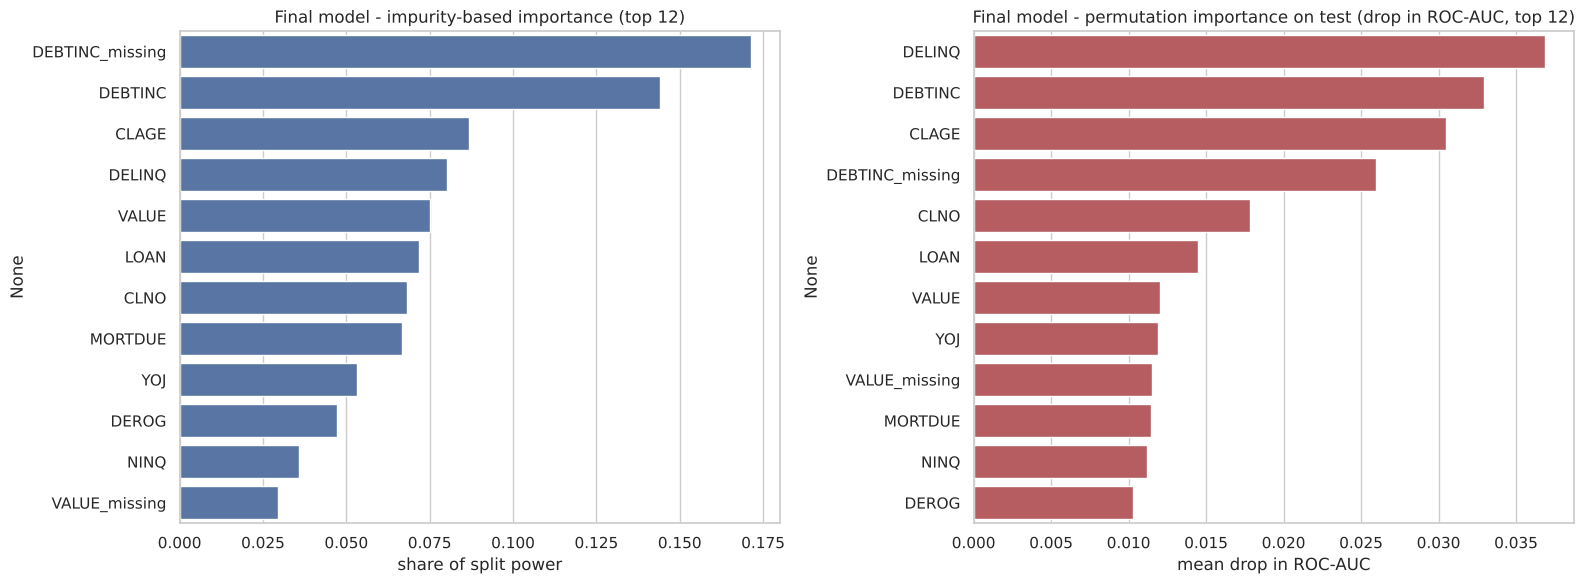

,impurity_importance,permutation_importance_auc_drop
DEBTINC_missing,0.172,0.026
DEBTINC,0.144,0.033
CLAGE,0.087,0.030
DELINQ,0.080,0.037
VALUE,0.075,0.012
LOAN,0.072,0.015
CLNO,0.068,0.018
MORTDUE,0.067,0.011
YOJ,0.053,0.012
DEROG,0.047,0.010


In [83]:
# What the final model relies on: impurity-based importance of the fitted forest, and permutation importance
# (drop in test ROC-AUC when a column is shuffled), which does not favour variables with many split points.
# The test set is used here for interpretation only; no choice is made from it.
mdi = pd.Series(final_model.feature_importances_, index=final_cols).sort_values(ascending=False)
perm = permutation_importance(final_model, X_test[final_cols], y_test, scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=final_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=mdi.values[:12], y=mdi.index[:12], color="#4C72B0", ax=axes[0])
axes[0].set_title("Final model - impurity-based importance (top 12)"); axes[0].set_xlabel("share of split power")
sns.barplot(x=perm_imp.values[:12], y=perm_imp.index[:12], color="#C44E52", ax=axes[1])
axes[1].set_title("Final model - permutation importance on test (drop in ROC-AUC, top 12)"); axes[1].set_xlabel("mean drop in ROC-AUC")
plt.tight_layout(); plt.show()

pd.DataFrame({"impurity_importance": mdi.round(3), "permutation_importance_auc_drop": perm_imp.round(4)}).sort_values("impurity_importance", ascending=False).head(12)

**Insights - what the final model relies on:**
- Both views agree on the core drivers. These are the **debt-to-income ratio and its missing flag, the number of delinquent credit lines and the age of the credit history**. Together they carry about half of the forest's split power (0.48). They also produce the four largest drops in ranking quality when the permutation test shuffles them.
- Impurity importance spreads the remaining weight over the property value, loan and mortgage amounts, the number of credit lines and job tenure. These are continuous variables with many split points. Permutation importance ranks `DELINQ` first, i.e. repayment behaviour, and gives the amounts less weight. Occupation, loan purpose and the kept missing flags other than `DEBTINC_missing` each matter little on their own. But on the Stage 2 curve the cost rises with each further removal below 22 inputs. Only the five weakest missing flags gave no measurable gain, so Stage 2 removed them.

#### An explanation layer that follows the forest: a surrogate decision tree

The ECOA requires a specific reason for each adverse decision. A forest of 200 trees cannot be read directly, so we fit a **surrogate decision tree to the forest's own decisions**. The target is the forest's flag / do-not-flag outcome at the 0.15 threshold, not the original labels.

A fully grown forest reproduces its training labels almost perfectly. As a result, its in-sample decisions would teach the surrogate the labels rather than the forest's behaviour on new applicants. We therefore fit the surrogate to the forest's **out-of-fold decisions** on the training rows (the repeated-CV scores above). We compare its agreement with the forest's actual decisions on the test applicants, its *fidelity*, with the trivial baseline of never flagging anyone. We summarise the agreement with Cohen's kappa.

In [84]:
# The surrogate is fitted to the forest's OUT-OF-FOLD decisions on the training rows: a fully grown forest reproduces its
# training labels almost perfectly, so its in-sample decisions would teach the surrogate the labels, not the forest's behaviour
# on applicants it has not seen.
forest_decision_oof = (oof[winner]["probas"][0] > FINAL_THRESHOLD).astype(int)
forest_decision_insample = (final_model.predict_proba(X_train[final_cols])[:, 1] > FINAL_THRESHOLD).astype(int)
forest_decision_test = final_pred
print(f"In-sample decisions agree with the training labels on {(forest_decision_insample == y_train.values).mean():.1%} of rows "
      f"(flag rate {forest_decision_insample.mean():.1%}); out-of-fold flag rate {forest_decision_oof.mean():.1%}; test flag rate {forest_decision_test.mean():.1%}.")
print(f"Baseline: a rule that never flags anyone agrees with the forest's test decisions {1 - forest_decision_test.mean():.1%} of the time.\n")

fidelity, kappa = {}, {}
for target_name, target in [("out-of-fold decisions", forest_decision_oof), ("in-sample decisions", forest_decision_insample)]:
    for depth in [3, 4, 5]:
        sur = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=RANDOM_STATE).fit(X_train[final_cols], target)
        pred = sur.predict(X_test[final_cols])
        fidelity[(target_name, depth)] = (pred == forest_decision_test).mean()
        kappa[(target_name, depth)] = cohen_kappa_score(forest_decision_test, pred)
print("Agreement with the forest's test decisions (fidelity) and Cohen's kappa, by surrogate target and depth:")
for k in fidelity:
    print(f"  {k[0]:22s} depth {k[1]}: {fidelity[k]:.1%} (kappa {kappa[k]:.2f})")

surrogate = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=RANDOM_STATE).fit(X_train[final_cols], forest_decision_oof)
print(f"\nSurrogate tree (depth 4, fitted to the out-of-fold decisions) reproduces {fidelity[('out-of-fold decisions', 4)]:.1%} "
      f"of the forest's decisions on unseen applicants.\n")
print(export_text(surrogate, feature_names=final_cols, max_depth=4, show_weights=False))

In-sample decisions agree with the training labels on 96.1% of rows (flag rate 23.9%); out-of-fold flag rate 29.2%; test flag rate 27.5%.
Baseline: a rule that never flags anyone agrees with the forest's test decisions 72.5% of the time.

Agreement with the forest's test decisions (fidelity) and Cohen's kappa, by surrogate target and depth:
  out-of-fold decisions  depth 3: 93.4% (kappa 0.83)
  out-of-fold decisions  depth 4: 93.2% (kappa 0.82)
  out-of-fold decisions  depth 5: 93.2% (kappa 0.82)
  in-sample decisions    depth 3: 89.1% (kappa 0.69)
  in-sample decisions    depth 4: 89.9% (kappa 0.72)
  in-sample decisions    depth 5: 90.8% (kappa 0.75)

Surrogate tree (depth 4, fitted to the out-of-fold decisions) reproduces 93.2% of the forest's decisions on unseen applicants.

|--- DEBTINC_missing <= 0.50
|   |--- DEBTINC <= 43.72
|   |   |--- DELINQ <= 0.50
|   |   |   |--- VALUE <= 48580.50
|   |   |   |   |--- class: 0
|   |   |   |--- VALUE >  48580.50
|   |   |   |   |--- class:

**Insights - the surrogate tree:**
- Fitted to the forest's out-of-fold decisions, a four-level tree reproduces about **93% of the forest's decisions** on unseen applicants (kappa 0.82). Depths 3 to 5 agree within a quarter of a point. A rule that never flags anyone reaches 73%. Fitted to the forest's in-sample decisions instead, the tree would reach only about 90%, because those decisions are almost identical to the training labels. The out-of-fold target is what makes the surrogate describe the scoring engine rather than the training data.
- The rules are short, and they are the same drivers the EDA and the stand-alone tree found: *Is the debt-to-income ratio missing? Then flag, whatever the credit history. If it is recorded, is it above about 44%? Then flag. At or below 44%, flag only when two conditions both hold. The applicant has at least one delinquent credit line. The oldest credit line is about 93 months (7.8 years) old or less. Otherwise clear.* (Inside the "ratio missing" branch the tree splits on credit-history length, delinquent lines, a missing occupation and job tenure. But it flags every applicant on that branch. For applicants at or below 44% with no delinquent line, a property-value split appears, but both of its groups clear.) The bank can therefore tell a flagged applicant which of these conditions applied to them.
- The surrogate does not reproduce roughly 7% of decisions. Also, each adverse-action notice must give the reasons for that applicant. So the bank must build per-applicant risk drivers from the forest itself (for example SHAP values) in the first two months, before the shadow run. These drivers give the reason for each decline, including the automatic declines above 0.25. The surrogate rules give the plain-language summary of how the model decides.

#### Do the EDA drivers remain significant after modelling?

The table compares each EDA driver with its weight in the three model types. EDA figures compare defaulters with repayers. Odds ratios come from the balanced logistic regression. 'Top splits' means the first three levels of the tuned tree and the surrogate tree. Importances come from the final forest.

| Variable | EDA evidence | Logistic regression odds ratio | Top splits | Final forest: impurity share / permutation drop | Remains significant? |
|---|---|---|---|---|---|
| DEBTINC_missing | 62.0% default when missing, 8.6% when present | 13.1 | First split of both trees | 17.2% / 0.026 | Yes |
| DEBTINC | Median 38.1% vs 34.5% (p < 0.001). 87% to 100% default above 45% | 1.82 per SD | Next split, at about 44%, in both trees | 14.4% / 0.033 | Yes |
| DELINQ | 14% default with 0 lines, 45% with 2 | 2.42 per SD | Splits right after the ratio in both trees | 8.0% / 0.037 (largest drop) | Yes |
| CLAGE | Median 133 vs 180 months (p < 0.001) | 0.62 per SD (protective) | Splits in both trees. In the surrogate tree it splits right after DELINQ | 8.7% / 0.030 | Yes |
| DEROG | 17% default with 0 reports, 51% with 2 | 1.49 per SD | Splits after DELINQ in the tuned tree. No split in the surrogate tree | 4.7% / 0.010 | Yes, but weaker in the forest |
| VALUE_missing | 93.8% default when missing (112 applicants) | 44.6 (largest) | No | 2.9% / 0.011 | Strong in the linear model, weak in the forest. Only 1.9% of applicants have it |
| NINQ | 16% default with 0 inquiries, about 46% with 5 or more | 1.19 per SD | No | 3.6% / 0.011 | Weakly |
| LOAN | Median \$14,900 vs \$16,900 (p < 0.001). 57% default under \$5,000 | 0.995 (no linear effect) | No | 7.2% / 0.015 | Moderately, in the forest only (a non-linear effect) |
| VALUE, MORTDUE | Significant (p < 0.001) but small gaps. Correlation 0.88 | 1.11 and 0.88 per SD (opposite signs) | No | 7.5% and 6.7% / 0.012 and 0.011 | Weakly. They carry the same information |
| JOB | Chi-square p < 0.001. Sales 35%, Office 13% | Sales 3.30, Office 0.56 | Surrogate only: `JOB_missing`, inside the ratio-missing branch, where every group flags | Each indicator outside the top 12 by impurity | Yes, as a group. Without it the out-of-fold cost rises by about 13% (\$365,000 vs \$324,000) |
| REASON | Chi-square p = 0.005. 22.2% vs 19.0% | 1.16 | No | Outside the top 12 by impurity | No, not on its own |

**Answer.** Yes, the main EDA drivers remain significant after modelling. The debt-to-income ratio, its missing flag, delinquent lines and credit-history length are strong in every model. In the final forest they carry 48% of the split power and give the four largest permutation drops. Some EDA findings weaken after modelling. Loan purpose is significant in the EDA (p = 0.005), but it adds little to any model. The loan, property and mortgage amounts differ significantly, but the linear model gives them little weight, and permutation ranks them below the four core drivers. A missing valuation has the largest linear odds ratio (44.6). It ranks only 12th in the forest, because only 112 applicants have it. Occupation remains significant only as a group.

In [85]:
# Indicative business impact per 1,000 applicants (test set): current process vs each technique at 0.5, and the final model
def impact_per_1000(y_true, y_pred):
    '''Return caught, missed and wrongly declined applicants and the expected cost, per 1,000 applicants.'''
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    n = len(y_true)
    return {"defaulters_caught_per_1000": round(1000 * tp / n, 1),
            "defaulters_missed_per_1000": round(1000 * fn / n, 1),
            "good_customers_declined_per_1000": round(1000 * fp / n, 1),
            "expected_cost_per_1000_$": round(1000 * (fn * COST_FN + fp * COST_FP) / n)}

baseline_cost = round(1000 * y_test.mean() * COST_FN)   # today's outcome on these (approved) applicants: every defaulter is missed
impact = pd.DataFrame({
    "Current process (all of these applicants were approved)": {"defaulters_caught_per_1000": 0.0,
                                      "defaulters_missed_per_1000": round(1000 * y_test.mean(), 1),
                                      "good_customers_declined_per_1000": 0.0,
                                      "expected_cost_per_1000_$": baseline_cost},
    "Logistic Regression (balanced), threshold 0.5": impact_per_1000(y_test_lr, lr_bal.predict(X_test_lr_s)),
    "Decision Tree (tuned), threshold 0.5": impact_per_1000(y_test, dt_tuned.predict(X_test)),
    "Random Forest (class weights), threshold 0.5": impact_per_1000(y_test, rf_cw.predict(X_test)),
    "Final model (unweighted forest), threshold 0.5": impact_per_1000(y_test, (proba_test > 0.5).astype(int)),
    f"Final model, threshold {FINAL_THRESHOLD:.2f}": impact_per_1000(y_test, final_pred),
}).T
impact["cost_reduction_vs_current_%"] = ((1 - impact["expected_cost_per_1000_$"] / baseline_cost) * 100).round(1)
impact

,defaulters_caught_per_1000,defaulters_missed_per_1000,good_customers_declined_per_1000,expected_cost_per_1000_$,cost_reduction_vs_current_%
Current process (all of these applicants were approved),0.000,199.700,0.000,"1,796,980.000",0.000
"Logistic Regression (balanced), threshold 0.5",158.800,40.800,102.300,"572,148.000",68.200
"Decision Tree (tuned), threshold 0.5",163.900,35.800,144.900,"611,857.000",66.000
"Random Forest (class weights), threshold 0.5",154.400,45.300,46.400,"500,559.000",72.100
"Final model (unweighted forest), threshold 0.5",135.300,64.300,28.000,"634,787.000",64.700
"Final model, threshold 0.15",185.100,14.500,89.500,"309,843.000",82.800


**Observations - indicative benefit:**
- Against today's outcome on these applicants (all approved, 20% defaulted), every model removes most of the cost of credit errors. At the 0.5 threshold the class-weighted forest cuts the indicative expected cost per 1,000 applicants by roughly 72%. The logistic regression cuts it by about 68%, the tuned tree by about 66% and the unweighted 22-input forest by about 65%. The tree and the linear model decline many more good applicants (about 145 and 102 per 1,000, against 46 for the class-weighted forest). The unweighted forest at 0.5 is precise but misses too many defaulters (64 per 1,000). Moving its threshold is what makes it the cheapest option.
- At its chosen threshold the final model cuts the cost by about 83%. Per 1,000 applicants it catches about 185 of 200 defaulters and flags about 90 good applicants at the 0.15 threshold. Under the approve / refer / decline bands, the bank declines about 64 good applicants per 1,000 automatically and refers about 58.
- These figures use round-number assumptions. They also use the test applicants, all of whom the old process approved. The bank's finance team should replace the assumptions with actual loss-given-default and margin figures. The shadow period will show how the model behaves on the applicants the old process declined.

**2. Refined insights:**
- What are the most meaningful insights relevant to the problem?

1. **Affordability, and whether the bank can check it, decides most outcomes.** The missing flag of the debt-to-income ratio (`DEBTINC_missing`) is the first split of the tuned tree and of the surrogate tree. This flag and the ratio itself have the two largest impurity importances in the recall-tuned forest (0.287 and 0.244). They also lead in the final forest (0.172 and 0.144). In the linear model the flag has the second-largest odds ratio (13.1), after a missing valuation (44.6). An applicant with no verifiable ratio defaulted 62% of the time. One with a ratio above 45% defaulted 87% to 100% of the time. On the historical loans, these two checks alone flag a large share of the defaults.

2. **Past repayment behaviour is the next most important predictor.** Delinquent credit lines, major derogatory reports and recent credit inquiries all raise default risk as they increase. The linear model agrees: all three raise the odds of default (2.42, 1.49 and 1.19 per standard deviation). The tuned tree splits on delinquent lines and derogatory reports near the top. The surrogate tree splits on delinquent lines and credit-history length. In the final forest, delinquent lines give the largest permutation drop (0.037). But derogatory reports (0.010) and inquiries (0.011) give smaller drops than the loan amount (0.015).

3. **Credit history length protects.** Applicants with 20+ years of credit history default about 10% of the time versus 44% for those with under 5 years.

4. **Loan size, property value and mortgage balance are secondary.** Their differences between defaulters and repayers are statistically significant but small. They matter in combination (small loans are riskier, missing valuations are almost always bad) rather than on their own. The 0.88 correlation between `VALUE` and `MORTDUE` means they largely carry the same information.

5. **Occupation and loan purpose matter little on their own but are not worthless.** They barely move performance at the 0.5 threshold. Yet on the Stage 2 curve, removing loan purpose raised the out-of-fold expected cost from about \$333,500 to \$344,000 per 1,000 applicants. Removing occupation from the selected set raised it by about 13% (\$364,813 vs \$324,145). Five minor missing flags, in contrast, gave no measurable gain, and Stage 2 removed them. The fair-lending review should clear the use of occupation and loan purpose. The 16-input model without occupation is the fallback.

6. **The main drivers remain significant after modelling.** The linear coefficients, the tree's rules, the forest's importances and the surrogate tree all give large weight to the same four drivers. The table "Do the EDA drivers remain significant after modelling?" shows the evidence. Loan purpose does not remain significant on its own. Occupation remains significant only as a group. This agreement gives confidence that the signal is real and stable.

7. **The threshold mattered as much as the choice of algorithm.** At the 0.5 threshold, class weights improved recall by about 23 points for the logistic regression and 9 for the forest. Averaging trees (bagging) mainly bought precision and ranking quality. When we move the threshold of the final forest from 0.5 to 0.15, the out-of-fold cost falls from about \$580,000 to \$324,000 per 1,000 applicants. At each model's own best threshold, the forest still costs far less than the logistic regression (\$324,000 vs \$550,000). Once we chose the threshold on cost, the class weights were no longer necessary.

8. **The decision threshold is a business dial, and the bank should set it on training data.** With the forest's strong ranking ability (ROC-AUC 0.96) the bank can move recall between about 71% and 94% by changing the threshold. We chose the cost-minimising threshold of 0.15 on repeated out-of-fold predictions. It catches about 93% of defaulters with 67% precision on unseen applicants. It holds for cost ratios from 4.5:1 to 8:1 and on a finer threshold grid. The stated 4.5:1 ratio sits at the lower edge of that range. On two other train/test splits, the unweighted 27-input forest also chose 0.15. The threshold sits just below the textbook break-even (0.18) because the forest's scores understate risk in the decision range.

**3. Proposal for the final solution design:**
- What model do you propose to be adopted? Why is this the best solution to adopt?

### Proposed solution: a Random Forest scoring engine with a cost-based decision threshold, explained by a surrogate decision tree

**Is the model ready for production? Yes, with conditions.**
- *Evidence.* On the 1,788 unseen test applicants the model catches 92.7% of defaulters at 67.4% precision (ROC-AUC 0.961). This agrees with the out-of-fold estimate (recall 94%, precision 64%, cost \$324,000 against \$310,000 per 1,000 applicants on the test set). Under the indicative costs it cuts the cost of credit errors by about 83%.
- *Limits.* The data holds only loans that the old process approved. Two thirds of the defaulters have no recorded debt-to-income ratio, and mandatory income verification will shrink that group. The cost figures are indicative.
- *Verdict.* The performance is good enough for production. But the model must not affect real decisions until the bank meets five conditions. It runs the model in shadow mode on all applications for one to two months. It builds the per-applicant risk drivers. It passes the fairness review. It re-derives the 0.15 threshold from its own loss and margin figures. It tests the model on past applicants with a recorded ratio (81% recall, 78% precision on the test set). The other guard-rails apply after go-live.

**Model specification**
- `RandomForestClassifier` with 200 fully grown trees and **no class weights**. The configuration search showed that class weights add nothing once we choose the threshold on cost. The 0.3/0.7 and 0.2/0.8 weightings lie within one standard error of the unweighted forest. The balanced and 0.1/0.9 weightings cost about \$13,000 and \$27,000 more per 1,000 applicants. We train the forest on the untreated data with the 22 model inputs listed in the final-pipeline cell. These are the ten financial attributes, six missing-value flags (`VALUE`, `REASON`, `JOB`, `YOJ`, `DEROG` and `DEBTINC`) and the six occupation and loan-purpose indicators. Each split tries 4 of the 22 inputs (the square root of 22, rounded down).
- **Input-set reduction:** Stage 2 of the selection removed the missing flags of `MORTDUE`, `DELINQ`, `CLAGE`, `NINQ` and `CLNO`. Together they carry about 2% of the split power. The rule kept the smallest input set within one standard error of the lowest cost on the seed-averaged curve. Stage 3 then checked the 22-input forest against the same forest on all 27 inputs.
- **Pre-processing:** the six missing flags, plus median/mode imputation learned on the training rows. There is no outlier capping and no scaling.
- **Decision threshold 0.15** instead of the default 0.5. We chose it by minimising the indicative expected cost on repeated out-of-fold predictions of the training rows. The bank re-derives it with its own loss-given-default and margin figures before go-live. The choice held for cost ratios from 4.5:1 to 8:1. On two other train/test splits, the unweighted 27-input forest also chose 0.15. The stated 4.5:1 ratio sits at the lower edge of that range. The threshold sits just below the textbook break-even of 0.18 because the forest's scores understate risk in the decision range.
- **Explanation layer:** a surrogate decision tree of depth 4, fitted to the forest's out-of-fold decisions. It reproduces about 93% of them on unseen applicants (73% for never flagging). Per-applicant risk drivers from the forest (for example SHAP values) complete the layer. The bank builds them in the first two months of the project, before the shadow run. They give the reason for each decline, including the automatic declines above 0.25. The surrogate rules give the plain-language summary.
- **Fallback:** the same forest on the selected inputs without any occupation information (16 inputs), if the fair-lending review requires it. Its expected credit-error cost is about 13% higher.

**Why this is the best solution to adopt**
1. **Expected cost of credit errors within one standard error of the lowest, chosen without looking at the test set.** Its configuration had the lowest expected cost of the fifteen forest configurations. Among the eight final candidates, only the same forest on all 27 inputs cost less (\$317,354 against \$324,145 per 1,000 applicants). That gap is within one standard error, so the rule chose the simpler 22-input forest. On the test set it then delivered about 93% recall at 67% precision and 90% accuracy, with a ROC-AUC of about 0.96. At their own best thresholds, the other techniques cost about 1.2 to 1.9 times as much. These are the bagged trees (\$390,000), the balanced logistic regression (\$550,000) and the tuned decision tree (\$607,000). The recall-tuned forest buys its recall with too much precision.
2. **Stable.** Averaging hundreds of trees removes the instability of a single tree. The out-of-fold and test results agree. The threshold stays at 0.15 for cost ratios from 4.5:1 to 8:1.
3. **Interpretable enough for ECOA.** The surrogate tree gives a short, faithful rule list. Its conditions are: debt-to-income ratio missing, ratio above about 44%, or a delinquent line together with a short credit history. A short history here means about 93 months or less. Per-applicant risk drivers, which the bank builds before the shadow run, give the reason for each decline. Because the forest is unweighted, its score is close to a default rate. In the decision range it understates that rate (applicants scored 0.15-0.20 defaulted about 28% of the time). The 0.15 threshold therefore reads as "refer or decline when the estimated risk is above roughly one in five". That is a plain statement of the bank's risk appetite.
4. **Operationally simple.** The inputs are all fields that the underwriting process already captures. The bank needs no new data to deploy the model. The first process change the analysis recommends (mandatory income and valuation verification) improves the data for every future model.

**How the solution solves the problem**

The design meets the four goals stated in the problem definition.
1. *Catch defaulters early.* Per 1,000 applicants it flags about 185 of 200 defaulters before the money leaves the bank.
2. *Protect good business.* At the 0.15 threshold the model approves about 73% of applicants. It flags about 90 creditworthy applicants per 1,000 (11% of them). Under the approve / refer / decline bands, the bank approves about 69% of applicants automatically. Underwriters review the 7% in the 0.10 to 0.25 band. Under the bands, the bank declines about 64 creditworthy applicants per 1,000 automatically and refers about 58.
3. *Stay interpretable.* The surrogate tree gives the rules. Per-applicant risk drivers give the reason for each decline.
4. *Guide policy.* The same drivers support rules that the bank can use now. Examples are mandatory income and valuation verification and a 45% debt-to-income limit.

Under the indicative costs, the cost of credit errors falls from about \$1.8 million to about \$0.3 million per 1,000 applicants (about 83% less).

**Why not the alternatives**
- *Logistic regression (balanced):* fully transparent, but at a similar recall it mis-classifies many more good applicants (precision 61% vs 77% at the 0.5 threshold). The reason is that it cannot represent the threshold effects on the raw inputs.
- *Tuned decision tree:* highest recall at 0.5 (82%), but a precision of 53% means too much lost business. It serves better as a rule summary than as the scorer.
- *Bagged trees:* a clear improvement over a single tree (precision 83%, ROC-AUC 0.95). But it misses a third of defaulters, and class weights do not move its recall. The forest dominates it on every metric that matters.
- *Class-weighted random forests (0.2/0.8 or 0.3/0.7):* the 0.2/0.8 forest has the best balance at the 0.5 threshold. In Stage 1 both lie within one standard error of the unweighted forest once we tune their own thresholds (0.25 and 0.20). The balanced weighting is somewhat worse, and the 0.1/0.9 weighting is clearly worse. We preferred the unweighted forest under the pre-stated rule as the simplest configuration with the lowest mean cost.
- *Recall-tuned random forest:* the cross-validated grid winner on recall, but its constrained trees (at least 10 applicants per leaf) give cruder probabilities. Once precision enters the cost, its expected cost is about half again as high as the final forest's.
- *The unweighted forest at the default 0.5 threshold:* best precision (84% on all 27 inputs, 83% on the 22 selected inputs). But it misses almost a third of defaulters, which is the costlier error. Moving the threshold to 0.15 is what makes it the final model.

**Business recommendations**
1. Make income and property-valuation verification mandatory. Applicants with no recorded debt-to-income ratio defaulted 62% of the time. Applicants with no valuation defaulted 94% of the time.
2. Decline or escalate every applicant above a 45% debt-to-income ratio. Above 45%, 87% to 100% of applicants defaulted.
3. Refer every applicant with two or more delinquent credit lines to an underwriter. With two lines, 45% defaulted, and the rate rises with the count.
4. Refer every applicant with two or more major derogatory reports to an underwriter. With two reports, 51% defaulted. With three or more, about 75% defaulted.
5. Adopt the 22-input forest with the 0.15 threshold. Approve at a score of 0.10 or less, refer scores from 0.10 to 0.25 to an underwriter and decline above 0.25.
6. Do not let the model affect real lending decisions until the bank meets the five conditions in the verdict above.

**Guard-rails for adoption**
- Run the model in shadow mode on all applications for one to two months before it goes live. Include the applications the old process would decline, which the training data does not cover. Introduce mandatory income and valuation verification alongside the shadow period. Verification removes the missing-ratio signal that the current model relies on most. So, before go-live, test the model on the historical applicants with a recorded ratio, and refit it if necessary. On those applicants it already catches 81% of defaulters at 78% precision. Re-training on the outcomes of newly verified applicants, and reject inference for declined applicants, need 12 months or more of repayment data.
- Monitor the approval rate and the score distribution monthly, and recall and precision as repayment outcomes arrive. Re-train at least yearly or when the default rate drifts. Re-derive the threshold whenever the cost assumptions change.
- Run a fairness review on the final model (approval rates and error rates across protected groups) before go-live. Keep the 16-input fallback (no occupation information) ready if you have to remove occupation.
- Have a human underwriter review applicants in the uncertain band around the threshold during the first months. That band is a predicted probability between roughly 0.10 and 0.25. On the test set that band holds about 7% of applicants with a default rate of about 21%. About 69% are clear approvals (about 1% default) and about 24% clear declines (73% default).

---
### Summary of answers to the leading questions

| # | Question | Answer |
|---|---|---|
| 1 | Range of LOAN | \$1,100 to \$89,900. Median \$16,300. Right-skewed |
| 2 | Distribution of YOJ | Right-skewed. The most common values are 0-5 years (41%). Median 7, tail to 41 |
| 3 | Unique categories in REASON | 2 (DebtCon 69%, HomeImp 31%) |
| 4 | Most common JOB | "Other" (42%), then ProfExe (22%) and Office (17%) |
| 5 | REASON vs default | Weak but statistically significant relationship: HomeImp 22.2% vs DebtCon 19.0% (chi-square p = 0.005) |
| 6 | LOAN for defaulters vs repayers | Defaulters borrow less (median \$14,900 vs \$16,900, Mann-Whitney p < 0.001). Loans under \$5,000 default 57% of the time |
| 7 | VALUE vs default | Very weak correlation (-0.03). But a *missing* valuation defaults 94% of the time |
| 8 | MORTDUE for defaulters vs repayers | Lower for defaulters (median \$60,279 vs \$66,839, Mann-Whitney p < 0.001) but a small difference in practice |